In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

plt.style.use('ggplot')
sns.set_palette("muted")

input_pairs = [
    {
        "model_name": "CFN_Ablation_IaCGOD",
        "result_file": "../results/CFN_Ablation_IaCGOD/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_IaCGOD.csv"
    },
    {
        "model_name": "CFN_Ablation_NoDenseRAG",
        "result_file": "../results/CFN_Ablation_NoDenseRAG/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_NoDenseRAG.csv"
    },
    {
        "model_name": "CFN_Ablation_NoGraphRAG",
        "result_file": "../results/CFN_Ablation_NoGraphRAG/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_NoGraphRAG.csv"
    },
    {
        "model_name": "CFN_Ablation_NoPlanner",
        "result_file": "../results/CFN_Ablation_NoPlanner/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_NoPlanner.csv"
    },
    {
        "model_name": "CFN_Ablation_OpenCodeRetriever",
        "result_file": "../results/CFN_Ablation_OpenCodeRetriever/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_OpenCodeRetriever.csv"
    },
    {
        "model_name": "CFN_Ablation_TrivyAllSeverities",
        "result_file": "../results/CFN_Ablation_TrivyAllSeverities/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_TrivyAllSeverities.csv"
    },
    {
        "model_name": "CFN_DPIaCEval_o3mini_DeployOnly",
        "result_file": "../results/CFN_DPIaCEval_o3mini_DeployOnly/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_DPIaCEval_o3mini_DeployOnly.csv"
    },
    {
        "model_name": "CFN_RealAWS_DSV4F",
        "result_file": "../results/CFN_RealAWS_DSV4F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_DSV4F.csv"
    },
    {
        "model_name": "CFN_RealAWS_DSV4F_DeployOnly_L345",
        "result_file": "../results/CFN_RealAWS_DSV4F_DeployOnly_L345/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_DSV4F_DeployOnly_L345.csv"
    },
    {
        "model_name": "CFN_RealAWS_GLM53F",
        "result_file": "../results/CFN_RealAWS_GLM53F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_GLM53F.csv"
    },
    {
        "model_name": "CFN_RealAWS_IaCGen_GLM53F",
        "result_file": "../results/CFN_RealAWS_IaCGen_GLM53F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_IaCGen_GLM53F.csv"
    },
    {
        "model_name": "CFN_RealAWS_Gemini36F_L345",
        "result_file": "../results/CFN_RealAWS_Gemini36F_L345/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_Gemini36F_L345.csv"
    },
    {
        "model_name": "CFN_RealAWS_Gemini38F",
        "result_file": "../results/CFN_RealAWS_Gemini38F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_Gemini38F.csv"
    },
    {
        "model_name": "CFN_RealAWS_OpenCode_DSV4F",
        "result_file": "../results/CFN_RealAWS_OpenCode_DSV4F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_OpenCode_DSV4F.csv"
    },
    {
        "model_name": "CFN_RealAWS_Opus55",
        "result_file": "../results/CFN_RealAWS_Opus55/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_Opus55.csv"
    },
    {
        "model_name": "CFN_Ablation_NoQueryRewrite",
        "result_file": "../results/CFN_Ablation_NoQueryRewrite/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_NoQueryRewrite.csv"
    },
    {
        "model_name": "CFN_Ablation_NoRemediator",
        "result_file": "../results/CFN_Ablation_NoRemediator/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_Ablation_NoRemediator.csv"
    },
    {
        "model_name": "CFN_RealAWS_OneShot_DSV4F",
        "result_file": "../results/CFN_RealAWS_OneShot_DSV4F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_OneShot_DSV4F.csv"
    },
    {
        "model_name": "CFN_RealAWS_OneShot_Gemini38F",
        "result_file": "../results/CFN_RealAWS_OneShot_Gemini38F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_OneShot_Gemini38F.csv"
    },
    {
        "model_name": "CFN_RealAWS_OneShot_GLM53F",
        "result_file": "../results/CFN_RealAWS_OneShot_GLM53F/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_OneShot_GLM53F.csv"
    },
        {
        "model_name": "CFN_RealAWS_ZeroShot_Opus55",
        "result_file": "../results/CFN_RealAWS_ZeroShot_Opus55/results_final.csv",
        "coverage_file": "result/final/Coverage_CFN_RealAWS_ZeroShot_Opus55.csv"
    },
]

In [3]:
merged_dataframes = {}

for pair in input_pairs:
    model = pair["model_name"]
    res_df = pd.read_csv(pair["result_file"])
    cov_df = pd.read_csv(pair["coverage_file"])

    if "row_number" in cov_df.columns and "row_number" in res_df.columns:
        merge_key = "row_number"
    else:
        merge_key = "ground_truth_path"

    cols_to_use = cov_df.columns.difference(res_df.columns).tolist() + [merge_key]
    merged_df = pd.merge(res_df, cov_df[cols_to_use], on=merge_key, how="left")

    for _dc in ["difficulty_level", "difficulty"]:
        if _dc in merged_df.columns:
            merged_df[_dc] = pd.to_numeric(merged_df[_dc], errors="coerce").astype("Int64")

    merged_dataframes[model] = merged_df

    print(f"✅ Successfully merged {len(merged_df)} rows for {model} (Key: {merge_key}).")

✅ Successfully merged 50 rows for CFN_Ablation_IaCGOD (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_NoDenseRAG (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_NoGraphRAG (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_NoPlanner (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_OpenCodeRetriever (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_TrivyAllSeverities (Key: row_number).
✅ Successfully merged 153 rows for CFN_DPIaCEval_o3mini_DeployOnly (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_DSV4F (Key: row_number).
✅ Successfully merged 134 rows for CFN_RealAWS_DSV4F_DeployOnly_L345 (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_GLM53F (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_IaCGen_GLM53F (Key: row_number).


✅ Successfully merged 137 rows for CFN_RealAWS_Gemini36F_L345 (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_Gemini38F (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_OpenCode_DSV4F (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_Opus55 (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_NoQueryRewrite (Key: row_number).
✅ Successfully merged 50 rows for CFN_Ablation_NoRemediator (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_OneShot_DSV4F (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_OneShot_Gemini38F (Key: row_number).


✅ Successfully merged 250 rows for CFN_RealAWS_OneShot_GLM53F (Key: row_number).
✅ Successfully merged 250 rows for CFN_RealAWS_ZeroShot_Opus55 (Key: row_number).


In [4]:
import ipywidgets as widgets
from IPython.display import display

_all_models = list(merged_dataframes.keys())
model_selector = widgets.SelectMultiple(
    options=_all_models,
    value=tuple(_all_models),
    description='Models:',
    rows=min(len(_all_models), 8),
    layout=widgets.Layout(width='420px'),
)
display(widgets.HTML(
    '<b>Model filter</b> (Cmd/Ctrl-click to select multiple; applies to every '
    'comparison chart below — defaults to all models):'
))
display(model_selector)

def get_selected_models():
    selected = set(model_selector.value)
    ordered = [m for m in _all_models if m in selected]
    return ordered if ordered else list(_all_models)

HTML(value='<b>Model filter</b> (Cmd/Ctrl-click to select multiple; applies to every comparison chart below — …

SelectMultiple(description='Models:', index=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…

📊 Overall Pass Rates:
  -> CFN_Ablation_IaCGOD: 49/50 (98.0%)
  -> CFN_Ablation_NoDenseRAG: 49/50 (98.0%)
  -> CFN_Ablation_NoGraphRAG: 50/50 (100.0%)
  -> CFN_Ablation_NoPlanner: 48/50 (96.0%)
  -> CFN_Ablation_OpenCodeRetriever: 47/50 (94.0%)
  -> CFN_Ablation_TrivyAllSeverities: 49/50 (98.0%)
  -> CFN_DPIaCEval_o3mini_DeployOnly: 138/153 (90.2%)
  -> CFN_RealAWS_DSV4F: 239/250 (95.6%)
  -> CFN_RealAWS_DSV4F_DeployOnly_L345: 124/134 (92.5%)
  -> CFN_RealAWS_GLM53F: 228/250 (91.2%)
  -> CFN_RealAWS_IaCGen_GLM53F: 242/250 (96.8%)
  -> CFN_RealAWS_Gemini36F_L345: 136/137 (99.3%)
  -> CFN_RealAWS_Gemini38F: 248/250 (99.2%)
  -> CFN_RealAWS_OpenCode_DSV4F: 228/250 (91.2%)
  -> CFN_RealAWS_Opus55: 246/250 (98.4%)
  -> CFN_Ablation_NoQueryRewrite: 49/50 (98.0%)
  -> CFN_Ablation_NoRemediator: 48/50 (96.0%)
  -> CFN_RealAWS_OneShot_DSV4F: 97/250 (38.8%)
  -> CFN_RealAWS_OneShot_Gemini38F: 126/250 (50.4%)
  -> CFN_RealAWS_OneShot_GLM53F: 68/250 (27.2%)
  -> CFN_RealAWS_ZeroShot_Opus55: 159/25

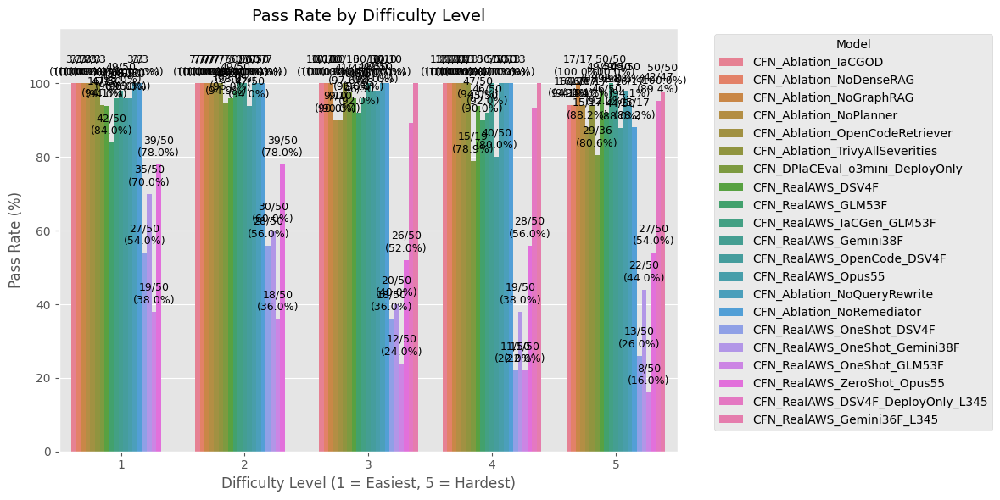

None

In [5]:
def _plot_pass_rate_by_difficulty(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    difficulty_stats = []

    print("📊 Overall Pass Rates:")
    for model_name, df in dfs.items():
        diff_col = 'difficulty_level' if 'difficulty_level' in df.columns else 'difficulty'
        val_col = 'final_validation_passed' if 'final_validation_passed' in df.columns else ('deploy_pass' if 'deploy_pass' in df.columns else None)

        if diff_col in df.columns and val_col in df.columns:
            total_passed = int(df[val_col].sum())
            total_scenarios = len(df)
            overall_rate = (total_passed / total_scenarios * 100) if total_scenarios > 0 else 0
            print(f"  -> {model_name}: {total_passed}/{total_scenarios} ({overall_rate:.1f}%)")

            grouped = df.groupby(diff_col)[val_col].agg(['sum', 'count', 'mean'])

            for diff, row in grouped.iterrows():
                passed_cnt = int(row['sum'])
                total_cnt = int(row['count'])
                rate = row['mean'] * 100

                difficulty_stats.append({
                    'Model': model_name,
                    'Difficulty Level': diff,
                    'Passed': passed_cnt,
                    'Total': total_cnt,
                    'Pass Rate (%)': rate
                })

    if difficulty_stats:
        diff_df = pd.DataFrame(difficulty_stats)

        plt.figure(figsize=(12, 6))
        ax = sns.barplot(data=diff_df, x='Difficulty Level', y='Pass Rate (%)', hue='Model')

        plt.title('Pass Rate by Difficulty Level', fontsize=14)
        plt.ylim(0, 115)
        plt.xlabel('Difficulty Level (1 = Easiest, 5 = Hardest)')
        plt.ylabel('Pass Rate (%)')

        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')

        for i, container in enumerate(ax.containers):
            model_name = ax.get_legend().get_texts()[i].get_text()

            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or (height == 0 and p.get_y() == 0):
                    continue

                diff_level = ax.get_xticklabels()[j].get_text()

                row = diff_df[(diff_df['Model'] == model_name) & (diff_df['Difficulty Level'].astype(str) == diff_level)]

                if not row.empty:
                    passed = row['Passed'].values[0]
                    total = row['Total'].values[0]
                    rate = row['Pass Rate (%)'].values[0]

                    label_text = f"{passed}/{total}\n({rate:.1f}%)"

                    ax.annotate(label_text, 
                                (p.get_x() + p.get_width() / 2., height), 
                                ha='center', va='bottom', 
                                xytext=(0, 5), textcoords='offset points',
                                fontsize=9)

        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ Could not find difficulty or validation columns to plot Pass Rate.")

_out_pass_rate_by_difficulty = widgets.interactive_output(_plot_pass_rate_by_difficulty, {'selected_models': model_selector})
display(_out_pass_rate_by_difficulty)

📊 Calculating Cumulative Pass Rates by Iteration Milestones...





None

In [6]:
def _plot_pass_at_n(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    target_iterations = [1, 5, 10, 15]
    iteration_stats = []

    print("📊 Calculating Cumulative Pass Rates by Iteration Milestones...")
    for model_name, df in dfs.items():
        diff_col = 'difficulty_level' if 'difficulty_level' in df.columns else 'difficulty'
        val_col = 'final_validation_passed' if 'final_validation_passed' in df.columns else ('deploy_pass' if 'deploy_pass' in df.columns else None)
        iter_col = 'iterations_used'

        if diff_col in df.columns and val_col in df.columns and iter_col in df.columns:
            df[iter_col] = pd.to_numeric(df[iter_col], errors='coerce')

            for diff in sorted(df[diff_col].dropna().unique()):
                subset = df[df[diff_col] == diff]
                total_in_diff = len(subset)

                if total_in_diff == 0:
                    continue

                for t_iter in target_iterations:
                    passed_subset = subset[(subset[val_col] == 1) & (subset[iter_col] <= t_iter)]
                    pass_rate = (len(passed_subset) / total_in_diff) * 100

                    iteration_stats.append({
                        'Model': model_name,
                        'Difficulty Level': str(diff),
                        'Iteration Limit': f'≤ {t_iter}',
                        'Iteration_Num': t_iter,
                        'Pass Rate (%)': pass_rate
                    })
        else:
            print(f"⚠️ Missing required columns for model {model_name}. Need difficulty, validation, and 'iterations_used'.")

    if iteration_stats:
        iter_df = pd.DataFrame(iteration_stats).sort_values(by=['Model', 'Difficulty Level', 'Iteration_Num'])

        g = sns.catplot(
            data=iter_df, 
            kind="point",
            x="Iteration Limit", 
            y="Pass Rate (%)", 
            hue="Difficulty Level", 
            col="Model",
            palette="viridis", 
            height=5.5, 
            aspect=1.3,
            markers=["o", "s", "D", "^", "v"][:len(iter_df['Difficulty Level'].unique())],
            linestyles="-"
        )

        g.set_axis_labels("Iteration Milestones", "Cumulative Pass Rate (%)")
        g.set(ylim=(-5, 105))
        g.fig.suptitle('Cumulative Pass Rate by Iteration Milestones (Actual LLM Effort)', fontsize=16, y=1.05)

        for ax in g.axes.flat:
            for line in ax.lines:
                if len(line.get_xdata()) > 0:
                    x_last = line.get_xdata()[-1]
                    y_last = line.get_ydata()[-1]
                    if pd.notna(y_last):
                        ax.annotate(
                            f'{y_last:.1f}%', 
                            xy=(x_last, y_last), 
                            xytext=(10, 0),
                            textcoords='offset points',
                            ha='left', va='center',
                            fontsize=9,
                            fontweight='bold'
                        )

        plt.show()
    else:
        print("⚠️ No valid data processed for iteration milestones.")

_out_pass_at_n = widgets.interactive_output(_plot_pass_at_n, {'selected_models': model_selector})
display(_out_pass_at_n)

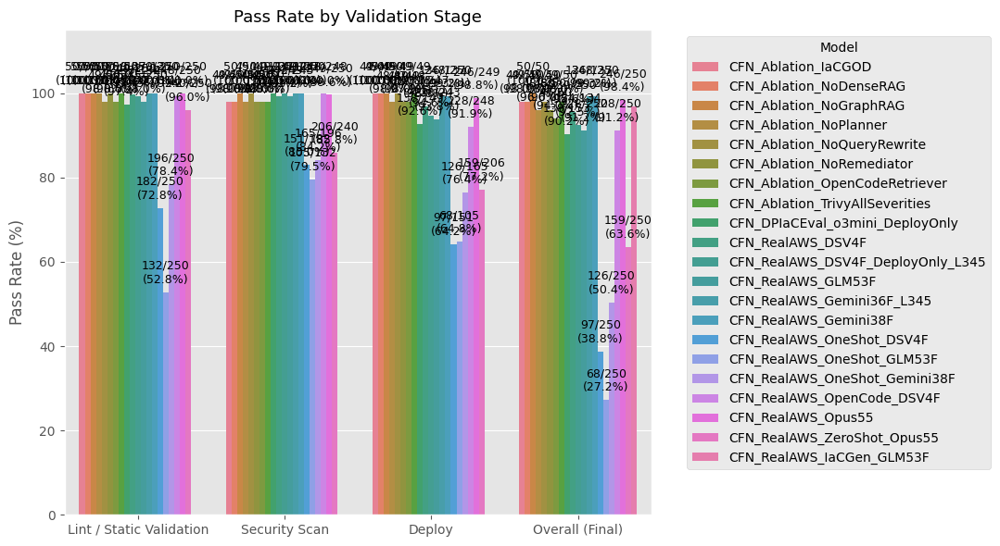

📊 Stage pass rates -- 'Total' is scenarios that actually reached that stage (excludes ones an earlier gate already skipped them past):


,Model,Stage,Passed,Total,Pass Rate (%)
0,CFN_Ablation_IaCGOD,Lint / Static Validation,50,50,100.0
1,CFN_Ablation_NoDenseRAG,Lint / Static Validation,50,50,100.0
2,CFN_Ablation_NoGraphRAG,Lint / Static Validation,50,50,100.0
3,CFN_Ablation_NoPlanner,Lint / Static Validation,50,50,100.0
4,CFN_Ablation_NoQueryRewrite,Lint / Static Validation,49,50,98.0
...,...,...,...,...,...
76,CFN_RealAWS_OneShot_GLM53F,Overall (Final),68,250,27.2
77,CFN_RealAWS_OneShot_Gemini38F,Overall (Final),126,250,50.4
78,CFN_RealAWS_OpenCode_DSV4F,Overall (Final),228,250,91.2
79,CFN_RealAWS_Opus55,Overall (Final),246,250,98.4


None

In [7]:
STAGE_CONFIG = [
    {"key": "yaml",     "label": "YAML",           "all_col": "all_yaml_errors",     "latest_col": "latest_error_yaml",     "passed_col": "val_stage_yaml_passed"},
    {"key": "cfn-lint", "label": "cfn-lint",        "all_col": "all_cfn_lint_errors", "latest_col": "latest_error_cfn-lint", "passed_col": "val_stage_cfn-lint_passed"},
    {"key": "trivy",    "label": "Trivy/Security",  "all_col": "all_security_errors", "latest_col": "latest_error_trivy",   "passed_col": "val_stage_trivy_passed"},
]
def _plot_pass_rate_by_stage(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}

    lint_keys = [s["key"] for s in STAGE_CONFIG if s["key"] != "trivy"]
    security_keys = [s["key"] for s in STAGE_CONFIG if s["key"] == "trivy"]
    stage_col_map = {s["key"]: s["passed_col"] for s in STAGE_CONFIG}

    def stage_rate(df: pd.DataFrame, keys: list, gate_keys: list = None):
        cols = [stage_col_map[k] for k in keys if stage_col_map[k] in df.columns]
        if not cols:
            return None, None
        reached = df[cols].notna().all(axis=1)
        if gate_keys:
            gate_cols = [stage_col_map[k] for k in gate_keys if stage_col_map[k] in df.columns]
            if gate_cols:
                reached = reached & df[gate_cols].eq(True).all(axis=1)
        passed = reached & df[cols].eq(True).all(axis=1)
        return int(passed.sum()), int(reached.sum())

    stage_pass_rows = []
    for model_name, df in dfs.items():
        for label, keys, gate in [
            ("Lint / Static Validation", lint_keys, None),
            ("Security Scan", security_keys, lint_keys),
        ]:
            p, t = stage_rate(df, keys, gate_keys=gate)
            if t:
                stage_pass_rows.append({"Model": model_name, "Stage": label, "Passed": p, "Total": t, "Pass Rate (%)": p / t * 100})

        if "deploy_passed" in df.columns:
            gate_cols = [stage_col_map[k] for k in (lint_keys + security_keys) if stage_col_map[k] in df.columns]
            reached = df[gate_cols].eq(True).all(axis=1) if gate_cols else pd.Series(True, index=df.index)
            if "deploy_target" in df.columns:
                reached = reached & (df["deploy_target"] != "skipped")
            passed = reached & (df["deploy_passed"] == True)
            t = int(reached.sum())
            if t:
                stage_pass_rows.append({"Model": model_name, "Stage": "Deploy", "Passed": int(passed.sum()), "Total": t, "Pass Rate (%)": passed.sum() / t * 100})

        if "final_validation_passed" in df.columns:
            s = df["final_validation_passed"]
            t = int(s.notna().sum())
            if t:
                stage_pass_rows.append({"Model": model_name, "Stage": "Overall (Final)", "Passed": int((s == True).sum()), "Total": t, "Pass Rate (%)": (s == True).sum() / t * 100})

    if stage_pass_rows:
        stage_df = pd.DataFrame(stage_pass_rows)
        stage_order = ["Lint / Static Validation", "Security Scan", "Deploy", "Overall (Final)"]
        stage_df["Stage"] = pd.Categorical(stage_df["Stage"], categories=stage_order, ordered=True)
        stage_df = stage_df.sort_values(["Stage", "Model"])

        plt.figure(figsize=(11, 6))
        ax = sns.barplot(data=stage_df, x="Stage", y="Pass Rate (%)", hue="Model", order=stage_order)
        plt.title("Pass Rate by Validation Stage", fontsize=13)
        plt.ylim(0, 115)
        plt.xlabel("")
        plt.ylabel("Pass Rate (%)")
        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")

        for i, container in enumerate(ax.containers):
            model_name = ax.get_legend().get_texts()[i].get_text()
            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or (height == 0 and p.get_y() == 0):
                    continue
                stage_label = ax.get_xticklabels()[j].get_text()
                row = stage_df[(stage_df["Model"] == model_name) & (stage_df["Stage"].astype(str) == stage_label)]
                if not row.empty:
                    passed = row["Passed"].values[0]
                    total = row["Total"].values[0]
                    rate = row["Pass Rate (%)"].values[0]
                    ax.annotate(f"{passed}/{total}\n({rate:.1f}%)",
                                (p.get_x() + p.get_width() / 2., height),
                                ha="center", va="bottom", xytext=(0, 5),
                                textcoords="offset points", fontsize=9)

        plt.tight_layout()
        plt.show()

        print("📊 Stage pass rates -- 'Total' is scenarios that actually reached that stage "
              "(excludes ones an earlier gate already skipped them past):")
        display(stage_df[["Model", "Stage", "Passed", "Total", "Pass Rate (%)"]]
                .sort_values(["Stage", "Model"]).round(1).reset_index(drop=True))
    else:
        print("⚠️ No stage-level pass/fail columns found.")

_out_pass_rate_by_stage = widgets.interactive_output(_plot_pass_rate_by_stage, {'selected_models': model_selector})
display(_out_pass_rate_by_stage)

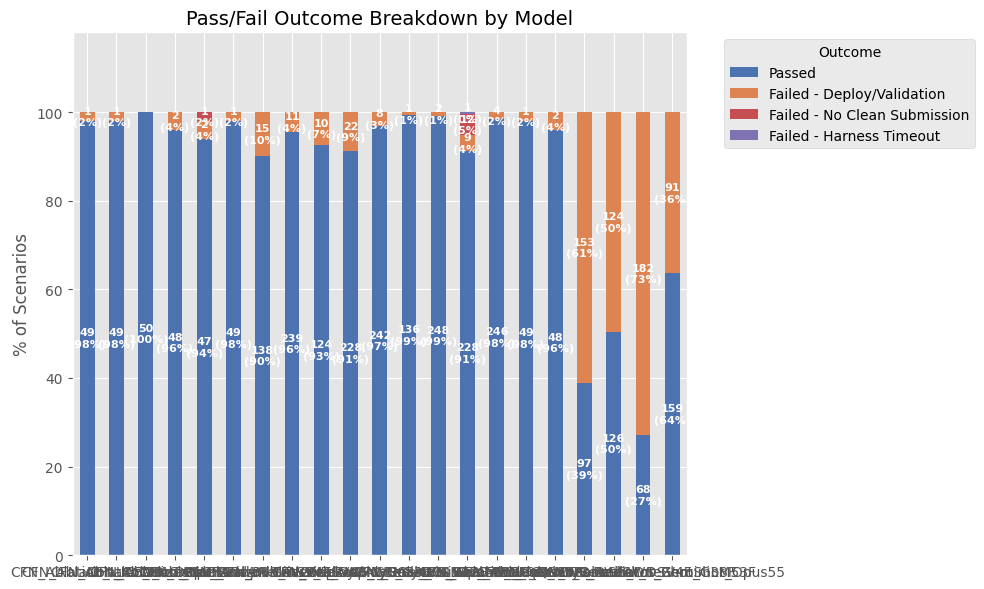

📊 Pass/Fail Outcome Breakdown (counts):


Outcome,Passed,Failed - Deploy/Validation,Failed - No Clean Submission,Failed - Harness Timeout
Model,,,,
CFN_Ablation_IaCGOD,49,1,0,0
CFN_Ablation_NoDenseRAG,49,1,0,0
CFN_Ablation_NoGraphRAG,50,0,0,0
CFN_Ablation_NoPlanner,48,2,0,0
CFN_Ablation_OpenCodeRetriever,47,2,1,0
CFN_Ablation_TrivyAllSeverities,49,1,0,0
CFN_DPIaCEval_o3mini_DeployOnly,138,15,0,0
CFN_RealAWS_DSV4F,239,11,0,0
CFN_RealAWS_DSV4F_DeployOnly_L345,124,10,0,0


None

In [8]:
def _plot_outcome_breakdown(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    def _classify_outcome(row):
        if row.get('final_validation_passed') == True:
            return 'Passed'
        if row.get('status') == 'harness_timeout':
            return 'Failed - Harness Timeout'
        if 'submitted_by_harness' in row.index and row.get('submitted_by_harness') == False:
            return 'Failed - No Clean Submission'
        return 'Failed - Deploy/Validation'

    breakdown_rows = []
    for model_name, df in dfs.items():
        if 'final_validation_passed' not in df.columns:
            print(f"⚠️ Skipping {model_name}: no final_validation_passed column.")
            continue
        outcomes = df.apply(_classify_outcome, axis=1)
        counts = outcomes.value_counts()
        total = len(df)
        for outcome, cnt in counts.items():
            breakdown_rows.append({
                'Model': model_name,
                'Outcome': outcome,
                'Count': int(cnt),
                'Pct': cnt / total * 100,
            })

    if breakdown_rows:
        breakdown_df = pd.DataFrame(breakdown_rows)

        outcome_order = [
            'Passed',
            'Failed - Deploy/Validation',
            'Failed - No Clean Submission',
            'Failed - Harness Timeout',
        ]
        outcome_colors = {
            'Passed': '#4C72B0',
            'Failed - Deploy/Validation': '#DD8452',
            'Failed - No Clean Submission': '#C44E52',
            'Failed - Harness Timeout': '#8172B2',
        }
        present_outcomes = [o for o in outcome_order if o in breakdown_df['Outcome'].unique()]

        pivot = (
            breakdown_df.pivot(index='Model', columns='Outcome', values='Pct')
            .reindex(columns=present_outcomes)
            .fillna(0)
            .reindex(dfs.keys())
        )
        count_pivot = (
            breakdown_df.pivot(index='Model', columns='Outcome', values='Count')
            .reindex(columns=present_outcomes)
            .fillna(0)
            .astype(int)
            .reindex(dfs.keys())
        )

        ax = pivot.plot(
            kind='bar', stacked=True, figsize=(10, 6),
            color=[outcome_colors[o] for o in present_outcomes],
        )
        plt.title('Pass/Fail Outcome Breakdown by Model', fontsize=14)
        plt.ylabel('% of Scenarios')
        plt.xlabel('')
        plt.xticks(rotation=0)
        plt.ylim(0, 118)
        plt.legend(title='Outcome', bbox_to_anchor=(1.05, 1), loc='upper left')

        for container, outcome in zip(ax.containers, present_outcomes):
            for i, patch in enumerate(container):
                model_name = pivot.index[i]
                pct = pivot.loc[model_name, outcome]
                if pct <= 0:
                    continue
                cnt = count_pivot.loc[model_name, outcome]
                height = patch.get_height()
                y = patch.get_y() + height / 2
                ax.annotate(
                    f'{cnt}\n({pct:.0f}%)',
                    (patch.get_x() + patch.get_width() / 2, y),
                    ha='center', va='center', fontsize=8, color='white', fontweight='bold',
                )

        plt.tight_layout()
        plt.show()

        print('📊 Pass/Fail Outcome Breakdown (counts):')
        display(count_pivot)
    else:
        print('⚠️ No final_validation_passed column found for any model.')

_out_outcome_breakdown = widgets.interactive_output(_plot_outcome_breakdown, {'selected_models': model_selector})
display(_out_outcome_breakdown)

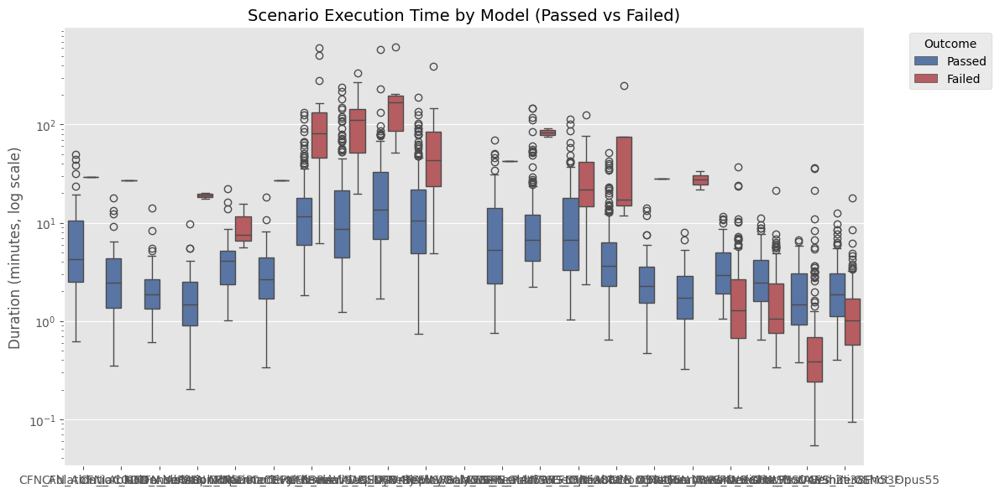

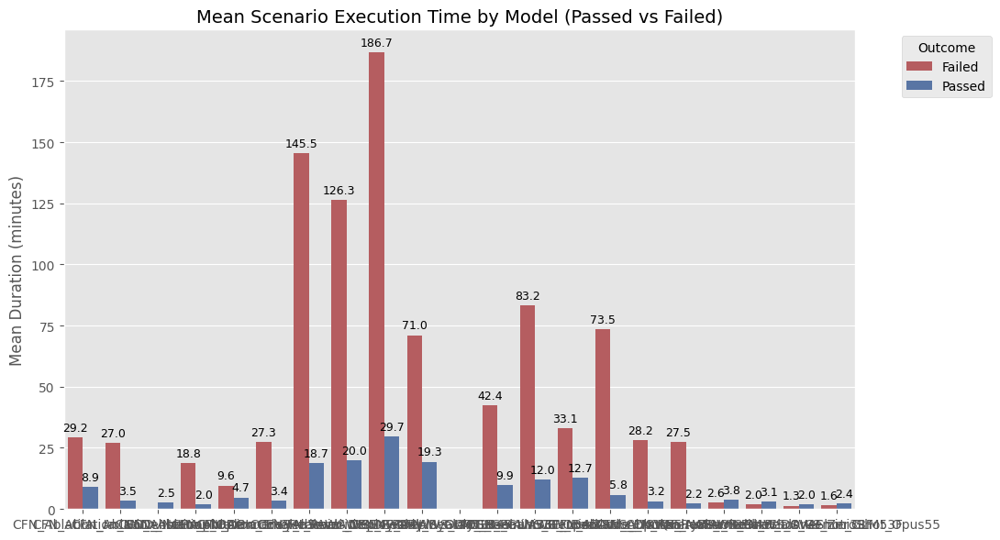

📊 Mean/Median Execution Time (minutes) by Model and Outcome:


mean  median  count
Model                             Outcome                      
CFN_Ablation_IaCGOD               Failed    29.2    29.2      1
                                  Passed     8.9     4.3     49
CFN_Ablation_NoDenseRAG           Failed    27.0    27.0      1
                                  Passed     3.5     2.4     49
CFN_Ablation_NoGraphRAG           Passed     2.5     1.9     50
CFN_Ablation_NoPlanner            Failed    18.8    18.8      2
                                  Passed     2.0     1.5     48
CFN_Ablation_OpenCodeRetriever    Failed     9.6     7.6      3
                                  Passed     4.7     4.1     47
CFN_Ablation_TrivyAllSeverities   Failed    27.3    27.3      1
                                  Passed     3.4     2.7     49
CFN_DPIaCEval_o3mini_DeployOnly   Failed   145.5    81.4     15
                                  Passed    18.7    11.5    138
CFN_RealAWS_DSV4F                 Failed   126.3   112.3     11
                                  Passed    20.0     8.6    239
CFN_RealAWS_DSV4F_DeployOnly_L345 Failed   186.7   167.5     10
                                  Passed    29.7    13.5    124
CFN_RealAWS_GLM53F                Failed    71.0    43.6     22
                                  Passed    19.3    10.4    228
CFN_RealAWS_Gemini36F_L345        Failed    42.4    42.4      1
                                  Passed     9.9     5.2    136
CFN_RealAWS_Gemini38F             Failed    83.2    83.2      2
                                  Passed    12.0     6.7    248
CFN_RealAWS_OpenCode_DSV4F        Failed    33.1    21.9     22
                                  Passed    12.7     6.8    228
CFN_RealAWS_Opus55                Failed    73.5    17.0      4
                                  Passed     5.8     3.7    246
CFN_Ablation_NoQueryRewrite       Failed    28.2    28.2      1
                                  Passed     3.2     2.3     49
CFN_Ablation_NoRemediator         Failed    27.5    27.5      2
                                  Passed     2.2     1.7     48
CFN_RealAWS_OneShot_DSV4F         Failed     2.6     1.3    153
                                  Passed     3.8     3.0     97
CFN_RealAWS_OneShot_Gemini38F     Failed     2.0     1.1    124
                                  Passed     3.1     2.5    126
CFN_RealAWS_OneShot_GLM53F        Failed     1.3     0.4    182
                                  Passed     2.0     1.5     68
CFN_RealAWS_ZeroShot_Opus55       Failed     1.6     1.0     91
                                  Passed     2.4     1.9    159

None

In [9]:
def _plot_execution_time(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    duration_rows = []
    for model_name, df in dfs.items():
        if 'duration_seconds' not in df.columns or 'final_validation_passed' not in df.columns:
            print(f"⚠️ Skipping {model_name}: missing duration_seconds or final_validation_passed.")
            continue
        sub = df[['duration_seconds', 'final_validation_passed']].dropna(subset=['duration_seconds']).copy()
        sub['Model'] = model_name
        sub['Outcome'] = sub['final_validation_passed'].map({True: 'Passed', False: 'Failed'})
        sub['Duration (min)'] = sub['duration_seconds'] / 60.0
        duration_rows.append(sub[['Model', 'Outcome', 'Duration (min)']])

    if duration_rows:
        duration_df = pd.concat(duration_rows, ignore_index=True)
        model_order = list(dfs.keys())

        plt.figure(figsize=(12, 6))
        ax = sns.boxplot(
            data=duration_df, x='Model', y='Duration (min)', hue='Outcome',
            palette={'Passed': '#4C72B0', 'Failed': '#C44E52'}, order=model_order,
        )
        ax.set_yscale('log')
        plt.title('Scenario Execution Time by Model (Passed vs Failed)', fontsize=14)
        plt.ylabel('Duration (minutes, log scale)')
        plt.xlabel('')
        plt.legend(title='Outcome', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

        mean_df = duration_df.groupby(['Model', 'Outcome'], as_index=False)['Duration (min)'].mean()
        plt.figure(figsize=(11, 6))
        ax2 = sns.barplot(
            data=mean_df, x='Model', y='Duration (min)', hue='Outcome',
            palette={'Passed': '#4C72B0', 'Failed': '#C44E52'}, order=model_order,
        )
        plt.title('Mean Scenario Execution Time by Model (Passed vs Failed)', fontsize=14)
        plt.ylabel('Mean Duration (minutes)')
        plt.xlabel('')
        plt.legend(title='Outcome', bbox_to_anchor=(1.05, 1), loc='upper left')
        for container in ax2.containers:
            ax2.bar_label(container, fmt='%.1f', fontsize=9, padding=3)
        plt.tight_layout()
        plt.show()

        print('📊 Mean/Median Execution Time (minutes) by Model and Outcome:')
        summary = (
            duration_df.groupby(['Model', 'Outcome'])['Duration (min)']
            .agg(['mean', 'median', 'count'])
            .round(1)
            .reindex(model_order, level='Model')
        )
        display(summary)
    else:
        print('⚠️ No duration_seconds data found for any model.')

_out_execution_time = widgets.interactive_output(_plot_execution_time, {'selected_models': model_selector})
display(_out_execution_time)

📊 Cross-Model Scenario Resolution (417 scenarios total):
  Scenarios with >=1 model failure       : 223
    -> resolved by >=1 other model        : 208
    -> failed by EVERY model that ran it   : 15 (possible benchmark issue -- worth a manual look)



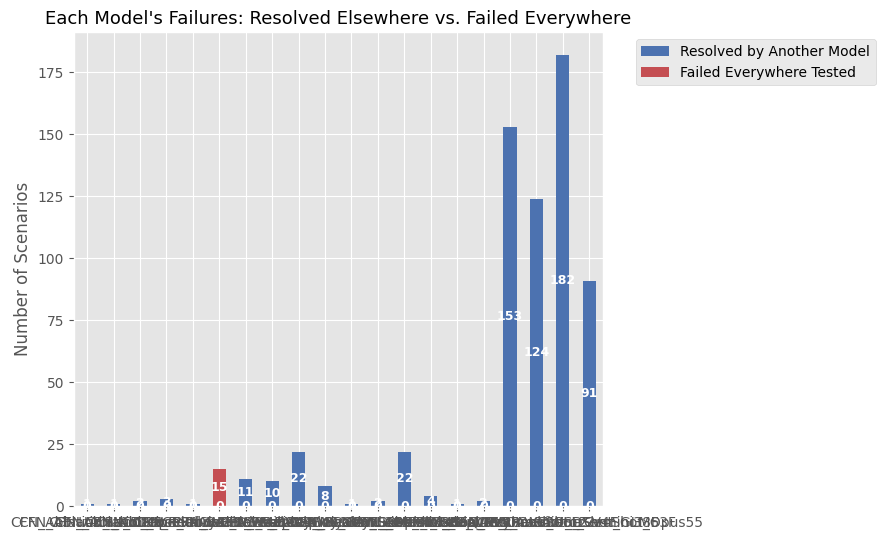

📊 Per-model failure resolution:


,Model,Total Failures,Resolved by Another Model,Failed Everywhere Tested
0,CFN_Ablation_IaCGOD,1,1,0
1,CFN_Ablation_NoDenseRAG,1,1,0
2,CFN_Ablation_NoPlanner,2,2,0
3,CFN_Ablation_OpenCodeRetriever,3,3,0
4,CFN_Ablation_TrivyAllSeverities,1,1,0
5,CFN_DPIaCEval_o3mini_DeployOnly,15,0,15
6,CFN_RealAWS_DSV4F,11,11,0
7,CFN_RealAWS_DSV4F_DeployOnly_L345,10,10,0
8,CFN_RealAWS_GLM53F,22,22,0
9,CFN_RealAWS_IaCGen_GLM53F,8,8,0


/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/2325777872.py:110: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = num.replace({True: 1, False: 0}).fillna(-1).astype(float)


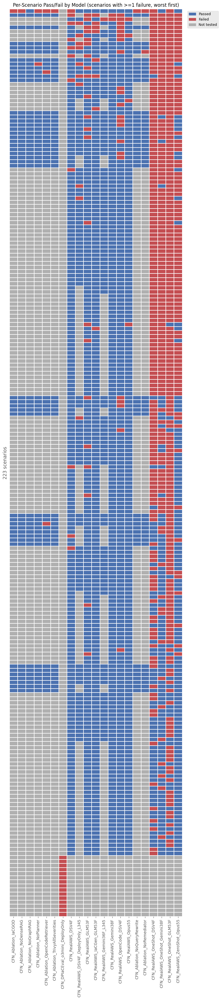

⚠️ 15 scenario(s) failed by every model that ran them:


,n_tested,n_failed,difficulty,prompt_snippet
ground_truth_path,,,,
Data\groud_truth\template\BashScriptSSMAutomation.yaml,1,1,4,We need a CloudFormation template that creates an EC2 in...
Data\groud_truth\template\CPUStressInstances.yaml,1,1,5,We need a CloudFormation template that creates a Windows...
Data\groud_truth\template\RDS_Snapshot_On_Delete.yaml,1,1,5,We need a CloudFormation template that creates MySQL RDS...
Data\groud_truth\template\RDS_with_DBParameterGroup.yaml,1,1,2,We need a CloudFormation template that creates a MySQL R...
Data\groud_truth\template\account-password-policy.yaml,1,1,5,We need a CloudFormation template that creates and manag...
Data\groud_truth\template\b2bi.yaml,1,1,3,We need a CloudFormation template that creates an AWS B2...
Data\groud_truth\template\codedeploy.yaml,1,1,5,We need a CloudFormation template that creates an automa...
Data\groud_truth\template\config.yaml,1,1,5,We need a CloudFormation template that creates a secure ...
Data\groud_truth\template\crossAccResources.yaml,1,1,4,We need a CloudFormation template that creates a cross-a...


None

In [10]:
def _plot_cross_model_resolution(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    GT_COL = 'ground_truth_path'
    model_order = list(dfs.keys())

    pass_series = {}
    difficulty_by_gt = {}
    prompt_by_gt = {}
    for model_name, df in dfs.items():
        if GT_COL not in df.columns or 'final_validation_passed' not in df.columns:
            print(f"⚠️ Skipping {model_name}: missing {GT_COL} or final_validation_passed.")
            continue
        pass_series[model_name] = df.set_index(GT_COL)['final_validation_passed'].map({True: True, False: False})

        diff_col = 'difficulty_level' if 'difficulty_level' in df.columns else ('difficulty' if 'difficulty' in df.columns else None)
        if diff_col:
            for gt, d in zip(df[GT_COL], df[diff_col]):
                difficulty_by_gt.setdefault(gt, d)
        if 'prompt' in df.columns:
            for gt, p in zip(df[GT_COL], df['prompt']):
                prompt_by_gt.setdefault(gt, p)

    if pass_series:
        pass_matrix = pd.DataFrame(pass_series)
        pass_matrix = pass_matrix[[m for m in model_order if m in pass_matrix.columns]]

        n_tested = pass_matrix.notna().sum(axis=1)
        n_failed = (pass_matrix == False).sum(axis=1)
        n_passed = (pass_matrix == True).sum(axis=1)

        any_failure = pass_matrix.loc[n_failed > 0].copy()
        any_failure['n_tested'] = n_tested[n_failed > 0]
        any_failure['n_failed'] = n_failed[n_failed > 0]
        any_failure['n_passed'] = n_passed[n_failed > 0]
        any_failure['resolved_elsewhere'] = any_failure['n_passed'] > 0
        any_failure = any_failure.sort_values(['n_failed', 'n_tested'], ascending=[False, False])

        n_scenarios_with_failure = len(any_failure)
        n_resolved_elsewhere = int(any_failure['resolved_elsewhere'].sum())
        n_failed_everywhere = n_scenarios_with_failure - n_resolved_elsewhere

        print(f"📊 Cross-Model Scenario Resolution ({len(pass_matrix)} scenarios total):")
        print(f"  Scenarios with >=1 model failure       : {n_scenarios_with_failure}")
        print(f"    -> resolved by >=1 other model        : {n_resolved_elsewhere}")
        print(f"    -> failed by EVERY model that ran it   : {n_failed_everywhere} "
              f"{'(possible benchmark issue -- worth a manual look)' if n_failed_everywhere else ''}")
        print()

        resolve_rows = []
        for model_name in pass_matrix.columns:
            model_failed_mask = pass_matrix[model_name] == False
            failed_gts = pass_matrix.index[model_failed_mask]
            if len(failed_gts) == 0:
                continue
            sub = any_failure.loc[failed_gts]
            resolved = int(sub['resolved_elsewhere'].sum())
            unresolved = int((~sub['resolved_elsewhere']).sum())
            resolve_rows.append({
                'Model': model_name,
                'Total Failures': len(failed_gts),
                'Resolved by Another Model': resolved,
                'Failed Everywhere Tested': unresolved,
            })
        resolve_df = pd.DataFrame(resolve_rows)

        if not resolve_df.empty:
            plot_df = resolve_df.set_index('Model')[['Resolved by Another Model', 'Failed Everywhere Tested']]
            plot_df = plot_df.reindex([m for m in model_order if m in plot_df.index])
            ax = plot_df.plot(kind='bar', stacked=True, figsize=(9, 5.5),
                               color=['#4C72B0', '#C44E52'])
            plt.title("Each Model's Failures: Resolved Elsewhere vs. Failed Everywhere", fontsize=13)
            plt.ylabel('Number of Scenarios')
            plt.xlabel('')
            plt.xticks(rotation=0)
            plt.legend(title='', bbox_to_anchor=(1.05, 1), loc='upper left')
            for container in ax.containers:
                ax.bar_label(container, label_type='center', fontsize=9, color='white', fontweight='bold')
            plt.tight_layout()
            plt.show()

            print('📊 Per-model failure resolution:')
            display(resolve_df)

        if n_scenarios_with_failure:
            num = any_failure[model_order].reindex(columns=[m for m in model_order if m in any_failure.columns])
            num = num.replace({True: 1, False: 0}).fillna(-1).astype(float)

            import matplotlib as mpl
            cmap = mpl.colors.ListedColormap(['#B0B0B0', '#C44E52', '#4C72B0'])
            norm = mpl.colors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)

            fig_h = max(6, 0.16 * len(num))
            plt.figure(figsize=(8, fig_h))
            ax = sns.heatmap(num, cmap=cmap, norm=norm, cbar=False, yticklabels=False,
                              linewidths=0.3, linecolor='white')
            plt.title('Per-Scenario Pass/Fail by Model (scenarios with >=1 failure, worst first)', fontsize=12)
            plt.xlabel('')
            plt.ylabel(f'{len(num)} scenarios')
            legend_handles = [
                mpl.patches.Patch(color='#4C72B0', label='Passed'),
                mpl.patches.Patch(color='#C44E52', label='Failed'),
                mpl.patches.Patch(color='#B0B0B0', label='Not tested'),
            ]
            plt.legend(handles=legend_handles, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
            plt.tight_layout()
            plt.show()

        if n_scenarios_with_failure:
            top_hard = any_failure[any_failure['resolved_elsewhere'] == False].copy()
            if top_hard.empty:
                print('✅ Every failing scenario was resolved by at least one other model -- '
                      'no scenario failed universally.')
            else:
                top_hard['difficulty'] = [difficulty_by_gt.get(gt) for gt in top_hard.index]
                top_hard['prompt_snippet'] = [str(prompt_by_gt.get(gt, ''))[:100] for gt in top_hard.index]
                print(f"⚠️ {len(top_hard)} scenario(s) failed by every model that ran them:")
                with pd.option_context('display.max_colwidth', 60, 'display.width', 220):
                    display(top_hard[['n_tested', 'n_failed', 'difficulty', 'prompt_snippet']])
    else:
        print('⚠️ No models had both ground_truth_path and final_validation_passed columns.')

_out_cross_model_resolution = widgets.interactive_output(_plot_cross_model_resolution, {'selected_models': model_selector})
display(_out_cross_model_resolution)

📊 Scenarios reaching a real deploy attempt, by model:


Outcome,Resolved,Unresolved
Model,,
CFN_Ablation_IaCGOD,NaN,NaN
CFN_Ablation_NoDenseRAG,NaN,NaN
CFN_Ablation_NoGraphRAG,NaN,NaN
CFN_Ablation_NoPlanner,NaN,NaN
CFN_Ablation_OpenCodeRetriever,NaN,NaN
CFN_Ablation_TrivyAllSeverities,NaN,NaN
CFN_DPIaCEval_o3mini_DeployOnly,138.0,11.0
CFN_RealAWS_DSV4F,239.0,8.0
CFN_RealAWS_DSV4F_DeployOnly_L345,124.0,9.0



📊 Of those, 1547 scenario-runs had ZERO yaml/cfn-lint/security errors across every iteration -- their entire iteration count is purely deploy-remediation:


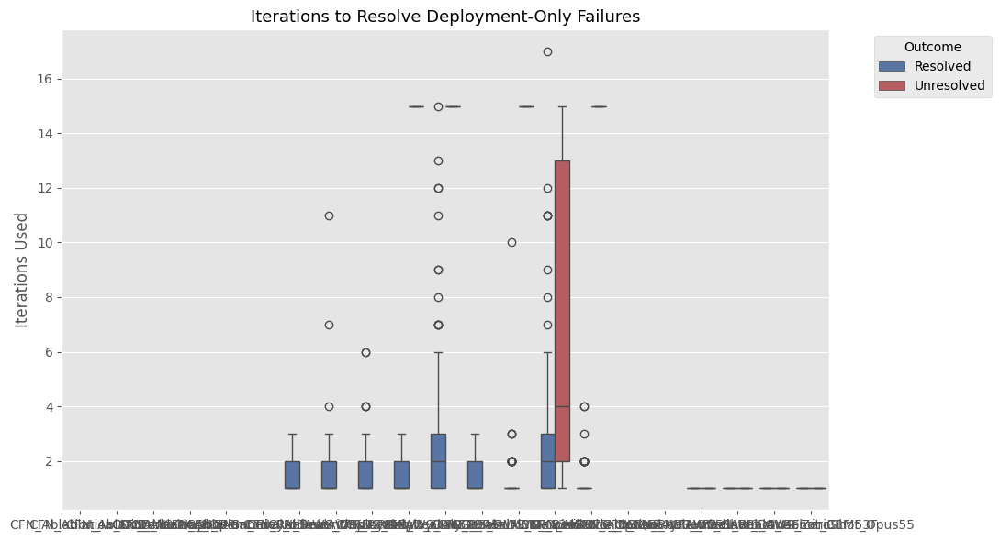

📊 Iterations to resolve deployment-only failures (mean/median/max, by model and outcome):


count   mean  median   max
Model                             Outcome                               
CFN_DPIaCEval_o3mini_DeployOnly   Resolved       44   1.30     1.0   3.0
CFN_RealAWS_DSV4F                 Resolved       65   1.65     1.0  11.0
CFN_RealAWS_DSV4F_DeployOnly_L345 Resolved       42   1.71     1.0   6.0
CFN_RealAWS_GLM53F                Resolved       51   1.43     1.0   3.0
                                  Unresolved      1  15.00    15.0  15.0
CFN_RealAWS_IaCGen_GLM53F         Resolved      242   2.53     2.0  15.0
                                  Unresolved      8  15.00    15.0  15.0
CFN_RealAWS_Gemini36F_L345        Resolved       56   1.43     1.0   3.0
CFN_RealAWS_Gemini38F             Resolved      140   1.27     1.0  10.0
                                  Unresolved      1  15.00    15.0  15.0
CFN_RealAWS_OpenCode_DSV4F        Resolved      184   2.68     2.0  17.0
                                  Unresolved     15   6.80     4.0  15.0
CFN_RealAWS_Opus55                Resolved      168   1.14     1.0   4.0
                                  Unresolved      2  15.00    15.0  15.0
CFN_RealAWS_OneShot_DSV4F         Resolved       82   1.00     1.0   1.0
                                  Unresolved     39   1.00     1.0   1.0
CFN_RealAWS_OneShot_Gemini38F     Resolved      113   1.00     1.0   1.0
                                  Unresolved     30   1.00     1.0   1.0
CFN_RealAWS_OneShot_GLM53F        Resolved       57   1.00     1.0   1.0
                                  Unresolved     17   1.00     1.0   1.0
CFN_RealAWS_ZeroShot_Opus55       Resolved      149   1.00     1.0   1.0
                                  Unresolved     41   1.00     1.0   1.0

📊 Resolved on the very first deploy attempt vs. needed further remediation iterations:


,deploy_only_scenarios,resolved,resolved_on_first_try,needed_remediation
Model,,,,
CFN_Ablation_IaCGOD,NaN,NaN,NaN,NaN
CFN_Ablation_NoDenseRAG,NaN,NaN,NaN,NaN
CFN_Ablation_NoGraphRAG,NaN,NaN,NaN,NaN
CFN_Ablation_NoPlanner,NaN,NaN,NaN,NaN
CFN_Ablation_OpenCodeRetriever,NaN,NaN,NaN,NaN
CFN_Ablation_TrivyAllSeverities,NaN,NaN,NaN,NaN
CFN_DPIaCEval_o3mini_DeployOnly,44.0,44.0,32.0,12.0
CFN_RealAWS_DSV4F,65.0,65.0,45.0,20.0
CFN_RealAWS_DSV4F_DeployOnly_L345,42.0,42.0,27.0,15.0


None

In [11]:
def _plot_iterations_to_resolve_deploy(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    DEPLOY_ITER_COLS = ['deploy_target', 'deploy_passed', 'iterations_used',
                         'total_yaml_errors', 'total_cfn_lint_errors', 'total_security_errors']

    deploy_only_rows = []
    reached_deploy_rows = []
    for model_name, df in dfs.items():
        if not all(c in df.columns for c in DEPLOY_ITER_COLS):
            print(f"⚠️ Skipping {model_name}: missing one of {DEPLOY_ITER_COLS}.")
            continue

        reached = df['deploy_target'] == 'aws'
        non_deploy_error_total = (
            df['total_yaml_errors'].fillna(0)
            + df['total_cfn_lint_errors'].fillna(0)
            + df['total_security_errors'].fillna(0)
        )
        deploy_only_mask = reached & (non_deploy_error_total == 0)

        reached_sub = df[reached].copy()
        reached_sub['Model'] = model_name
        reached_sub['Outcome'] = reached_sub['deploy_passed'].map({True: 'Resolved', False: 'Unresolved'})
        reached_deploy_rows.append(reached_sub[['Model', 'Outcome', 'iterations_used']])

        deploy_only_sub = df[deploy_only_mask].copy()
        deploy_only_sub['Model'] = model_name
        deploy_only_sub['Outcome'] = deploy_only_sub['deploy_passed'].map({True: 'Resolved', False: 'Unresolved'})
        deploy_only_rows.append(deploy_only_sub[['Model', 'Outcome', 'iterations_used']])

    model_order = list(dfs.keys())

    if deploy_only_rows:
        deploy_only_df = pd.concat(deploy_only_rows, ignore_index=True)
        reached_deploy_df = pd.concat(reached_deploy_rows, ignore_index=True)

        print('📊 Scenarios reaching a real deploy attempt, by model:')
        reach_summary = (
            reached_deploy_df.groupby('Model')['Outcome']
            .value_counts().unstack(fill_value=0)
            .reindex(model_order)
        )
        display(reach_summary)
        print()
        print(f"📊 Of those, {len(deploy_only_df)} scenario-runs had ZERO yaml/cfn-lint/security "
              f"errors across every iteration -- their entire iteration count is purely deploy-remediation:")

        plt.figure(figsize=(11, 6))
        ax = sns.boxplot(
            data=deploy_only_df, x='Model', y='iterations_used', hue='Outcome',
            order=model_order, palette={'Resolved': '#4C72B0', 'Unresolved': '#C44E52'},
        )
        plt.title('Iterations to Resolve Deployment-Only Failures', fontsize=13)
        plt.ylabel('Iterations Used')
        plt.xlabel('')
        plt.legend(title='Outcome', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

        deploy_only_df['resolved_immediately'] = deploy_only_df['iterations_used'] == 1
        summary = (
            deploy_only_df.groupby(['Model', 'Outcome'])['iterations_used']
            .agg(['count', 'mean', 'median', 'max'])
            .round(2)
            .reindex(model_order, level='Model')
        )
        print('📊 Iterations to resolve deployment-only failures (mean/median/max, by model and outcome):')
        display(summary)

        immediate = (
            deploy_only_df.groupby('Model')
            .agg(
                deploy_only_scenarios=('iterations_used', 'count'),
                resolved=('Outcome', lambda s: (s == 'Resolved').sum()),
                resolved_on_first_try=('resolved_immediately', 'sum'),
            )
            .reindex(model_order)
        )
        immediate['needed_remediation'] = immediate['resolved'] - immediate['resolved_on_first_try']
        print('📊 Resolved on the very first deploy attempt vs. needed further remediation iterations:')
        display(immediate)
    else:
        print('⚠️ No models had all of the required columns for this analysis.')

_out_iterations_to_resolve_deploy = widgets.interactive_output(_plot_iterations_to_resolve_deploy, {'selected_models': model_selector})
display(_out_iterations_to_resolve_deploy)

📊 Total remediator-visible findings by stage (summed across all iterations of every run):


Stage,cfn-lint,security,yaml
Model,,,
CFN_Ablation_IaCGOD,206.0,51.0,20.0
CFN_Ablation_NoDenseRAG,169.0,42.0,150.0
CFN_Ablation_NoGraphRAG,147.0,39.0,4.0
CFN_Ablation_NoPlanner,126.0,46.0,0.0
CFN_Ablation_OpenCodeRetriever,61.0,1.0,10.0
CFN_Ablation_TrivyAllSeverities,168.0,122.0,350.0
CFN_DPIaCEval_o3mini_DeployOnly,672.0,1.0,622.0
CFN_RealAWS_DSV4F,1202.0,245.0,949.0
CFN_RealAWS_DSV4F_DeployOnly_L345,983.0,0.0,585.0


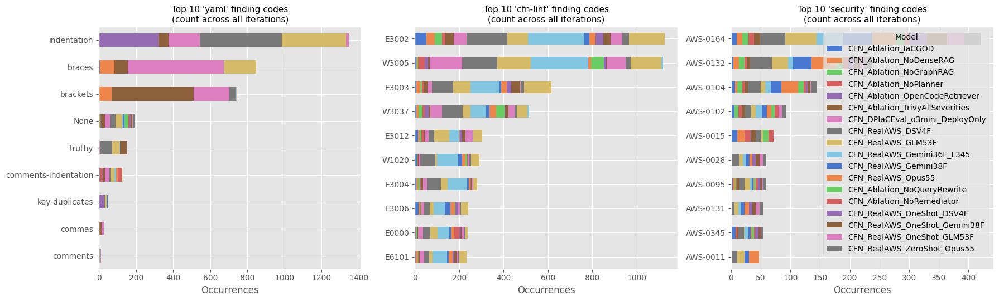

📊 Resolution rate by finding code (runs that ever hit this code, n_runs >= 5; lower resolution_rate_pct = harder for the Remediator to actually clear):


,Stage,Code,n_runs,n_passed,resolution_rate_pct
33,cfn-lint,E3002,431,308,71.5
90,cfn-lint,W3005,257,178,69.3
261,security,AWS-0164,221,156,70.6
6,cfn-lint,E0000,178,131,73.6
93,cfn-lint,W3037,168,132,78.6
258,security,AWS-0132,156,120,76.9
266,yaml,None,152,111,73.0
34,cfn-lint,E3003,147,103,70.1
69,cfn-lint,E6101,130,97,74.6
77,cfn-lint,W1020,124,94,75.8


📊 Per-model resolution rate for the most common code in each stage:
  Stage 'yaml', code 'None':


,n_runs,n_passed,resolution_rate_pct
Model,,,
CFN_Ablation_IaCGOD,4.0,4.0,100.0
CFN_Ablation_NoDenseRAG,2.0,2.0,100.0
CFN_Ablation_NoGraphRAG,2.0,2.0,100.0
CFN_Ablation_TrivyAllSeverities,2.0,2.0,100.0
CFN_DPIaCEval_o3mini_DeployOnly,7.0,3.0,42.9
CFN_RealAWS_DSV4F,22.0,19.0,86.4
CFN_RealAWS_DSV4F_DeployOnly_L345,15.0,10.0,66.7
CFN_RealAWS_GLM53F,32.0,28.0,87.5
CFN_RealAWS_Gemini36F_L345,3.0,3.0,100.0


  Stage 'cfn-lint', code 'E3002':


,n_runs,n_passed,resolution_rate_pct
Model,,,
CFN_Ablation_IaCGOD,15.0,14.0,93.3
CFN_Ablation_NoDenseRAG,14.0,13.0,92.9
CFN_Ablation_NoGraphRAG,13.0,13.0,100.0
CFN_Ablation_NoPlanner,7.0,6.0,85.7
CFN_Ablation_TrivyAllSeverities,17.0,16.0,94.1
CFN_DPIaCEval_o3mini_DeployOnly,32.0,25.0,78.1
CFN_RealAWS_DSV4F,71.0,65.0,91.5
CFN_RealAWS_DSV4F_DeployOnly_L345,36.0,30.0,83.3
CFN_RealAWS_GLM53F,81.0,71.0,87.7


  Stage 'security', code 'AWS-0164':


,n_runs,n_passed,resolution_rate_pct
Model,,,
CFN_Ablation_IaCGOD,6.0,6.0,100.0
CFN_Ablation_NoDenseRAG,5.0,5.0,100.0
CFN_Ablation_NoGraphRAG,5.0,5.0,100.0
CFN_Ablation_NoPlanner,6.0,6.0,100.0
CFN_Ablation_TrivyAllSeverities,6.0,6.0,100.0
CFN_RealAWS_DSV4F,23.0,21.0,91.3
CFN_RealAWS_GLM53F,28.0,26.0,92.9
CFN_RealAWS_Gemini36F_L345,25.0,25.0,100.0
CFN_RealAWS_Gemini38F,26.0,25.0,96.2


None

In [12]:
def _plot_remediator_error_types(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    import re

    ENTRY_SPLIT_RE = re.compile(r'\s\|\s(?=\[)')
    CODE_RE = re.compile(r'^\[([^\]]*)\]')
    STAGE_ERROR_COLS = {
        'yaml': 'all_yaml_errors',
        'cfn-lint': 'all_cfn_lint_errors',
        'security': 'all_security_errors',
    }

    def _split_error_entries(text):
        if not isinstance(text, str) or text.strip() in ('', 'None'):
            return []
        return [e.strip() for e in ENTRY_SPLIT_RE.split(text.strip()) if e.strip()]

    def _error_code(entry):
        m = CODE_RE.match(entry)
        code = m.group(1) if m else ''
        return code if code else 'UNCODED'

    occurrence_rows = []
    run_level_rows = []
    model_order = list(dfs.keys())

    for model_name, df in dfs.items():
        if not all(c in df.columns for c in STAGE_ERROR_COLS.values()):
            print(f"⚠️ Skipping {model_name}: missing one of {list(STAGE_ERROR_COLS.values())}.")
            continue
        for _, row in df.iterrows():
            for stage, col in STAGE_ERROR_COLS.items():
                entries = _split_error_entries(row.get(col))
                codes_seen = set()
                for entry in entries:
                    code = _error_code(entry)
                    codes_seen.add(code)
                    occurrence_rows.append({'Model': model_name, 'Stage': stage, 'Code': code})
                for code in codes_seen:
                    run_level_rows.append({
                        'Model': model_name, 'Stage': stage, 'Code': code,
                        'row_number': row.get('row_number'),
                        'Passed': row.get('final_validation_passed'),
                    })

    if occurrence_rows:
        occ_df = pd.DataFrame(occurrence_rows)
        run_df = pd.DataFrame(run_level_rows).drop_duplicates(subset=['Model', 'Stage', 'Code', 'row_number'])

        total_by_stage = occ_df.groupby(['Model', 'Stage']).size().unstack(fill_value=0).reindex(model_order)
        print('📊 Total remediator-visible findings by stage (summed across all iterations of every run):')
        display(total_by_stage)

        stage_order = ['yaml', 'cfn-lint', 'security']
        present_stages = [s for s in stage_order if s in occ_df['Stage'].unique()]
        fig, axes = plt.subplots(1, len(present_stages), figsize=(6 * len(present_stages), 5.5))
        if len(present_stages) == 1:
            axes = [axes]
        for ax, stage in zip(axes, present_stages):
            stage_occ = occ_df[occ_df['Stage'] == stage]
            top_codes = stage_occ['Code'].value_counts().head(10)
            per_model = (
                stage_occ[stage_occ['Code'].isin(top_codes.index)]
                .groupby(['Code', 'Model']).size().unstack(fill_value=0)
                .reindex(columns=[m for m in model_order if m in stage_occ['Model'].unique()])
                .loc[top_codes.index[::-1]]
            )
            per_model.plot(kind='barh', stacked=True, ax=ax, legend=(ax is axes[-1]))
            ax.set_title(f"Top 10 '{stage}' finding codes\n(count across all iterations)", fontsize=11)
            ax.set_xlabel('Occurrences')
            ax.set_ylabel('')
        plt.tight_layout()
        plt.show()

        MIN_RUNS = 5
        resolution = (
            run_df.groupby(['Stage', 'Code'])
            .agg(n_runs=('Passed', 'size'), n_passed=('Passed', lambda s: (s == True).sum()))
            .reset_index()
        )
        resolution['resolution_rate_pct'] = (resolution['n_passed'] / resolution['n_runs'] * 100).round(1)
        resolution = resolution[resolution['n_runs'] >= MIN_RUNS].sort_values(
            ['n_runs'], ascending=False
        )
        print(f"📊 Resolution rate by finding code (runs that ever hit this code, n_runs >= {MIN_RUNS}; "
              f"lower resolution_rate_pct = harder for the Remediator to actually clear):")
        with pd.option_context('display.max_rows', 30):
            display(resolution.head(30))

        print('📊 Per-model resolution rate for the most common code in each stage:')
        for stage in present_stages:
            stage_codes = resolution[resolution['Stage'] == stage]
            if stage_codes.empty:
                continue
            top_code = stage_codes.iloc[0]['Code']
            sub = run_df[(run_df['Stage'] == stage) & (run_df['Code'] == top_code)]
            per_model_rate = (
                sub.groupby('Model')['Passed']
                .agg(n_runs='size', n_passed=lambda s: (s == True).sum())
                .reindex(model_order)
                .dropna(how='all')
            )
            per_model_rate['resolution_rate_pct'] = (per_model_rate['n_passed'] / per_model_rate['n_runs'] * 100).round(1)
            print(f"  Stage '{stage}', code '{top_code}':")
            display(per_model_rate)
    else:
        print('⚠️ No parsable remediator error entries found for any model.')

_out_remediator_error_types = widgets.interactive_output(_plot_remediator_error_types, {'selected_models': model_selector})
display(_out_remediator_error_types)

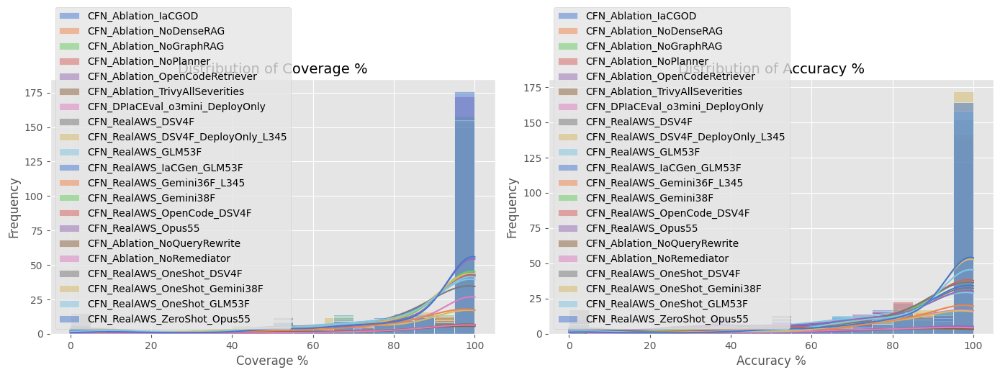

None

In [13]:
def _plot_coverage_accuracy_dist(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    plt.figure(figsize=(14, 5))

    for idx, (model_name, df) in enumerate(dfs.items()):
        plt.subplot(1, 2, 1)
        sns.histplot(df['coverage_pct'].dropna(), bins=20, kde=True, label=model_name, alpha=0.5)
        plt.title('Distribution of Coverage %', fontsize=14)
        plt.xlabel('Coverage %')
        plt.ylabel('Frequency')
        plt.legend()

        plt.subplot(1, 2, 2)
        sns.histplot(df['accuracy_pct'].dropna(), bins=20, kde=True, label=model_name, alpha=0.5)
        plt.title('Distribution of Accuracy %', fontsize=14)
        plt.xlabel('Accuracy %')
        plt.ylabel('Frequency')
        plt.legend()

    plt.tight_layout()
    plt.show()

_out_coverage_accuracy_dist = widgets.interactive_output(_plot_coverage_accuracy_dist, {'selected_models': model_selector})
display(_out_coverage_accuracy_dist)

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


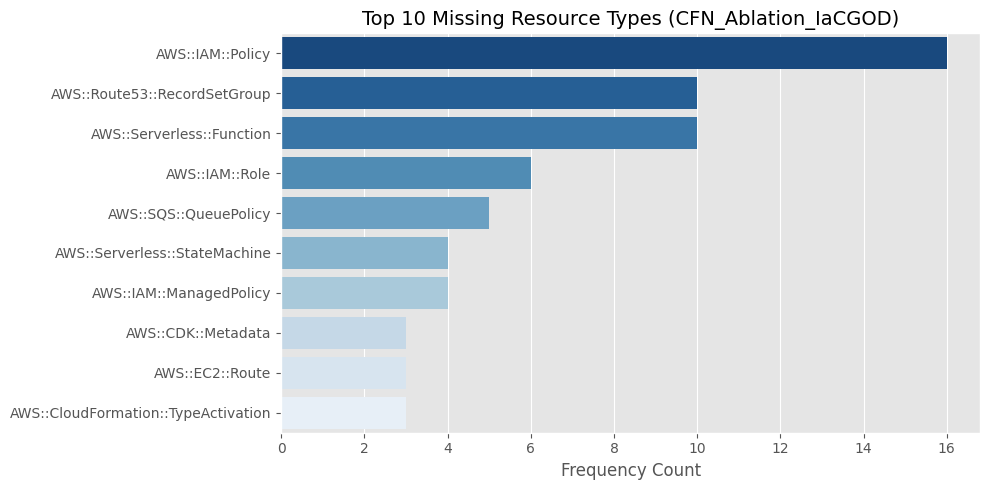

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


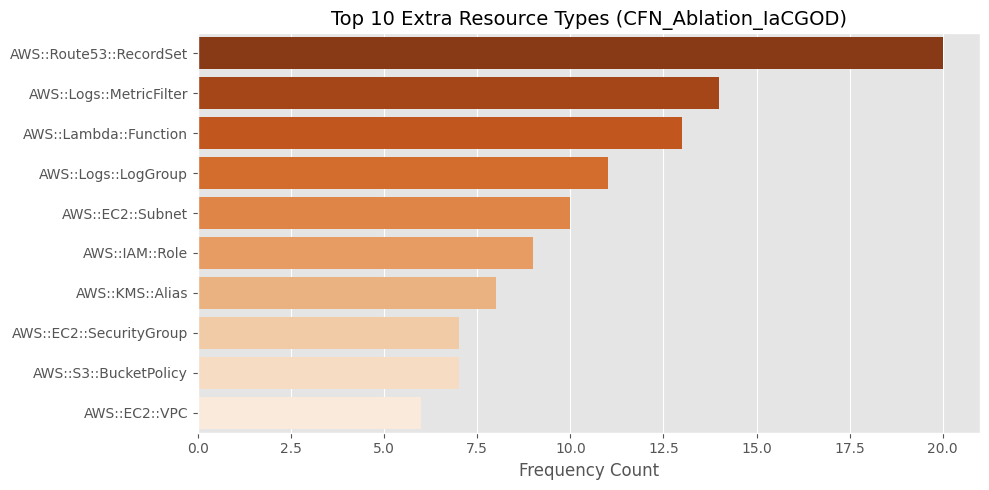

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


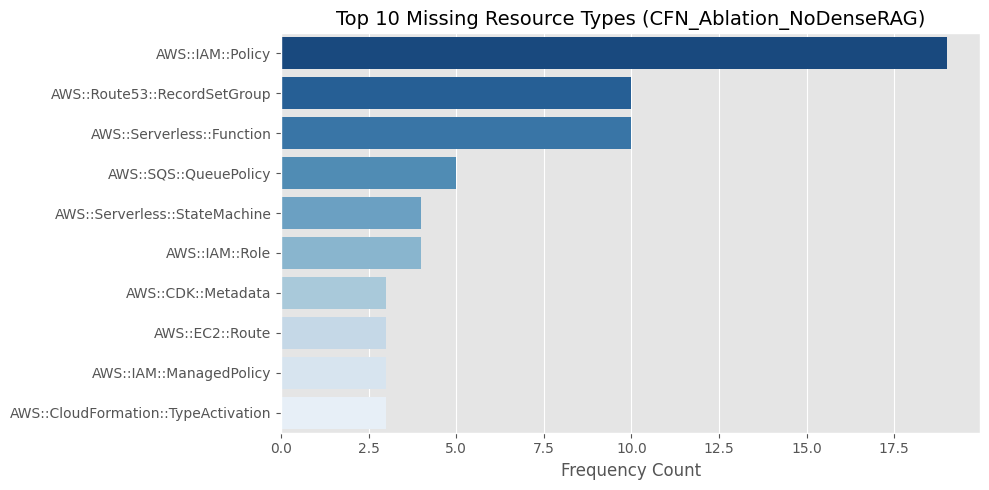

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


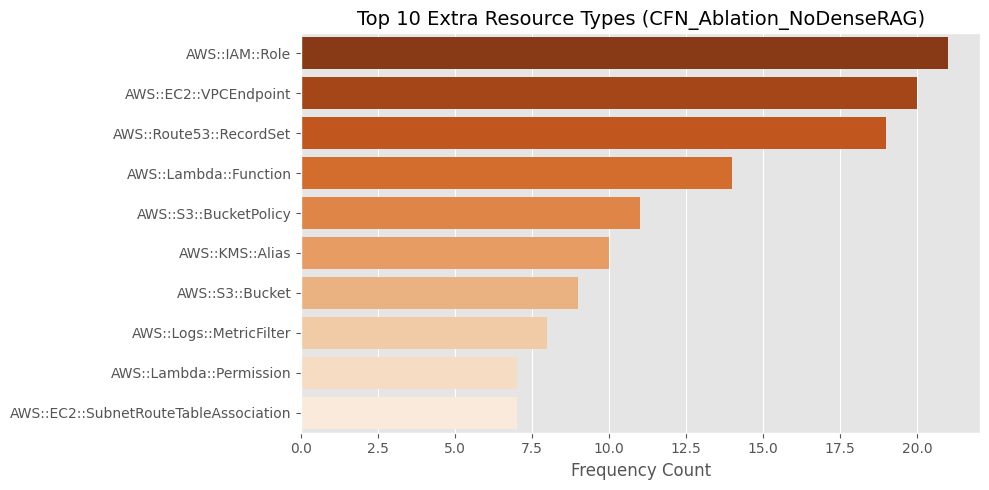

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


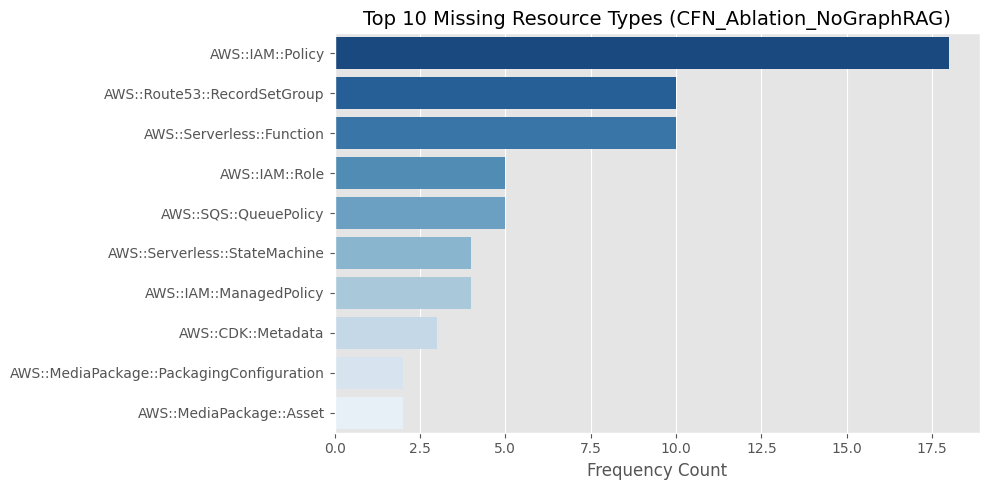

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


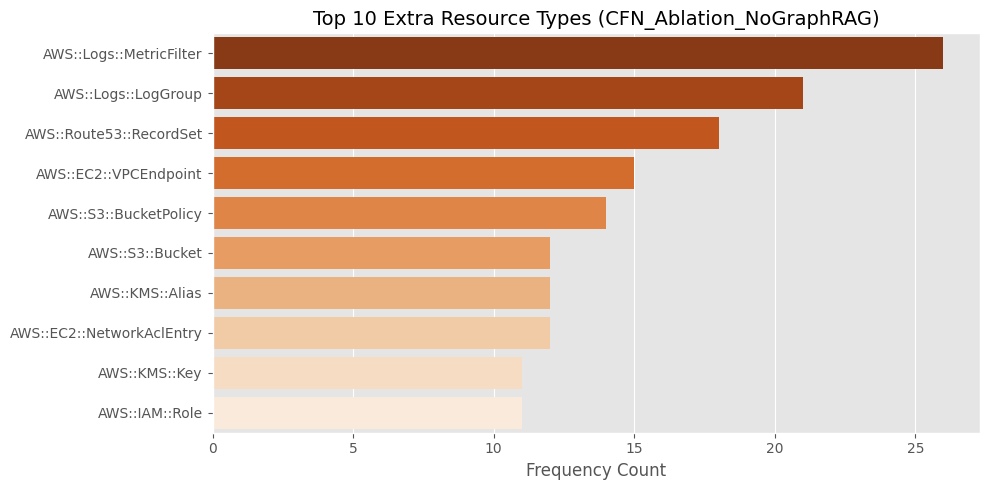

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


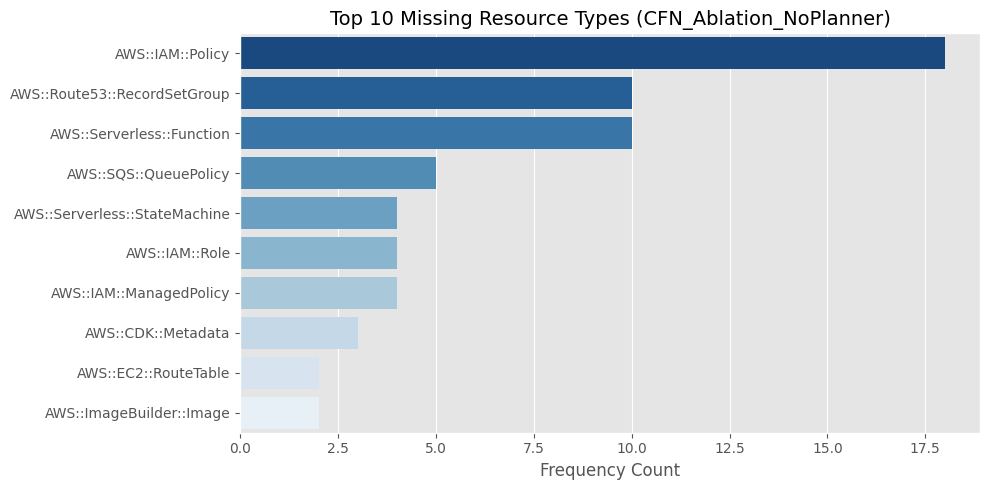

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


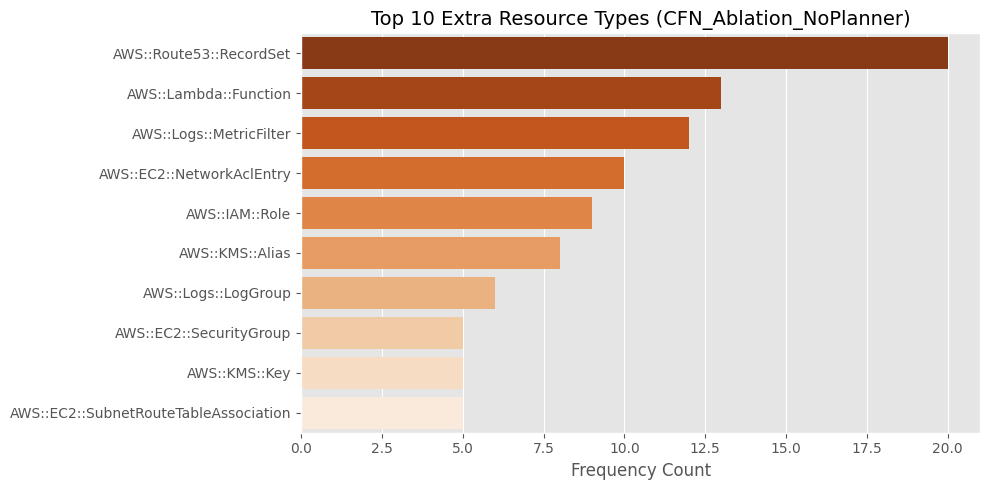

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


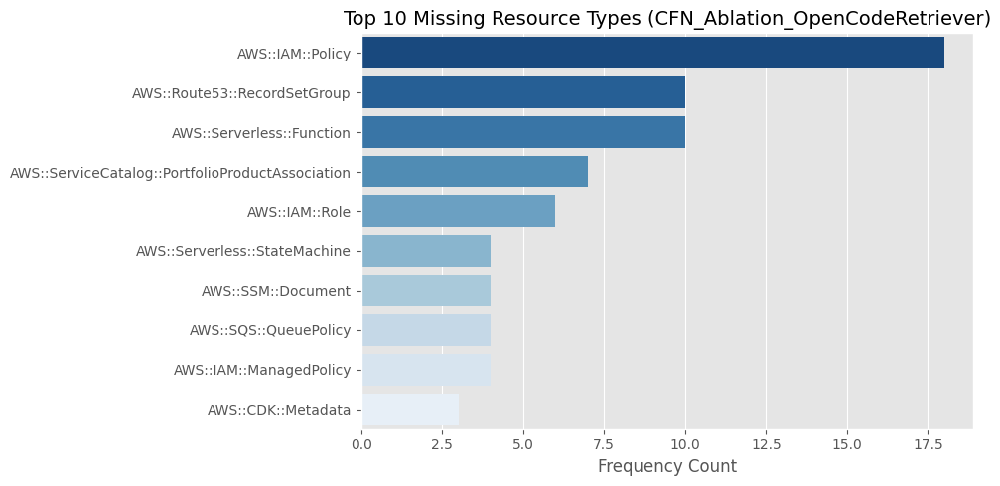

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


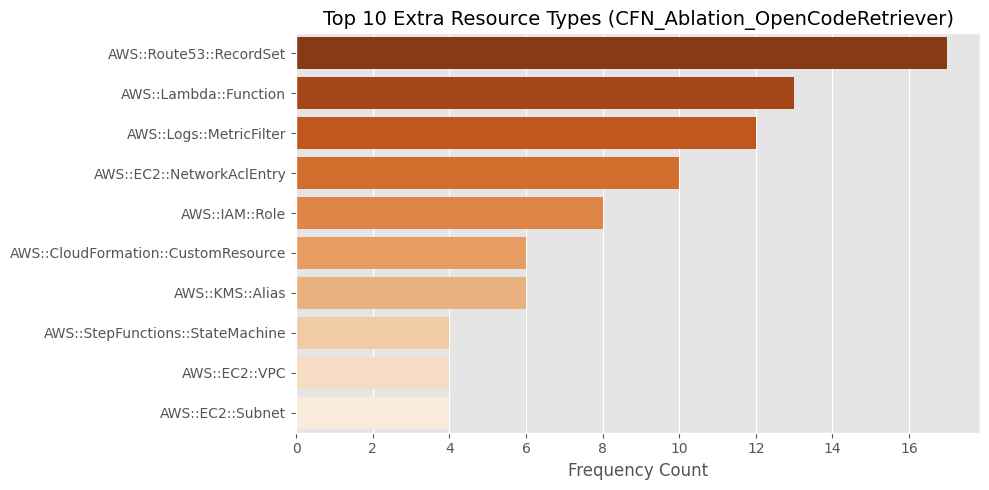

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


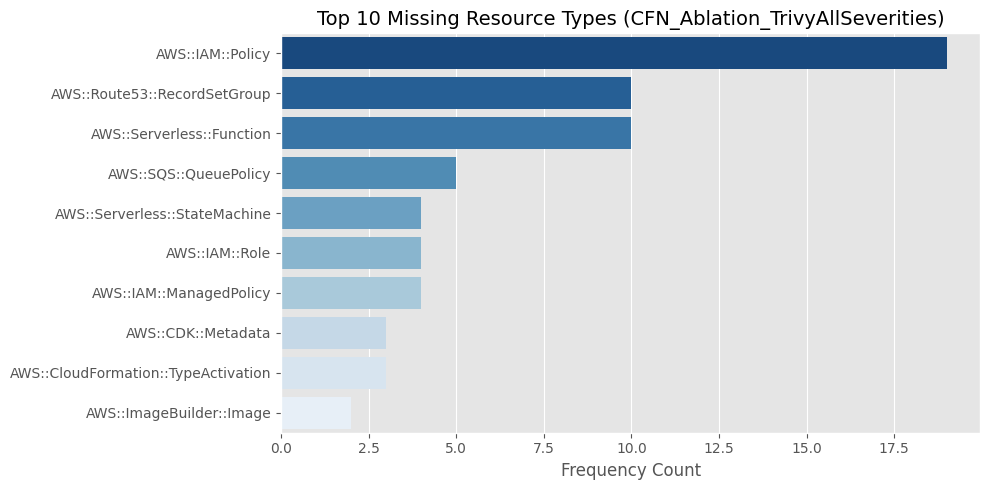

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


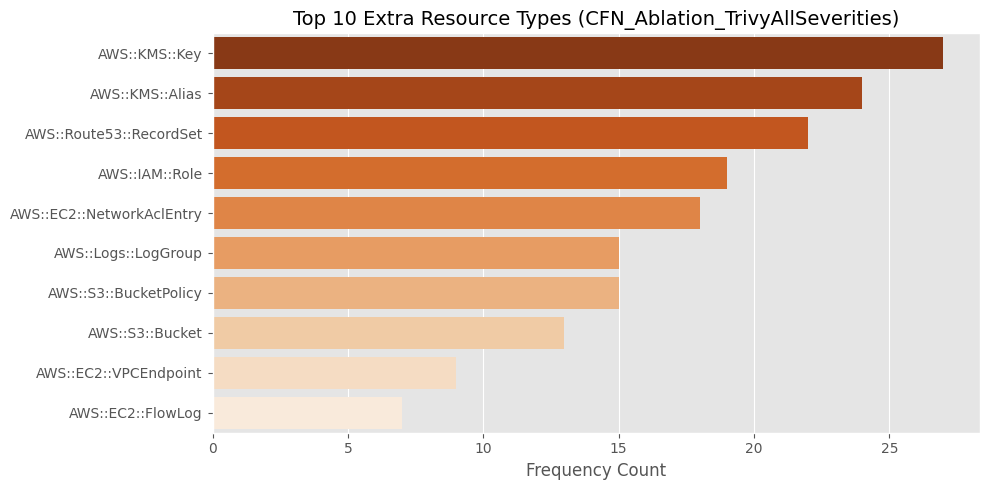

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


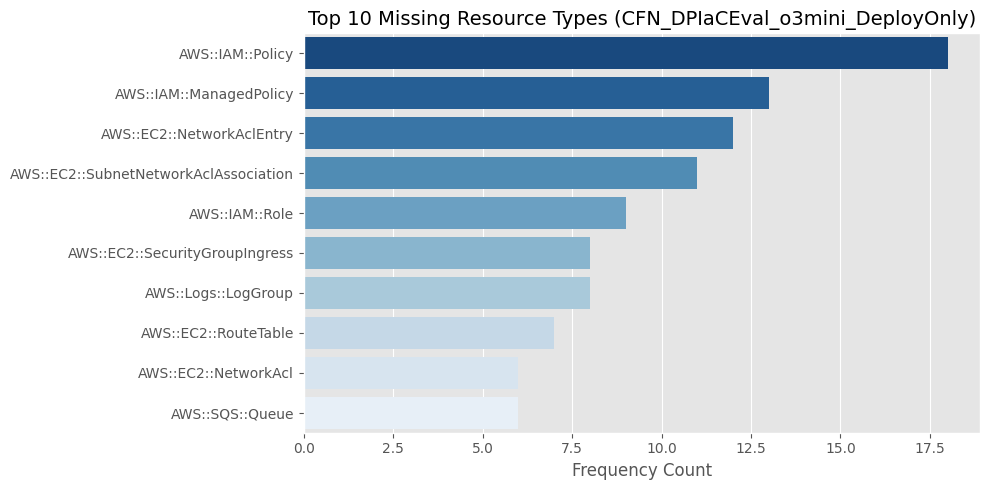

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


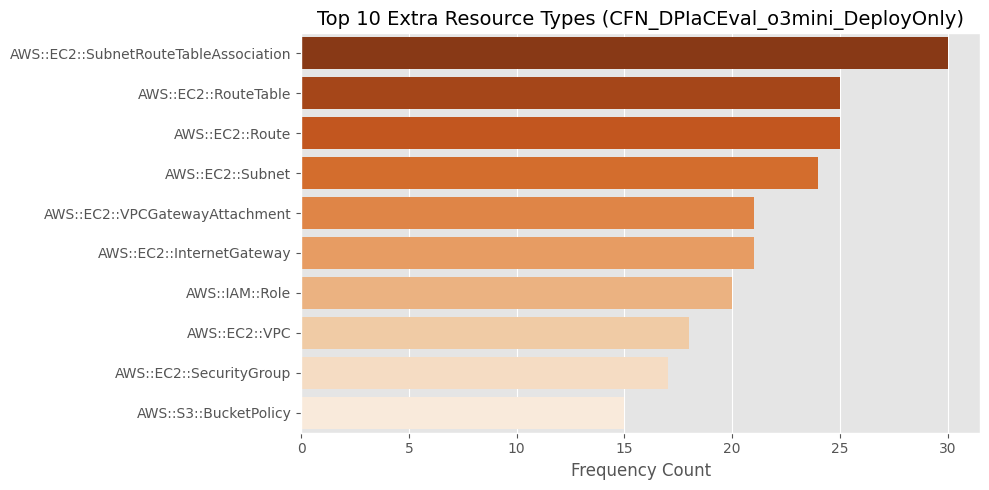

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


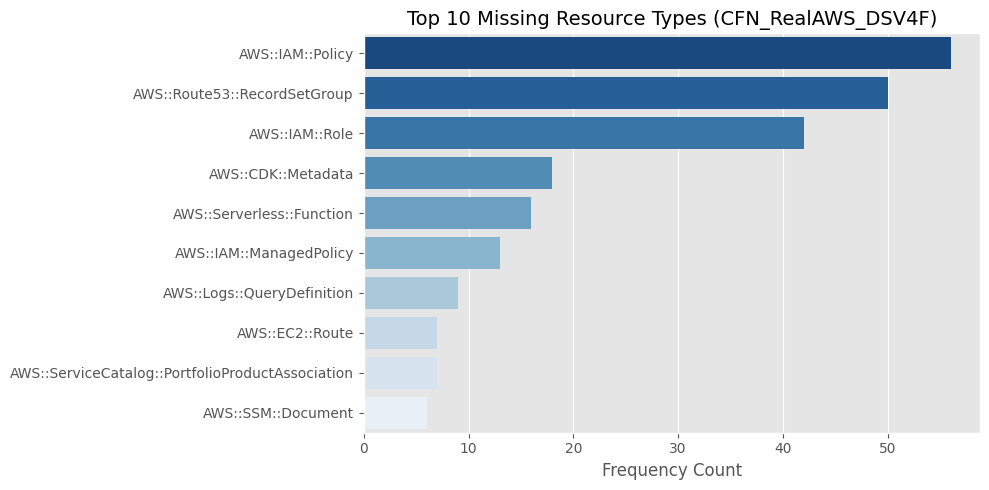

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


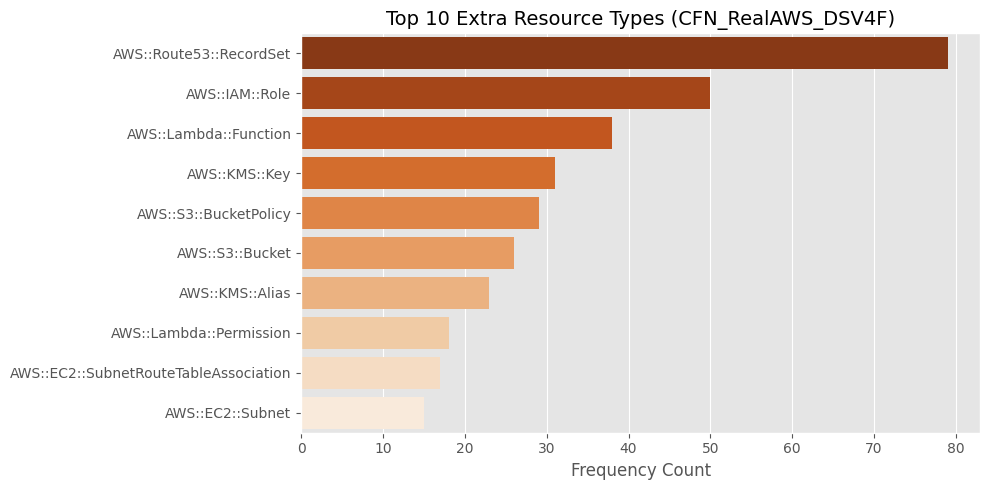

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


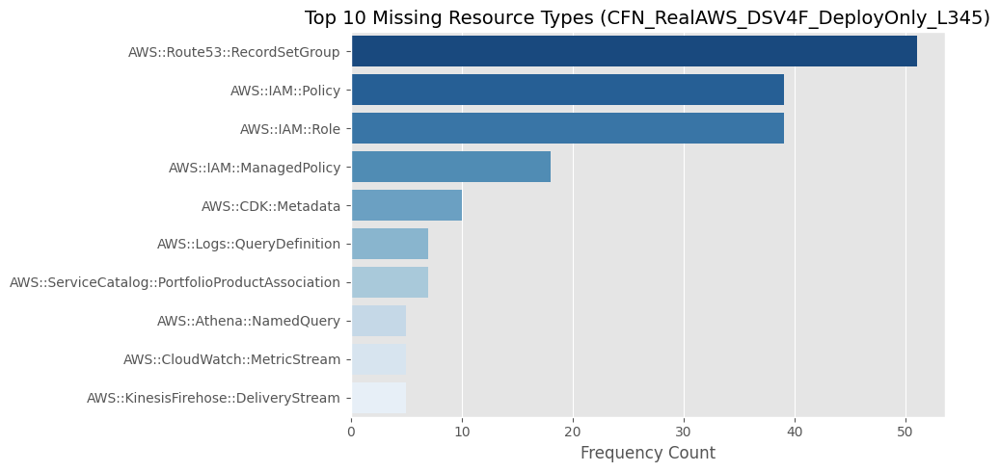

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


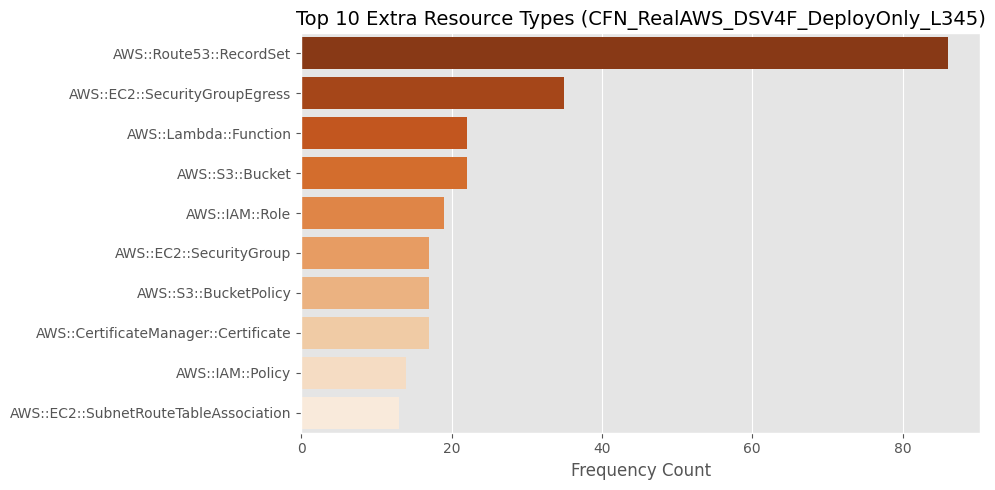

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


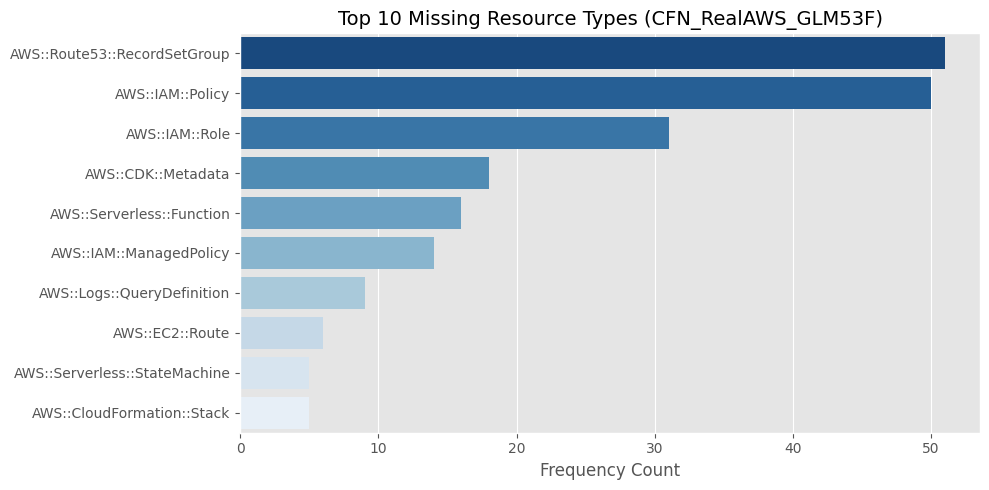

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


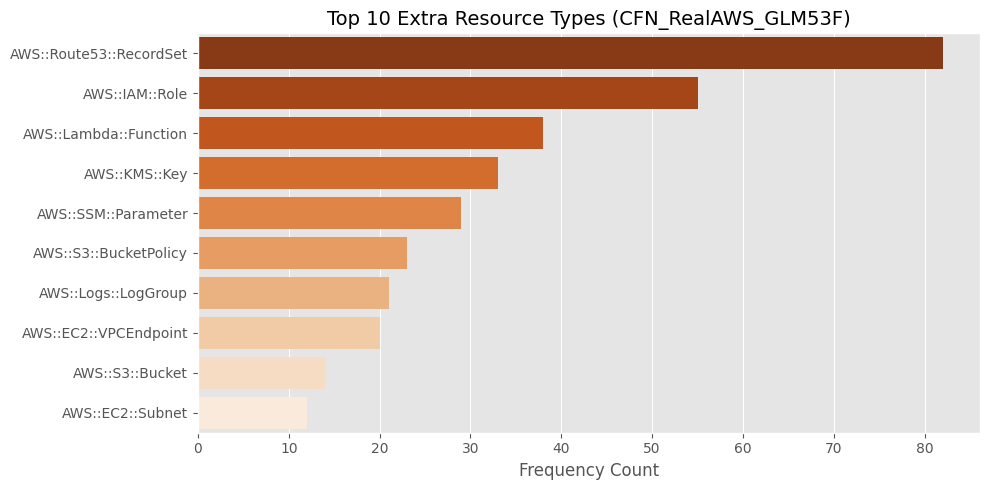

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


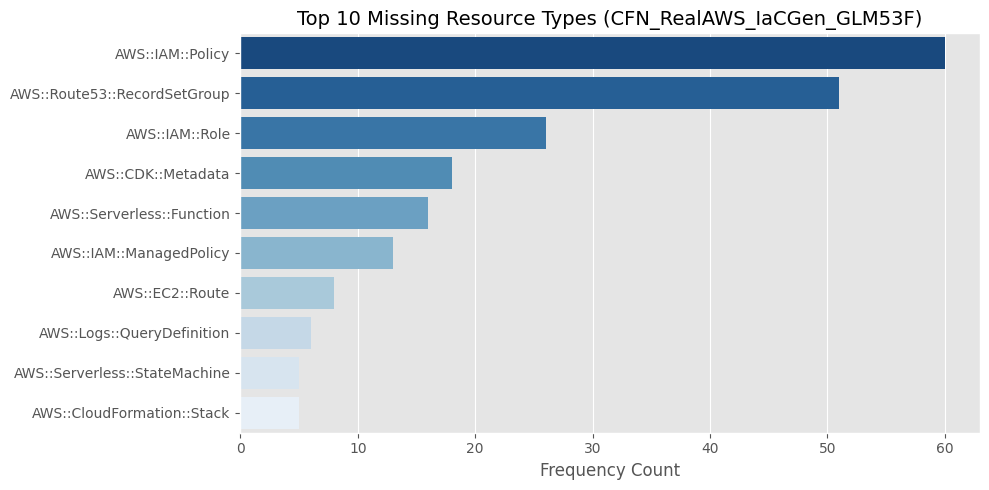

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


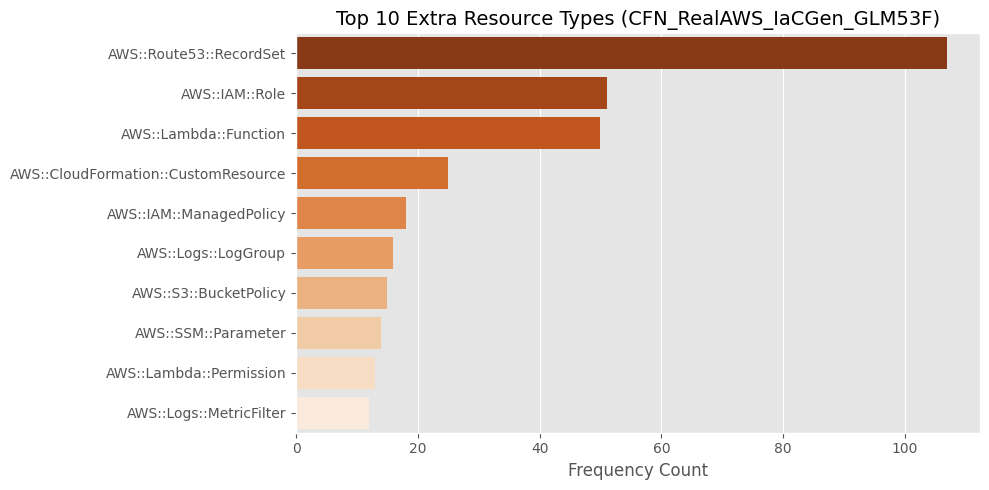

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


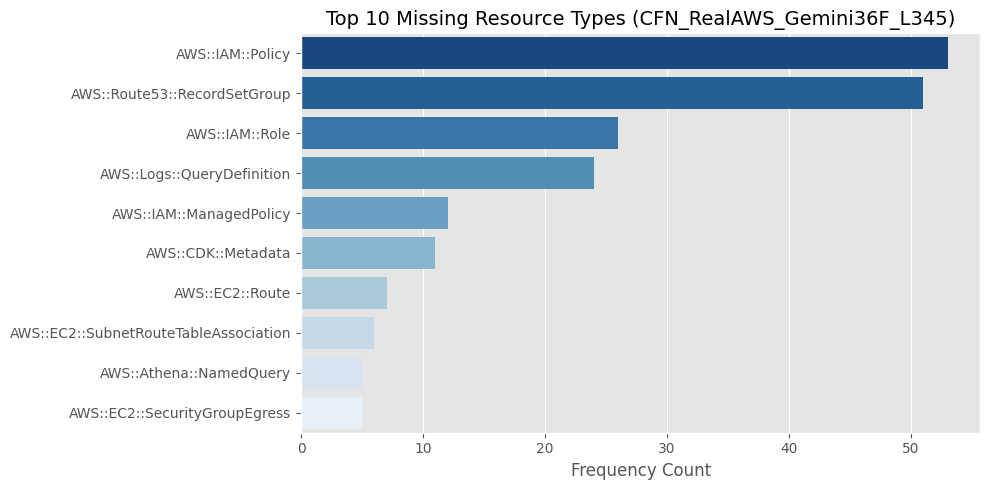

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


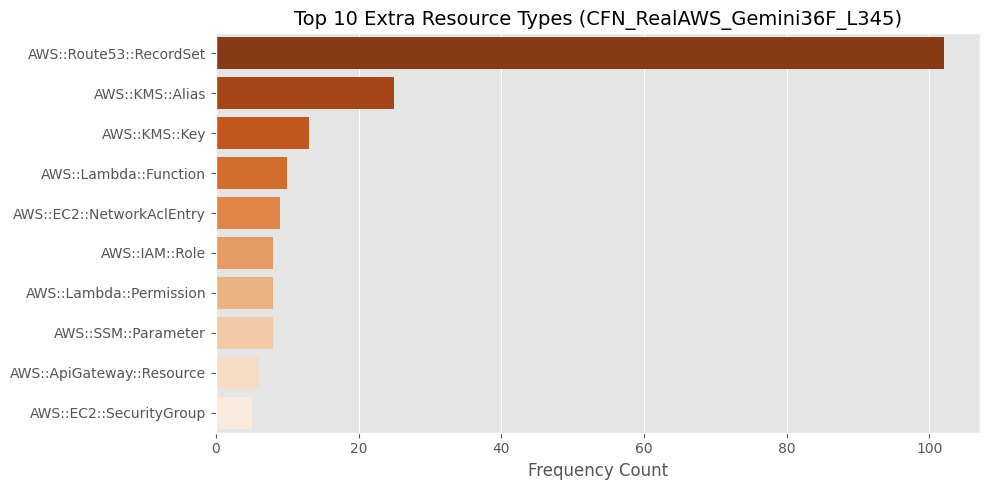

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


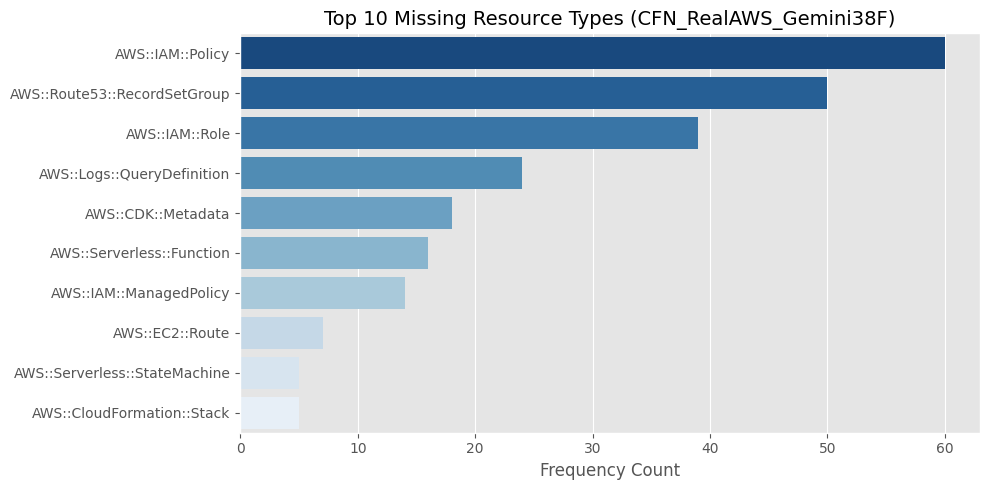

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


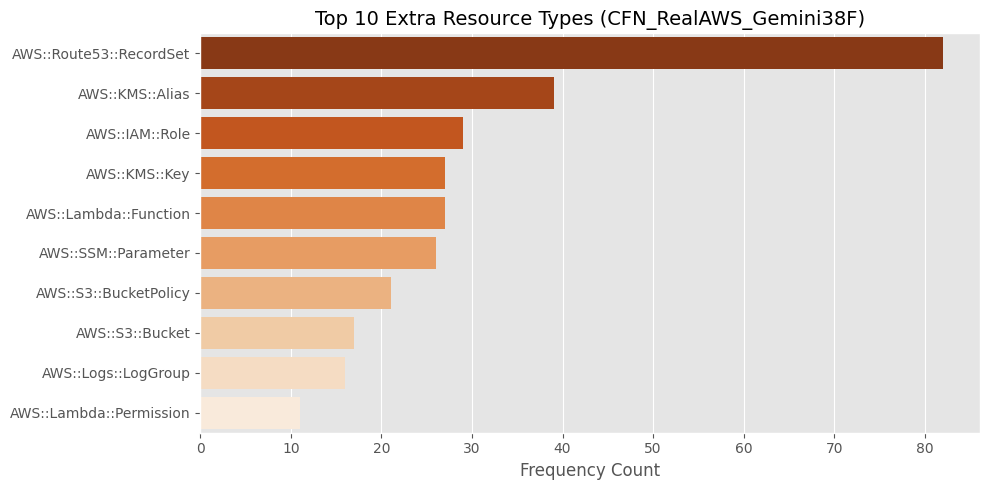

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


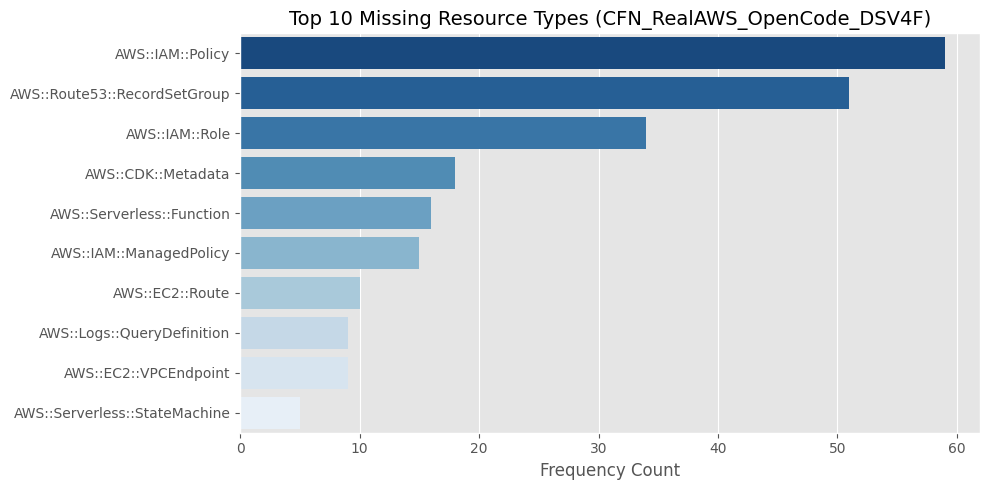

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


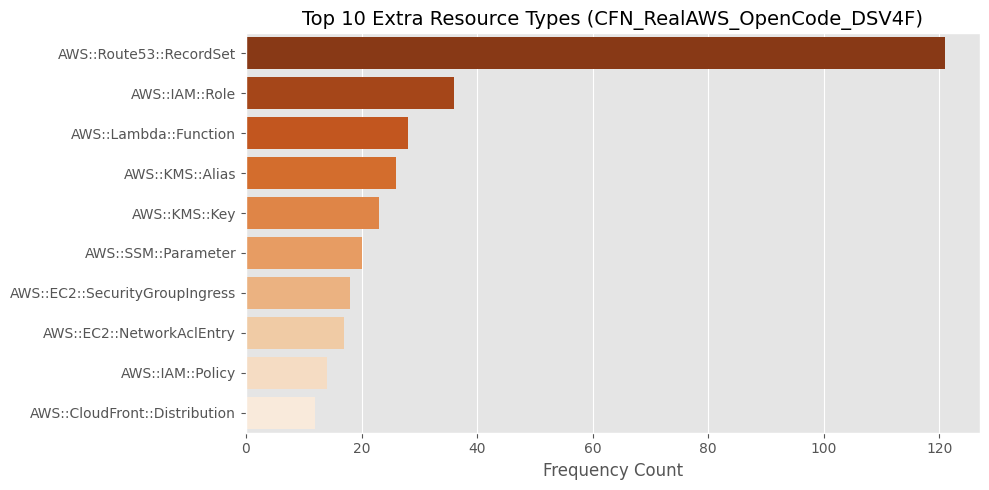

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


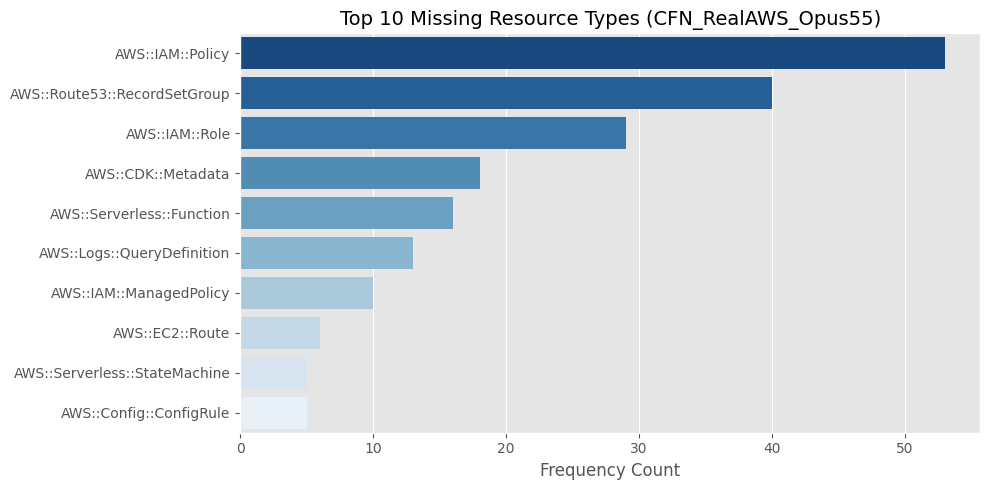

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


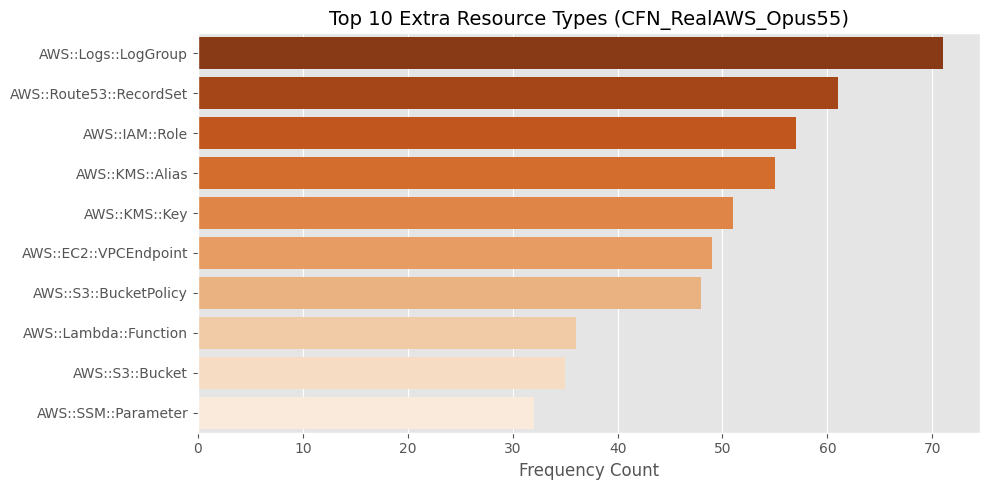

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


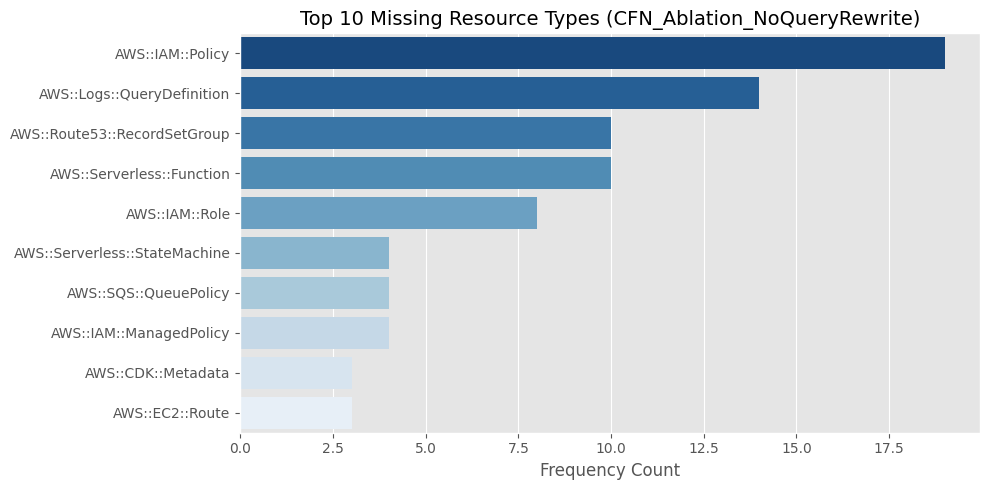

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


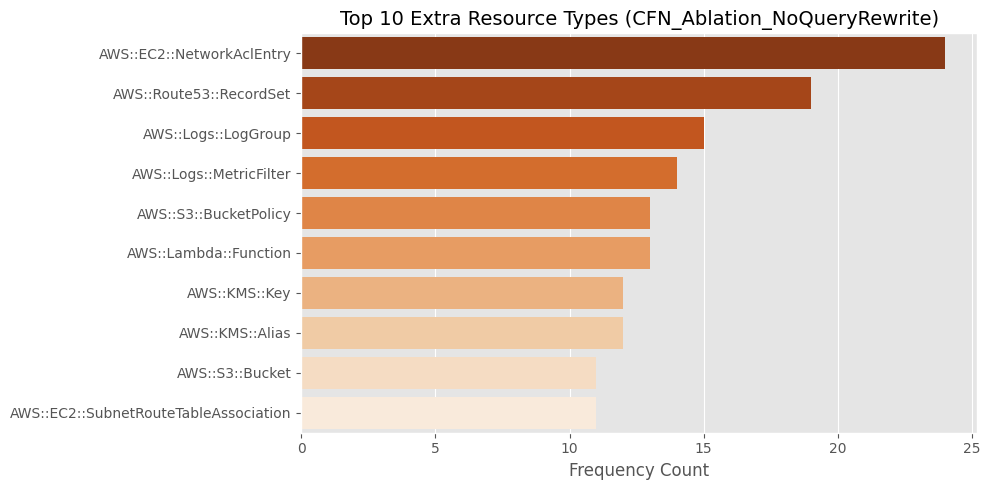

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


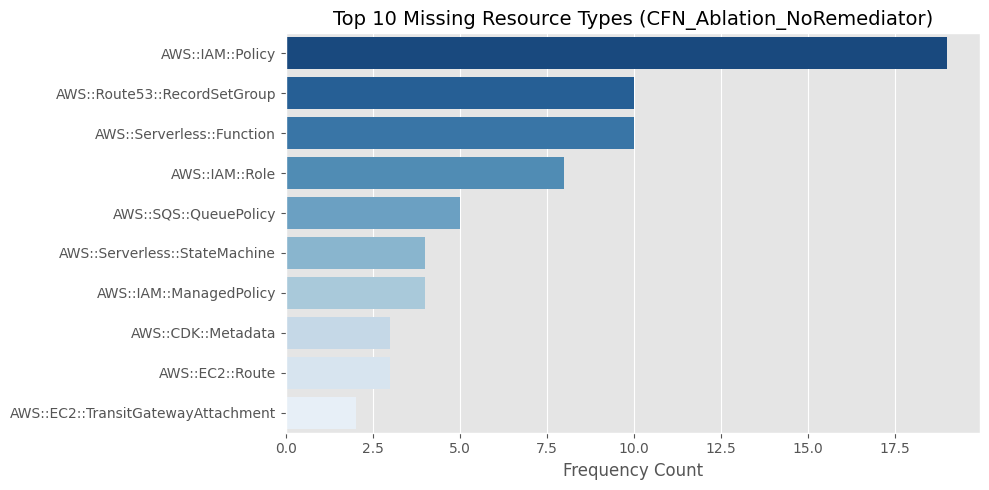

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


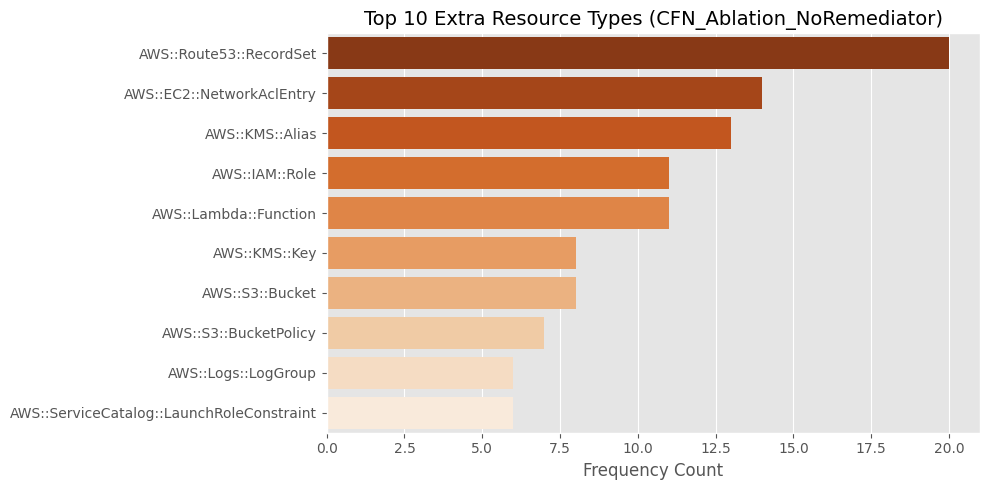

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


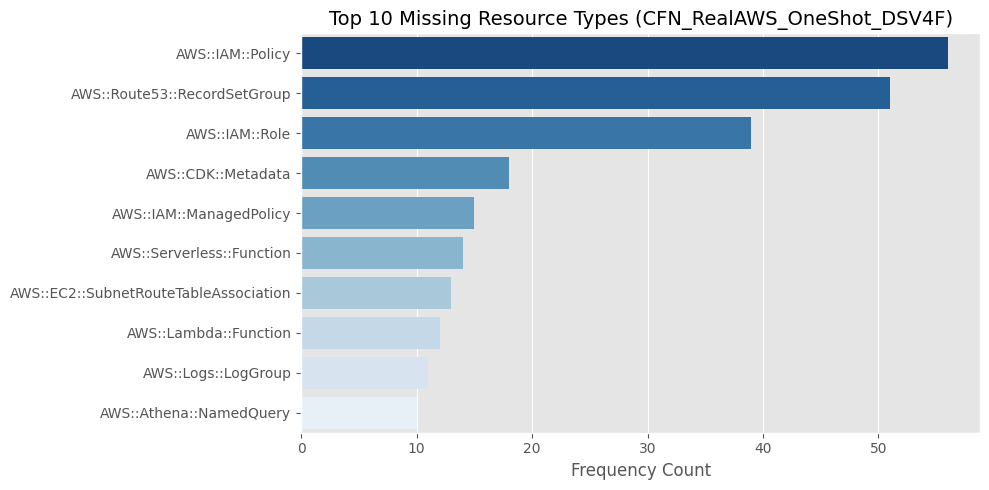

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


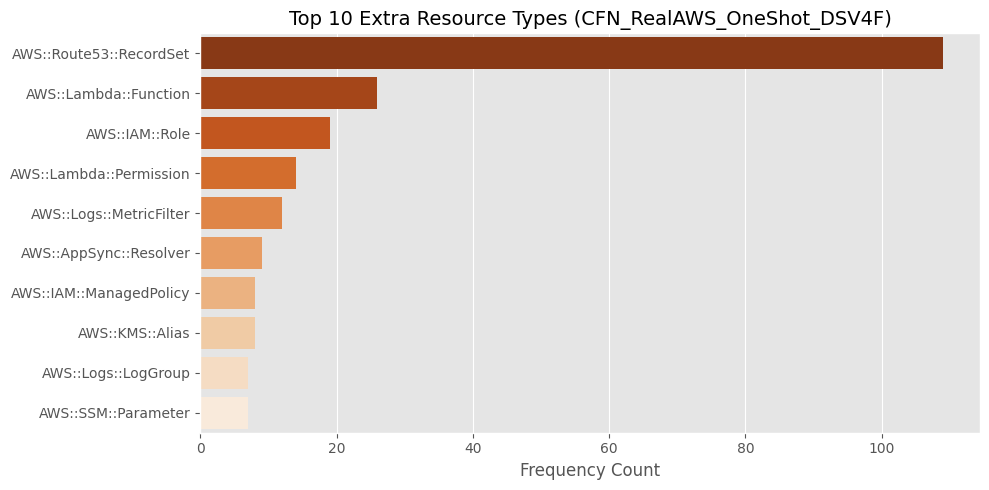

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


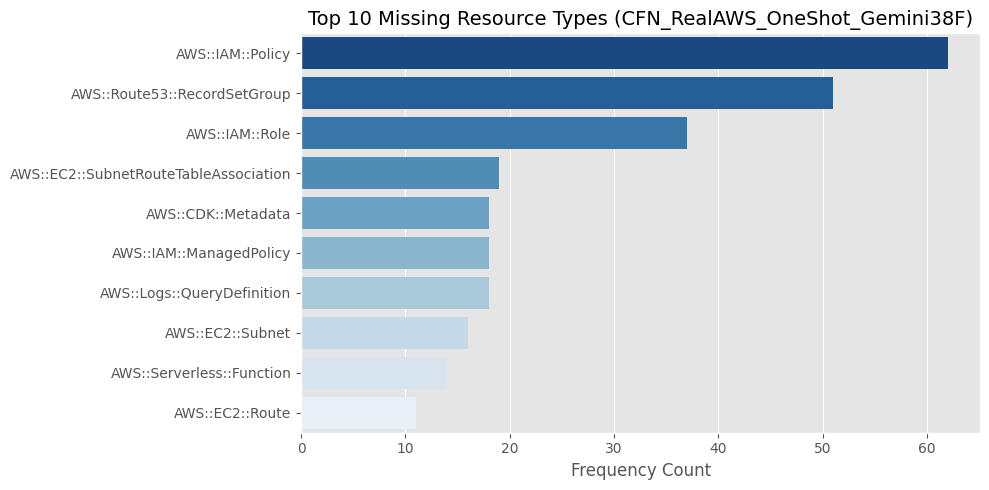

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


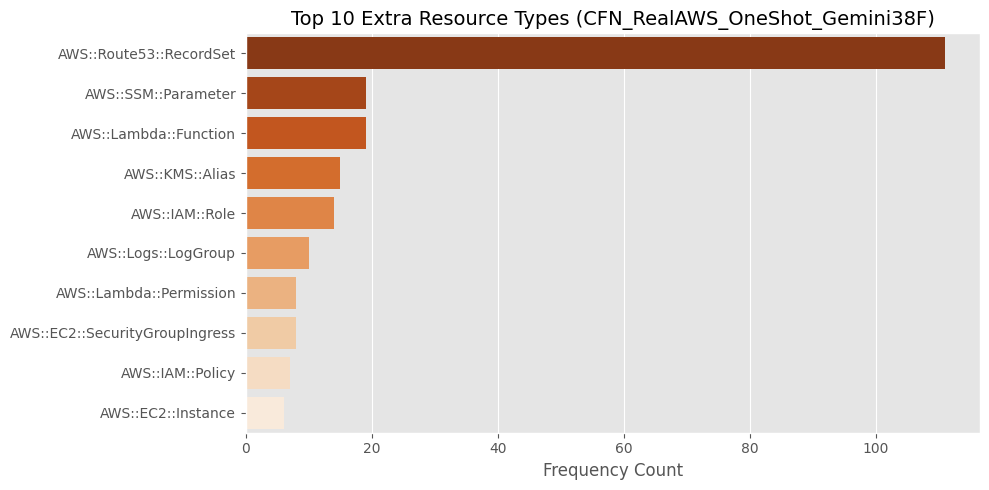

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


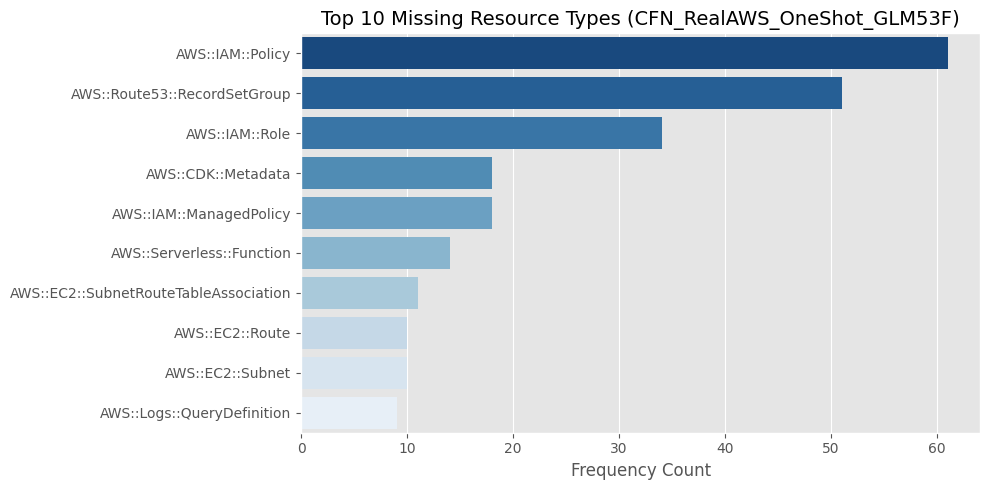

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


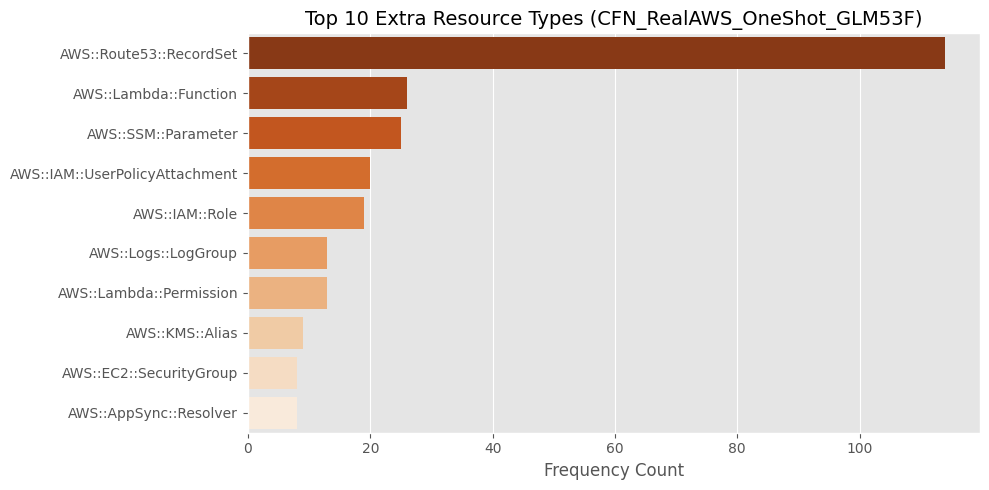

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')


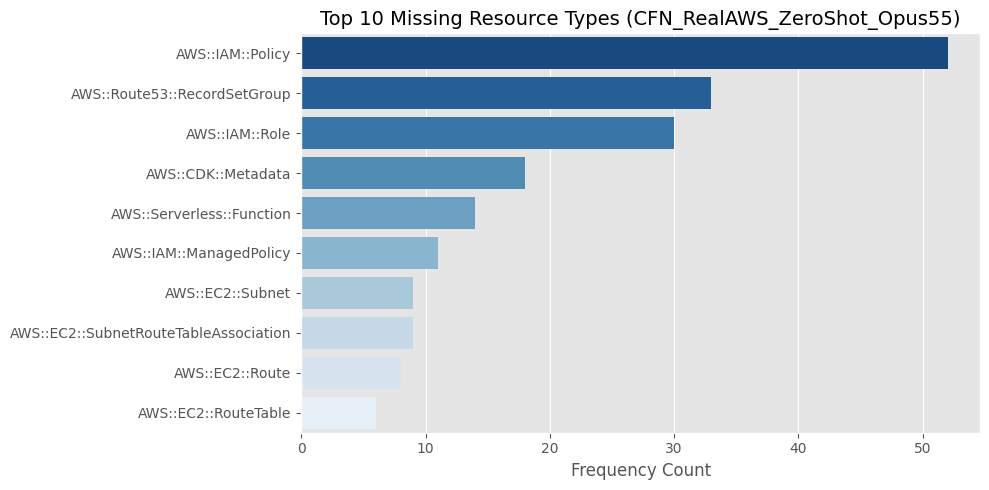

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8510/1164442205.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')


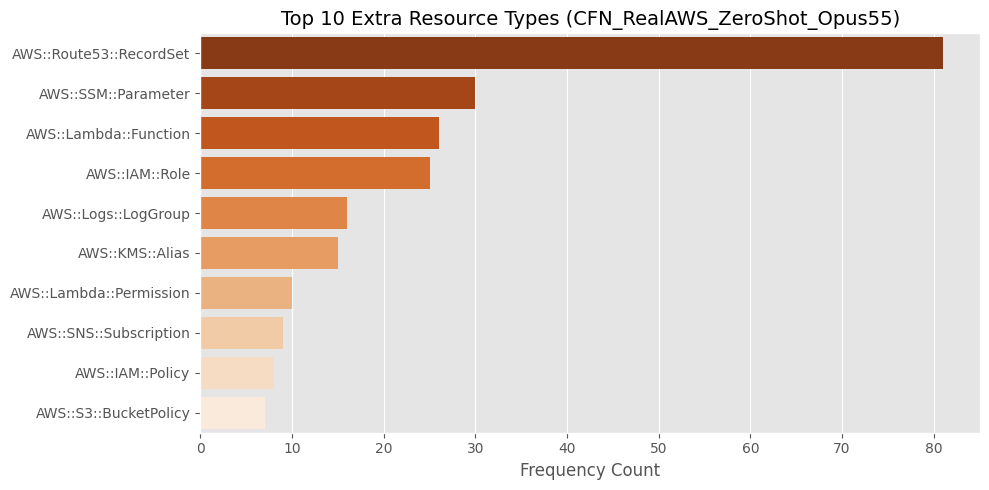

In [14]:
for model_name, df in merged_dataframes.items():
    missing_counter = Counter()
    extra_counter = Counter()
    
    if 'missing_resource_types' in df.columns:
        for items in df['missing_resource_types'].dropna():
            for item in str(items).split(';'):
                if item.strip():
                    missing_counter[item.strip()] += 1
                    
    if 'extra_resource_types' in df.columns:
        for items in df['extra_resource_types'].dropna():
            for item in str(items).split(';'):
                if item.strip():
                    extra_counter[item.strip()] += 1
                    
    top_missing = pd.DataFrame(missing_counter.most_common(10), columns=['Resource Type', 'Frequency'])
    top_extra = pd.DataFrame(extra_counter.most_common(10), columns=['Resource Type', 'Frequency'])
    
    if not top_missing.empty:
        plt.figure(figsize=(10, 5))
        sns.barplot(data=top_missing, y='Resource Type', x='Frequency', palette='Blues_r')
        plt.title(f'Top 10 Missing Resource Types ({model_name})', fontsize=14)
        plt.xlabel('Frequency Count')
        plt.ylabel('')
        plt.tight_layout()
        plt.show()
        
    if not top_extra.empty:
        plt.figure(figsize=(10, 5))
        sns.barplot(data=top_extra, y='Resource Type', x='Frequency', palette='Oranges_r')
        plt.title(f'Top 10 Extra Resource Types ({model_name})', fontsize=14)
        plt.xlabel('Frequency Count')
        plt.ylabel('')
        plt.tight_layout()
        plt.show()

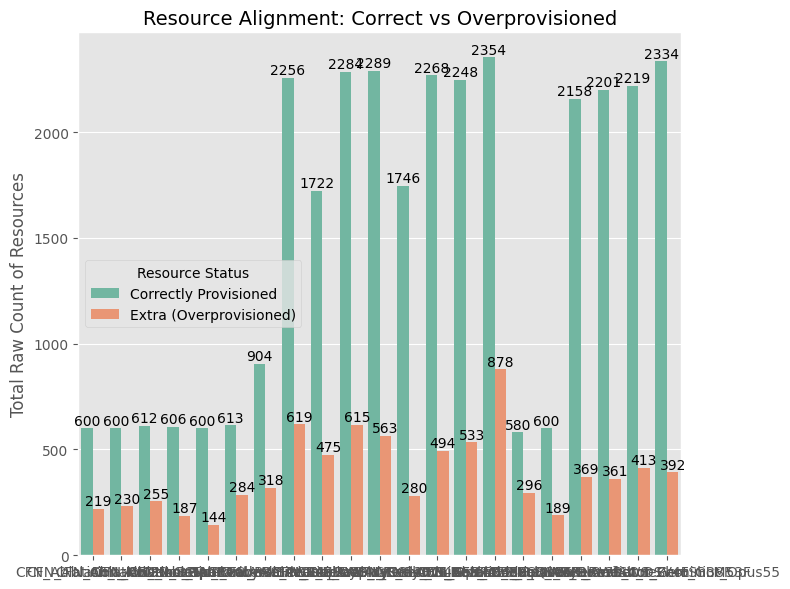

None

In [15]:
def _plot_resource_alignment(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    overprovisioning_data = []

    for model_name, df in dfs.items():
        if 'extra_resources' in df.columns and 'correct_resources' in df.columns:
            total_extra = df['extra_resources'].sum()
            total_correct = df['correct_resources'].sum()

            overprovisioning_data.append({
                'Model': model_name, 
                'Resource Status': 'Correctly Provisioned', 
                'Total': total_correct
            })
            overprovisioning_data.append({
                'Model': model_name, 
                'Resource Status': 'Extra (Overprovisioned)', 
                'Total': total_extra
            })

    if overprovisioning_data:
        over_df = pd.DataFrame(overprovisioning_data)

        plt.figure(figsize=(8, 6))
        sns.barplot(data=over_df, x='Model', y='Total', hue='Resource Status', palette='Set2')
        plt.title('Resource Alignment: Correct vs Overprovisioned', fontsize=14)
        plt.ylabel('Total Raw Count of Resources', fontsize=12)
        plt.xlabel('')

        for p in plt.gca().patches:
            height = p.get_height()
            if height > 0:
                plt.gca().text(p.get_x() + p.get_width()/2., height + 3, f'{int(height)}', 
                               ha='center', va='bottom', fontsize=10)

        plt.tight_layout()
        plt.show()
    else:
        print("Could not find 'extra_resources' or 'correct_resources' columns to plot overprovisioning.")

_out_resource_alignment = widgets.interactive_output(_plot_resource_alignment, {'selected_models': model_selector})
display(_out_resource_alignment)

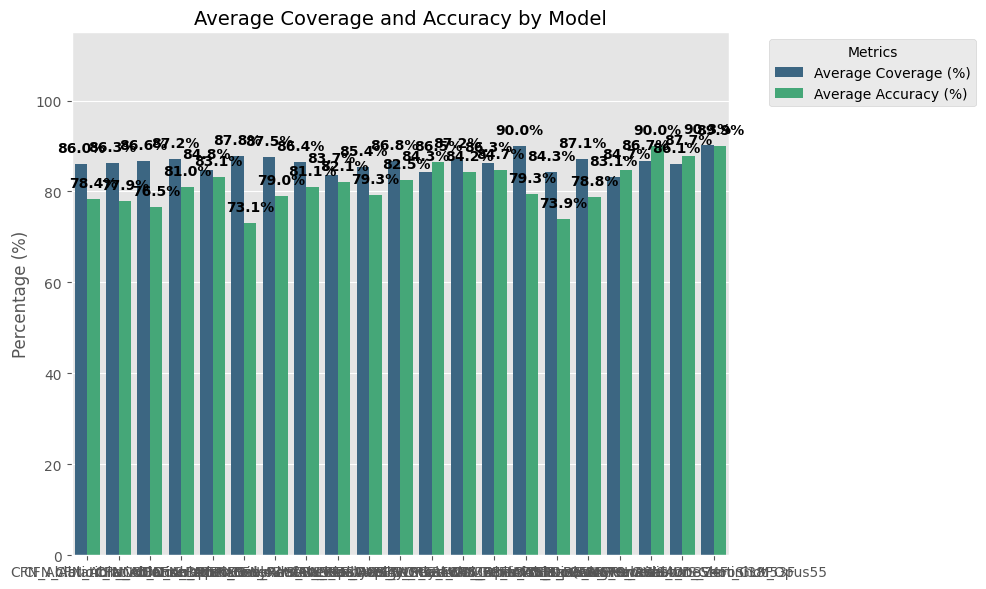

None

In [16]:
def _plot_avg_coverage_accuracy_bar(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    avg_metrics_data = []

    for model_name, df in dfs.items():
        if 'coverage_pct' in df.columns and 'accuracy_pct' in df.columns:
            avg_coverage = df['coverage_pct'].mean()
            avg_accuracy = df['accuracy_pct'].mean()

            avg_metrics_data.extend([
                {'Model': model_name, 'Metric': 'Average Coverage (%)', 'Value': avg_coverage},
                {'Model': model_name, 'Metric': 'Average Accuracy (%)', 'Value': avg_accuracy}
            ])

    if avg_metrics_data:
        avg_df = pd.DataFrame(avg_metrics_data)

        plt.figure(figsize=(10, 6))
        sns.barplot(data=avg_df, x='Model', y='Value', hue='Metric', palette='viridis')

        plt.title('Average Coverage and Accuracy by Model', fontsize=14)
        plt.ylabel('Percentage (%)', fontsize=12)
        plt.xlabel('')
        plt.ylim(0, 115)

        for p in plt.gca().patches:
            height = p.get_height()
            if pd.notna(height) and height > 0:
                plt.gca().text(
                    p.get_x() + p.get_width() / 2., 
                    height + 2, 
                    f'{height:.1f}%', 
                    ha='center', 
                    va='bottom', 
                    fontsize=10, 
                    fontweight='bold'
                )

        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Metrics")
        plt.tight_layout()
        plt.show()
    else:
        print("Could not find 'coverage_pct' or 'accuracy_pct' columns in the provided dataframes.")

_out_avg_coverage_accuracy_bar = widgets.interactive_output(_plot_avg_coverage_accuracy_bar, {'selected_models': model_selector})
display(_out_avg_coverage_accuracy_bar)

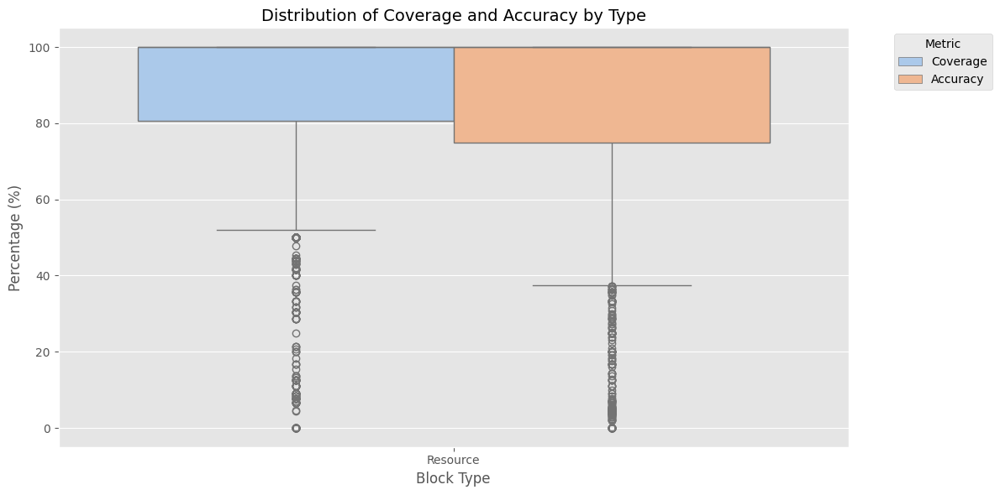

In [17]:
box_data = []
block_types = ['resource', 'data', 'variable', 'output']

for model_name, df in merged_dataframes.items():
    is_legacy_cfn = 'coverage_pct' in df.columns

    if is_legacy_cfn:
        for _, row in df.dropna(subset=['coverage_pct', 'accuracy_pct']).iterrows():
            box_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Coverage', 'Percentage': row['coverage_pct']})
            box_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Accuracy', 'Percentage': row['accuracy_pct']})
            
            if 'intent_coverage_pct' in df.columns and pd.notna(row.get('intent_coverage_pct')):
                box_data.append({'Model': model_name, 'Block Type': 'User Intent', 'Metric': 'Coverage', 'Percentage': row['intent_coverage_pct']})
    else:
        for btype in block_types:
            cov_col, acc_col = f'{btype}_cov_pct', f'{btype}_acc_pct'
            if cov_col in df.columns and acc_col in df.columns:
                for _, row in df.dropna(subset=[cov_col, acc_col]).iterrows():
                    box_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Coverage', 'Percentage': row[cov_col]})
                    box_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Accuracy', 'Percentage': row[acc_col]})

if box_data:
    box_df = pd.DataFrame(box_data)
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=box_df, x='Block Type', y='Percentage', hue='Metric', palette='pastel')
    plt.title('Distribution of Coverage and Accuracy by Type', fontsize=14)
    plt.ylabel('Percentage (%)')
    plt.ylim(-5, 105)
    plt.legend(title="Metric", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()




None

In [18]:
def _plot_coverage_accuracy_bar_by_model(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    avg_metrics_data = []

    for model_name, df in dfs.items():
        if 'coverage_pct' in df.columns:
            avg_metrics_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Coverage (%)', 'Value': df['coverage_pct'].mean()})
            avg_metrics_data.append({'Model': model_name, 'Block Type': 'Resource', 'Metric': 'Accuracy (%)', 'Value': df['accuracy_pct'].mean()})

            if 'intent_coverage_pct' in df.columns:
                avg_metrics_data.append({'Model': model_name, 'Block Type': 'User Intent', 'Metric': 'Coverage (%)', 'Value': df['intent_coverage_pct'].mean()})
        else:
            for btype in block_types:
                cov_col, acc_col = f'{btype}_cov_pct', f'{btype}_acc_pct'
                if cov_col in df.columns and acc_col in df.columns:
                    avg_metrics_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Coverage (%)', 'Value': df[cov_col].mean()})
                    avg_metrics_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Metric': 'Accuracy (%)', 'Value': df[acc_col].mean()})

    if avg_metrics_data:
        avg_df = pd.DataFrame(avg_metrics_data)
        g = sns.catplot(
            data=avg_df, kind="bar",
            x="Block Type", y="Value", hue="Metric", col="Model",
            palette="viridis", height=5, aspect=1.2
        )

        g.set_axis_labels("", "Percentage (%)")
        g.set(ylim=(0, 115))
        g.fig.suptitle('Average Coverage and Accuracy', fontsize=16, y=1.05)

        for ax in g.axes.flat:
            for p in ax.patches:
                height = p.get_height()
                if pd.notna(height) and height > 0:
                    ax.text(p.get_x() + p.get_width() / 2., height + 2, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
        plt.show()

_out_coverage_accuracy_bar_by_model = widgets.interactive_output(_plot_coverage_accuracy_bar_by_model, {'selected_models': model_selector})
display(_out_coverage_accuracy_bar_by_model)




None

In [19]:
def _plot_resource_alignment_by_model(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    overprovisioning_data = []

    for model_name, df in dfs.items():
        if 'correct_resources' in df.columns:
            overprovisioning_data.append({'Model': model_name, 'Block Type': 'Resource', 'Status': 'Correctly Provisioned', 'Total': df['correct_resources'].sum()})
            overprovisioning_data.append({'Model': model_name, 'Block Type': 'Resource', 'Status': 'Extra (Overprovisioned)', 'Total': df['extra_resources'].sum()})
        else:
            for btype in block_types:
                cor_col, ext_col = f'{btype}_cor', f'{btype}_extra'
                if cor_col in df.columns and ext_col in df.columns:
                    overprovisioning_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Status': 'Correctly Provisioned', 'Total': df[cor_col].sum()})
                    overprovisioning_data.append({'Model': model_name, 'Block Type': btype.capitalize(), 'Status': 'Extra (Overprovisioned)', 'Total': df[ext_col].sum()})

    if overprovisioning_data:
        over_df = pd.DataFrame(overprovisioning_data)
        g = sns.catplot(
            data=over_df, kind="bar",
            x="Block Type", y="Total", hue="Status", col="Model",
            palette="Set2", height=5, aspect=1.2, sharey=False
        )

        g.set_axis_labels("", "Total Raw Count")
        g.fig.suptitle('Alignment: Correct vs Overprovisioned', fontsize=16, y=1.05)

        for ax in g.axes.flat:
            for p in ax.patches:
                height = p.get_height()
                if pd.notna(height) and height > 0:
                    ax.text(p.get_x() + p.get_width() / 2., height + (ax.get_ylim()[1] * 0.02), f'{int(height)}', ha='center', va='bottom', fontsize=10)
        plt.show()

_out_resource_alignment_by_model = widgets.interactive_output(_plot_resource_alignment_by_model, {'selected_models': model_selector})
display(_out_resource_alignment_by_model)


CFN_Ablation_IaCGOD: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,4.55,True,11,22,1,10,21,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_Ablation_NoDenseRAG: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,4.76,True,11,21,1,10,20,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_Ablation_NoGraphRAG: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,5.0,True,11,20,1,10,19,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_Ablation_NoPlanner: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,4.55,True,11,22,1,10,21,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_Ablation_OpenCodeRetriever: 2/50 scenarios (4.0%) below 30% on both coverage and accuracy.
  ⚠️ 2 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,5.26,True,11,19,1,10,18,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
1,71,3,20.00,14.29,True,5,7,1,4,6,cfn_templates/aws-samples__aws-cloud-compliance-assurance/aws-devsecops-conf...



CFN_Ablation_TrivyAllSeverities: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,4.17,True,11,24,1,10,23,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_DPIaCEval_o3mini_DeployOnly: 1/153 scenarios (0.7%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,84,1,0.0,0.0,True,1,3,0,1,3,Data\groud_truth\template\macie.yaml



CFN_RealAWS_DSV4F: 8/250 scenarios (3.2%) below 30% on both coverage and accuracy.
  ⚠️ 6 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,50,2,0.00,0.00,True,5,5,0,5,5,cfn_templates/mynameisakash__aws-service-catalog-reference-architectures/iam...
1,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
2,263,2,0.00,0.00,False,5,7,0,5,7,cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operati...
3,159,4,7.69,2.04,True,13,49,1,12,48,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
4,74,3,9.09,5.56,True,11,18,1,10,17,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
5,154,4,11.11,3.85,True,9,26,1,8,25,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
6,108,3,12.50,7.14,True,8,14,1,7,13,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml
7,130,4,13.33,18.18,False,15,11,2,13,9,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml



CFN_RealAWS_DSV4F_DeployOnly_L345: 5/134 scenarios (3.7%) below 30% on both coverage and accuracy.
  ⚠️ 3 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,130,4,6.67,7.69,True,15,13,1,14,12,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
1,159,4,7.69,2.08,False,13,48,1,12,47,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
2,74,3,9.09,5.88,True,11,17,1,10,16,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
3,154,4,11.11,2.04,False,9,49,1,8,48,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
4,108,3,12.50,7.14,True,8,14,1,7,13,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml



CFN_RealAWS_GLM53F: 13/250 scenarios (5.2%) below 30% on both coverage and accuracy.
  ⚠️ 6 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,2,1,0.00,0.00,False,1,1,0,1,1,cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-ba...
1,3,1,0.00,0.00,False,2,6,0,2,6,cfn_templates/aws-samples__sample-developer-tutorials/tuts/001-lightsail-gs/...
2,20,1,0.00,0.00,False,1,4,0,1,4,cfn_templates/Checkmarx__kics/assets/queries/cloudFormation/aws/iam_access_a...
3,22,1,0.00,0.00,False,1,1,0,1,1,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
4,50,2,0.00,0.00,True,5,5,0,5,5,cfn_templates/mynameisakash__aws-service-catalog-reference-architectures/iam...
5,66,2,0.00,0.00,True,2,10,0,2,10,cfn_templates/aws__serverless-application-model/integration/resources/templa...
6,263,2,0.00,0.00,False,5,13,0,5,13,cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operati...
7,130,4,6.67,7.14,True,15,14,1,14,13,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
8,159,4,7.69,11.11,True,13,9,1,12,8,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
9,74,3,9.09,5.26,False,11,19,1,10,18,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_RealAWS_IaCGen_GLM53F: 12/250 scenarios (4.8%) below 30% on both coverage and accuracy.
  ⚠️ 12 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,2,1,0.00,0.00,True,1,3,0,1,3,cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-ba...
1,20,1,0.00,0.00,True,1,3,0,1,3,cfn_templates/Checkmarx__kics/assets/queries/cloudFormation/aws/iam_access_a...
2,22,1,0.00,0.00,True,1,3,0,1,3,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
3,50,2,0.00,0.00,True,5,6,0,5,6,cfn_templates/mynameisakash__aws-service-catalog-reference-architectures/iam...
4,58,2,0.00,0.00,True,8,4,0,8,4,cfn_templates/aws__aws-app-mesh-examples/walkthroughs/howto-servicediscovery...
5,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
6,130,4,6.67,2.86,True,15,35,1,14,34,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
7,159,4,7.69,3.85,True,13,26,1,12,25,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
8,202,5,8.33,12.50,True,12,8,1,11,7,cfn_templates/aws__sagemaker-hyperpod-cluster-setup/eks/cloudformation/sagem...
9,74,3,9.09,4.35,True,11,23,1,10,22,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_RealAWS_Gemini36F_L345: 5/137 scenarios (3.6%) below 30% on both coverage and accuracy.
  ⚠️ 5 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,130,4,6.67,3.85,True,15,26,1,14,25,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
1,159,4,7.69,4.00,True,13,25,1,12,24,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
2,74,3,9.09,5.00,True,11,20,1,10,19,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
3,154,4,11.11,4.76,True,9,21,1,8,20,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
4,108,3,12.50,6.67,True,8,15,1,7,14,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml



CFN_RealAWS_Gemini38F: 7/250 scenarios (2.8%) below 30% on both coverage and accuracy.
  ⚠️ 7 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,50,2,0.00,0.00,True,5,5,0,5,5,cfn_templates/mynameisakash__aws-service-catalog-reference-architectures/iam...
1,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
2,263,2,0.00,0.00,True,5,8,0,5,8,cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operati...
3,130,4,6.67,3.70,True,15,27,1,14,26,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
4,74,3,9.09,4.35,True,11,23,1,10,22,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
5,154,4,11.11,4.55,True,9,22,1,8,21,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
6,108,3,12.50,7.14,True,8,14,1,7,13,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml



CFN_RealAWS_OpenCode_DSV4F: 9/250 scenarios (3.6%) below 30% on both coverage and accuracy.
  ⚠️ 8 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,47,2,0.00,0.00,False,4,1,0,4,1,cfn_templates/aws-samples__sample-agentic-value-accelerator/platform/control...
1,50,2,0.00,0.00,True,5,7,0,5,7,cfn_templates/mynameisakash__aws-service-catalog-reference-architectures/iam...
2,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
3,263,2,0.00,0.00,True,5,6,0,5,6,cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operati...
4,130,4,6.67,2.38,True,15,42,1,14,41,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
5,159,4,7.69,2.17,True,13,46,1,12,45,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
6,74,3,9.09,4.76,True,11,21,1,10,20,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
7,154,4,11.11,4.00,True,9,25,1,8,24,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
8,108,3,12.50,7.14,True,8,14,1,7,13,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml



CFN_RealAWS_Opus55: 5/250 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 5 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
1,263,2,0.00,0.00,True,5,7,0,5,7,cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operati...
2,159,4,7.69,2.78,True,13,36,1,12,35,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
3,154,4,11.11,2.27,True,9,44,1,8,43,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
4,108,3,12.50,5.56,True,8,18,1,7,17,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml



CFN_Ablation_NoQueryRewrite: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,4.76,True,11,21,1,10,20,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_Ablation_NoRemediator: 1/50 scenarios (2.0%) below 30% on both coverage and accuracy.
  ⚠️ 1 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,74,3,9.09,4.55,True,11,22,1,10,21,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...



CFN_RealAWS_OneShot_DSV4F: 20/250 scenarios (8.0%) below 30% on both coverage and accuracy.
  ⚠️ 2 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,29,1,0.00,0.00,False,1,0,0,1,0,cfn_templates/aws__sagemaker-hyperpod-cluster-setup/eks/cloudformation/hpto-...
1,242,2,0.00,0.00,False,7,0,0,7,0,cfn_templates/aws-solutions-library-samples__guidance-for-resilient-data-app...
2,177,5,0.00,0.00,False,25,0,0,25,0,cfn_templates/reinalau__labs-aws-llb/CRUD_Lambda-Dynamo-Apigateway/cloudform...
3,143,4,0.00,0.00,False,8,0,0,8,0,cfn_templates/aws-samples__sample-agentic-ai-acceleration-kr/projects/agento...
4,124,4,0.00,0.00,False,11,0,0,11,0,cfn_templates/aws-cloudformation__aws-cloudformation-samples/hooks/python-ho...
5,244,1,0.00,0.00,False,3,0,0,3,0,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
6,112,4,0.00,0.00,False,10,0,0,10,0,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
7,117,4,0.00,0.00,False,11,0,0,11,0,cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/sta...
8,82,3,0.00,0.00,False,6,0,0,6,0,cfn_templates/aws-samples__infrastructure-deployment-framework/cloud-starter...
9,77,3,0.00,0.00,False,6,0,0,6,0,cfn_templates_greenfield/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/389538044...



CFN_RealAWS_OneShot_Gemini38F: 7/250 scenarios (2.8%) below 30% on both coverage and accuracy.
  ⚠️ 4 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
1,130,4,6.67,3.70,False,15,27,1,14,26,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
2,159,4,7.69,3.23,True,13,31,1,12,30,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
3,74,3,9.09,4.76,False,11,21,1,10,20,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
4,154,4,11.11,4.35,True,9,23,1,8,22,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
5,108,3,12.50,7.14,True,8,14,1,7,13,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml
6,242,2,28.57,28.57,False,7,7,2,5,5,cfn_templates/aws-solutions-library-samples__guidance-for-resilient-data-app...



CFN_RealAWS_OneShot_GLM53F: 8/250 scenarios (3.2%) below 30% on both coverage and accuracy.
  ⚠️ 2 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,20,1,0.00,0.00,False,1,3,0,1,3,cfn_templates/Checkmarx__kics/assets/queries/cloudFormation/aws/iam_access_a...
1,22,1,0.00,0.00,False,1,1,0,1,1,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
2,66,2,0.00,0.00,False,2,10,0,2,10,cfn_templates/aws__serverless-application-model/integration/resources/templa...
3,130,4,6.67,3.33,False,15,30,1,14,29,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
4,159,4,7.69,3.57,True,13,28,1,12,27,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
5,74,3,9.09,4.00,False,11,25,1,10,24,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
6,154,4,11.11,4.55,False,9,22,1,8,21,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
7,108,3,12.50,7.14,True,8,14,1,7,13,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml



CFN_RealAWS_ZeroShot_Opus55: 4/250 scenarios (1.6%) below 30% on both coverage and accuracy.
  ⚠️ 3 of those still PASSED final validation despite the drift -- the generated stack was deployable/secure but unrelated to what was asked, which is exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed alone would have hidden it).


,row_number,difficulty_level,coverage_pct,accuracy_pct,final_validation_passed,required,generated,correct,missing,extra,ground_truth_path
0,66,2,0.00,0.00,True,2,12,0,2,12,cfn_templates/aws__serverless-application-model/integration/resources/templa...
1,130,4,6.67,2.86,True,15,35,1,14,34,cfn_templates/PRX__Infrastructure/dns/radiotopia.fm-hosted_zone.yml
2,154,4,11.11,3.45,False,9,29,1,8,28,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/temp...
3,108,3,12.50,5.56,True,8,18,1,7,17,cfn_templates/PRX__Infrastructure/dns/podcastgarage.org-hosted_zone.yml





None

In [20]:
def _plot_low_cov_acc_audit(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    DRIFT_THRESHOLD_PCT = 30.0

    scenario_diagnostics = {}

    for model_name, df in dfs.items():
        if not {'coverage_pct', 'accuracy_pct'}.issubset(df.columns):
            print(f"⚠️ Skipping {model_name}: no coverage_pct/accuracy_pct columns.")
            continue

        diag_cols = {
            'row_number': df.get('row_number'),
            'difficulty_level': df.get('difficulty_level'),
            'coverage_pct': df['coverage_pct'],
            'accuracy_pct': df['accuracy_pct'],
            'final_validation_passed': df.get('final_validation_passed'),
            'deploy_passed': df.get('deploy_passed'),
            'run_status': df.get('status'),
            'required': df.get('total_required_resources'),
            'generated': df.get('total_generated_resources'),
            'correct': df.get('correct_resources'),
            'missing': df.get('missing_resources'),
            'extra': df.get('extra_resources'),
            'missing_resource_types': df.get('missing_resource_types'),
            'extra_resource_types': df.get('extra_resource_types'),
            'ground_truth_path': df.get('ground_truth_path'),
            'prompt': df.get('prompt'),
        }
        diag_df = pd.DataFrame({k: v for k, v in diag_cols.items() if v is not None})
        diag_df = diag_df.dropna(subset=['coverage_pct', 'accuracy_pct'])

        diag_df['likely_drift'] = (
            (diag_df['coverage_pct'] < DRIFT_THRESHOLD_PCT) &
            (diag_df['accuracy_pct'] < DRIFT_THRESHOLD_PCT)
        )

        scenario_diagnostics[model_name] = diag_df

        n_total = len(diag_df)
        n_flagged = diag_df['likely_drift'].sum()
        n_flagged_but_valid = ((diag_df['likely_drift']) & (diag_df['final_validation_passed'] == True)).sum() \
            if 'final_validation_passed' in diag_df.columns else 0

        print(f"\n{'='*90}\n{model_name}: {n_flagged}/{n_total} scenarios ({n_flagged / n_total:.1%}) "
              f"below {DRIFT_THRESHOLD_PCT:.0f}% on both coverage and accuracy.")
        if n_flagged_but_valid:
            print(f"  ⚠️ {n_flagged_but_valid} of those still PASSED final validation despite the drift -- "
                  f"the generated stack was deployable/secure but unrelated to what was asked, which is "
                  f"exactly the failure mode coverage/accuracy scoring exists to catch (final_validation_passed "
                  f"alone would have hidden it).")

        if n_flagged:
            display_cols = ['row_number', 'difficulty_level', 'coverage_pct', 'accuracy_pct',
                             'final_validation_passed', 'required', 'generated', 'correct',
                             'missing', 'extra', 'ground_truth_path']
            display_cols = [c for c in display_cols if c in diag_df.columns]
            flagged = diag_df[diag_df['likely_drift']].sort_values('coverage_pct').reset_index(drop=True)
            with pd.option_context('display.max_colwidth', 80, 'display.width', 200):
                display(flagged[display_cols])

    if scenario_diagnostics:
        n_models = len(scenario_diagnostics)
        fig, axes = plt.subplots(1, n_models, figsize=(7 * n_models, 6), squeeze=False)
        axes = axes[0]

        for ax, (model_name, diag_df) in zip(axes, scenario_diagnostics.items()):
            ok = diag_df[~diag_df['likely_drift']]
            bad = diag_df[diag_df['likely_drift']]
            ax.scatter(ok['coverage_pct'], ok['accuracy_pct'], alpha=0.5, s=25,
                       label='Normal', color='steelblue')
            ax.scatter(bad['coverage_pct'], bad['accuracy_pct'], alpha=0.8, s=35,
                       label='Likely drift', color='crimson', marker='x')
            ax.axvline(DRIFT_THRESHOLD_PCT, color='gray', linestyle='--', linewidth=1)
            ax.axhline(DRIFT_THRESHOLD_PCT, color='gray', linestyle='--', linewidth=1)
            ax.set_title(model_name, fontsize=13)
            ax.set_xlabel('Coverage %')
            ax.set_ylabel('Accuracy %')
            ax.set_xlim(-5, 105)
            ax.set_ylim(-5, 105)
            ax.legend(loc='lower right', fontsize=9)

        fig.suptitle(f'Coverage vs Accuracy per Scenario (drift threshold = {DRIFT_THRESHOLD_PCT:.0f}%)',
                     fontsize=15, y=1.03)
        plt.tight_layout()
        plt.show()

_out_low_cov_acc_audit = widgets.interactive_output(_plot_low_cov_acc_audit, {'selected_models': model_selector})
display(_out_low_cov_acc_audit)

## Failure Analysis

📊 Failure-stage funnel (first gate that stopped each scenario):


Model,CFN_Ablation_IaCGOD,CFN_Ablation_NoDenseRAG,CFN_Ablation_NoGraphRAG,CFN_Ablation_NoPlanner,CFN_Ablation_NoQueryRewrite,CFN_Ablation_NoRemediator,CFN_Ablation_OpenCodeRetriever,CFN_Ablation_TrivyAllSeverities,CFN_DPIaCEval_o3mini_DeployOnly,CFN_RealAWS_DSV4F,...,CFN_RealAWS_GLM53F,CFN_RealAWS_Gemini36F_L345,CFN_RealAWS_Gemini38F,CFN_RealAWS_IaCGen_GLM53F,CFN_RealAWS_OneShot_DSV4F,CFN_RealAWS_OneShot_GLM53F,CFN_RealAWS_OneShot_Gemini38F,CFN_RealAWS_OpenCode_DSV4F,CFN_RealAWS_Opus55,CFN_RealAWS_ZeroShot_Opus55
Stage,,,,,,,,,,,,,,,,,,,,,
Trivy/Security,1,1,0,1,0,1,1,1,0,2,...,2,0,0,0,31,27,31,0,1,34
Passed,49,49,50,48,49,48,47,49,138,239,...,228,136,248,242,97,68,126,228,246,159
Deploy,0,0,0,1,0,1,1,0,11,8,...,15,1,2,8,54,37,39,20,3,47
cfn-lint,0,0,0,0,1,0,1,0,1,0,...,2,0,0,0,56,108,48,2,0,8
YAML,0,0,0,0,0,0,0,0,3,1,...,3,0,0,0,12,10,6,0,0,2


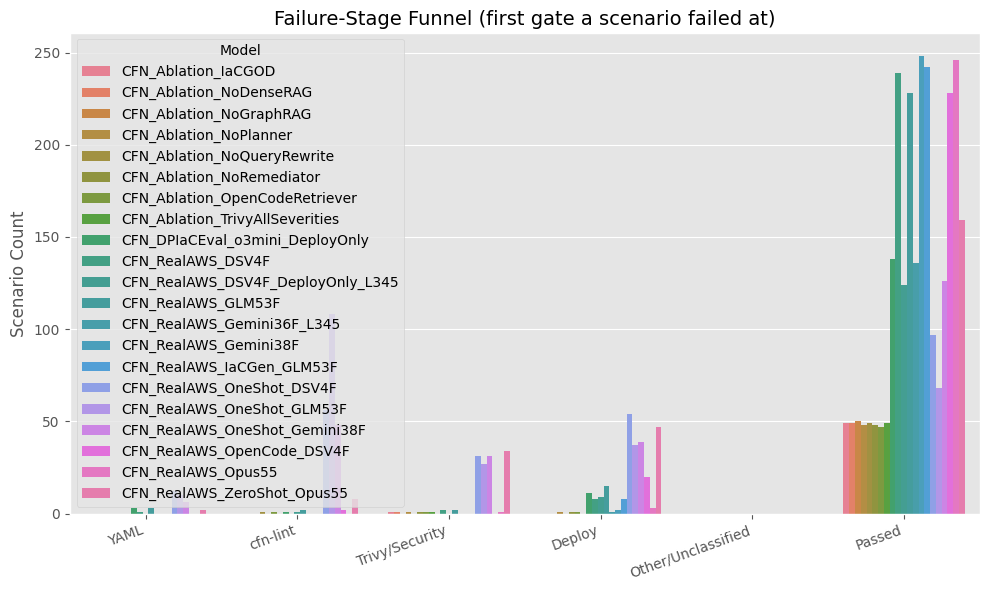

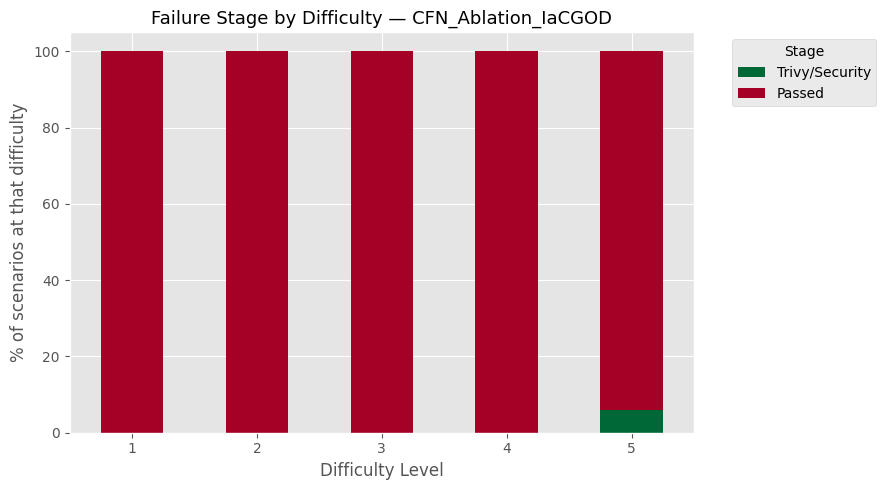

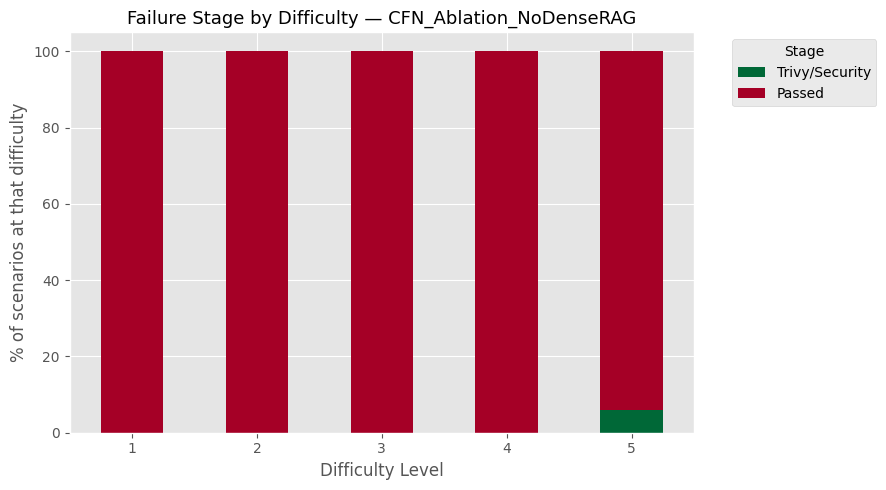

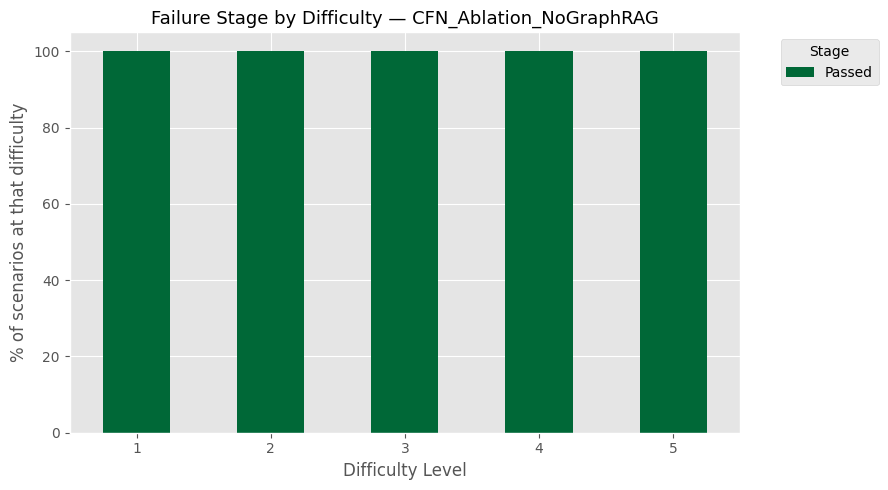

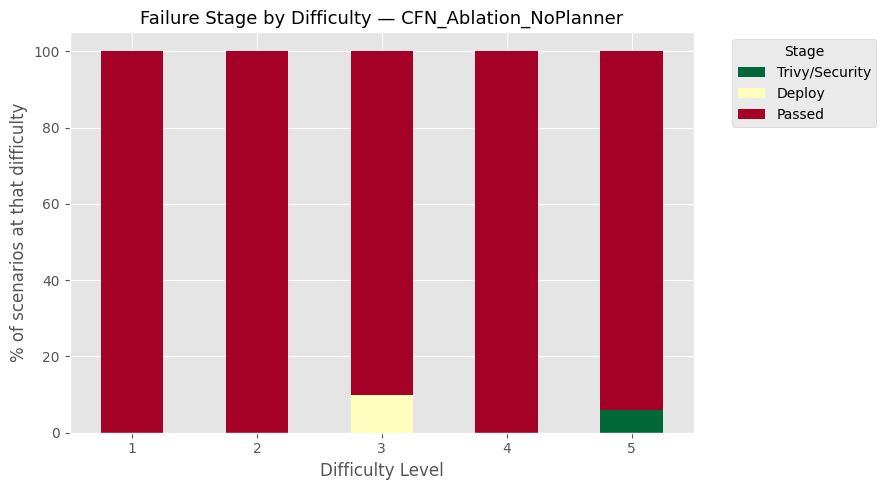

...

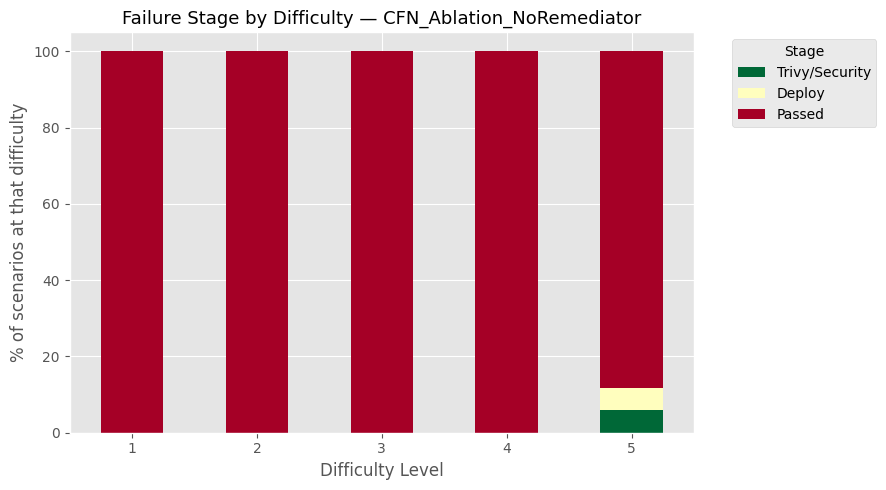

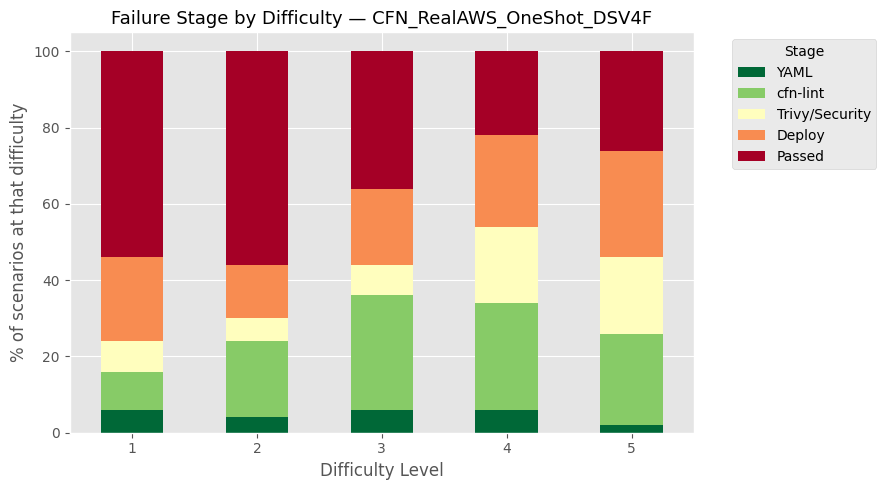

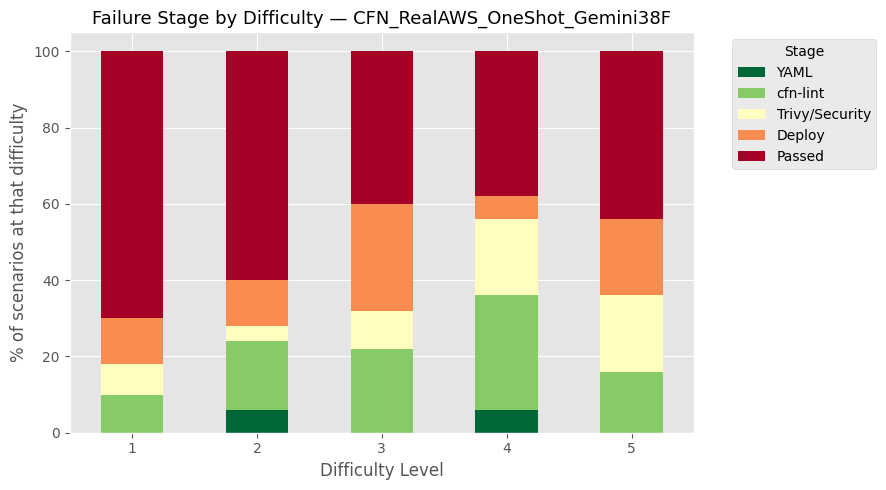

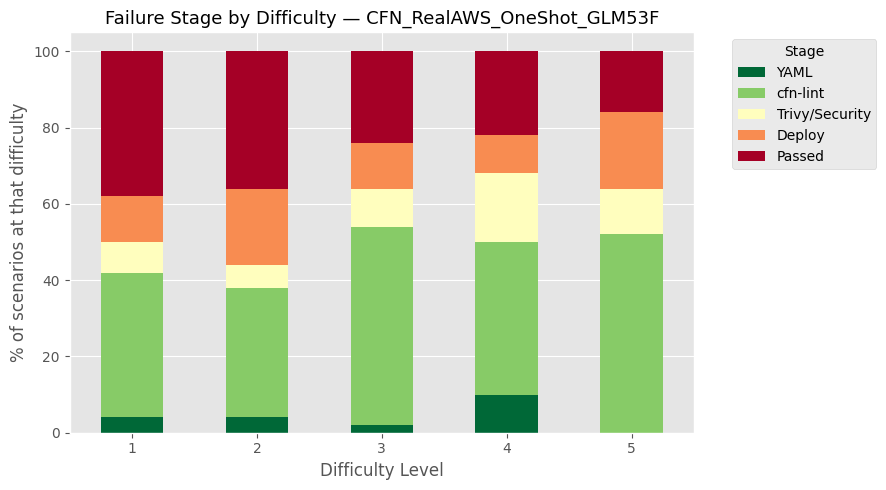

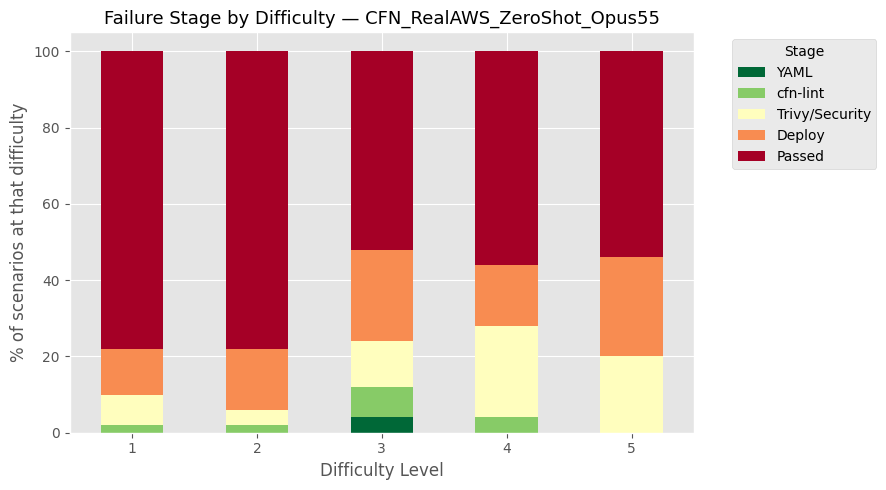

None

In [23]:
STAGE_CONFIG = [
    {"key": "yaml",     "label": "YAML",           "all_col": "all_yaml_errors",     "latest_col": "latest_error_yaml",     "passed_col": "val_stage_yaml_passed"},
    {"key": "cfn-lint", "label": "cfn-lint",        "all_col": "all_cfn_lint_errors", "latest_col": "latest_error_cfn-lint", "passed_col": "val_stage_cfn-lint_passed"},
    {"key": "trivy",    "label": "Trivy/Security",  "all_col": "all_security_errors", "latest_col": "latest_error_trivy",   "passed_col": "val_stage_trivy_passed"},
]
def _plot_failure_stage_funnel(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}

    def compute_failure_stage(row: pd.Series) -> str:
        for stage in STAGE_CONFIG:
            col = stage["passed_col"]
            if col in row.index and row[col] is False:
                return stage["label"]
        if "deploy_passed" in row.index and row["deploy_passed"] is False:
            return "Deploy"
        if "final_validation_passed" in row.index and row["final_validation_passed"] is False:
            return "Other/Unclassified"
        return "Passed"

    funnel_rows = []
    for model_name, df in dfs.items():
        if "final_validation_passed" not in df.columns:
            continue
        df["failure_stage"] = df.apply(compute_failure_stage, axis=1)
        counts = df["failure_stage"].value_counts()
        for stage_label, cnt in counts.items():
            funnel_rows.append({"Model": model_name, "Stage": stage_label, "Count": cnt, "Pct": cnt / len(df) * 100})

    if funnel_rows:
        funnel_df = pd.DataFrame(funnel_rows)
        stage_order = [s["label"] for s in STAGE_CONFIG] + ["Deploy", "Other/Unclassified", "Passed"]
        funnel_df["Stage"] = pd.Categorical(funnel_df["Stage"], categories=stage_order, ordered=True)
        funnel_df = funnel_df.sort_values(["Model", "Stage"])

        print("📊 Failure-stage funnel (first gate that stopped each scenario):")
        with pd.option_context('display.max_rows', None):
            display(funnel_df.pivot(index="Stage", columns="Model", values="Count").fillna(0).astype(int))

        plt.figure(figsize=(10, 6))
        sns.barplot(data=funnel_df, x="Stage", y="Count", hue="Model", order=stage_order)
        plt.title("Failure-Stage Funnel (first gate a scenario failed at)", fontsize=14)
        plt.ylabel("Scenario Count")
        plt.xlabel("")
        plt.xticks(rotation=20, ha="right")
        plt.legend(title="Model")
        plt.tight_layout()
        plt.show()

        for model_name, df in dfs.items():
            if "difficulty_level" not in df.columns or "failure_stage" not in df.columns:
                continue
            cross = pd.crosstab(df["difficulty_level"], df["failure_stage"])
            cross = cross.reindex(columns=[s for s in stage_order if s in cross.columns])
            cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

            cross_pct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="RdYlGn_r")
            plt.title(f"Failure Stage by Difficulty — {model_name}", fontsize=13)
            plt.ylabel("% of scenarios at that difficulty")
            plt.xlabel("Difficulty Level")
            plt.xticks(rotation=0)
            plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc="upper left")
            plt.tight_layout()
            plt.show()
    else:
        print("⚠️ No models with 'final_validation_passed' / stage columns found.")

_out_failure_stage_funnel = widgets.interactive_output(_plot_failure_stage_funnel, {'selected_models': model_selector})
display(_out_failure_stage_funnel)

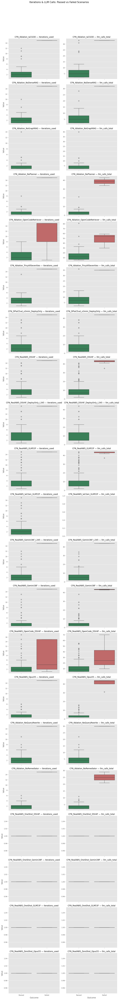

📊 Mean effort by outcome:


mean  median   max  \
Model                       Metric          Outcome                        
CFN_Ablation_IaCGOD         iterations_used Failed   15.00    15.0  15.0   
                                            Passed    3.04     2.0  12.0   
                            llm_calls_total Failed   33.00    33.0  33.0   
                                            Passed    7.69     5.0  33.0   
CFN_Ablation_NoDenseRAG     iterations_used Failed   15.00    15.0  15.0   
...                                                    ...     ...   ...   
CFN_RealAWS_Opus55          llm_calls_total Passed    3.42     2.0  16.0   
CFN_RealAWS_ZeroShot_Opus55 iterations_used Failed    1.00     1.0   1.0   
                                            Passed    1.00     1.0   1.0   
                            llm_calls_total Failed    1.00     1.0   1.0   
                                            Passed    1.00     1.0   1.0   

                                                     count  
Model                       Metric          Outcome         
CFN_Ablation_IaCGOD         iterations_used Failed       1  
                                            Passed      49  
                            llm_calls_total Failed       1  
                                            Passed      49  
CFN_Ablation_NoDenseRAG     iterations_used Failed       1  
...                                                    ...  
CFN_RealAWS_Opus55          llm_calls_total Passed     246  
CFN_RealAWS_ZeroShot_Opus55 iterations_used Failed      91  
                                            Passed     159  
                            llm_calls_total Failed      91  
                                            Passed     159  

[80 rows x 4 columns]

  CFN_Ablation_IaCGOD: 1/1 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  CFN_Ablation_NoDenseRAG: 1/1 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  CFN_Ablation_NoPlanner: 2/2 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  CFN_Ablation_OpenCodeRetriever: 2/3 failed scenarios (67%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  CFN_Ablation_TrivyAllSeverities: 1/1 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their budget.
  CFN_DPIaCEval_o3mini_DeployOnly: 15/15 failed scenarios (100%) hit the observed max iteration count (15) before giving up -- the rest failed before exhausting their

None

In [24]:
def _plot_effort_vs_outcome(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    effort_cols = [c for c in ["iterations_used", "llm_calls_total", "duration_seconds"] if True]

    effort_rows = []
    for model_name, df in dfs.items():
        if "final_validation_passed" not in df.columns or "iterations_used" not in df.columns:
            continue
        outcome = df["final_validation_passed"].map({True: "Passed", False: "Failed"})
        for col in ["iterations_used", "llm_calls_total"]:
            if col not in df.columns:
                continue
            tmp = pd.DataFrame({"Model": model_name, "Outcome": outcome, "Metric": col, "Value": df[col]})
            effort_rows.append(tmp)

    if effort_rows:
        effort_df = pd.concat(effort_rows, ignore_index=True).dropna(subset=["Value"])

        g = sns.catplot(
            data=effort_df, kind="box",
            x="Outcome", y="Value", hue="Outcome", col="Metric", row="Model",
            palette={"Passed": "seagreen", "Failed": "indianred"},
            height=4, aspect=1.3, sharey=False, legend=False,
        )
        g.set_titles("{row_name} — {col_name}")
        g.fig.suptitle("Iterations & LLM Calls: Passed vs Failed Scenarios", fontsize=15, y=1.03)
        plt.tight_layout()
        plt.show()

        print("📊 Mean effort by outcome:")
        summary = effort_df.groupby(["Model", "Metric", "Outcome"])["Value"].agg(["mean", "median", "max", "count"]).round(2)
        display(summary)

        for model_name, df in dfs.items():
            if "iterations_used" not in df.columns or "final_validation_passed" not in df.columns:
                continue
            max_iter = df["iterations_used"].max()
            exhausted = df[(df["final_validation_passed"] == False) & (df["iterations_used"] >= max_iter)]
            n_failed = (df["final_validation_passed"] == False).sum()
            if n_failed:
                print(f"  {model_name}: {len(exhausted)}/{n_failed} failed scenarios "
                      f"({len(exhausted)/n_failed:.0%}) hit the observed max iteration count ({max_iter:.0f}) "
                      f"before giving up -- the rest failed before exhausting their budget.")
    else:
        print("⚠️ No models with iteration/effort columns found.")

_out_effort_vs_outcome = widgets.interactive_output(_plot_effort_vs_outcome, {'selected_models': model_selector})
display(_out_effort_vs_outcome)

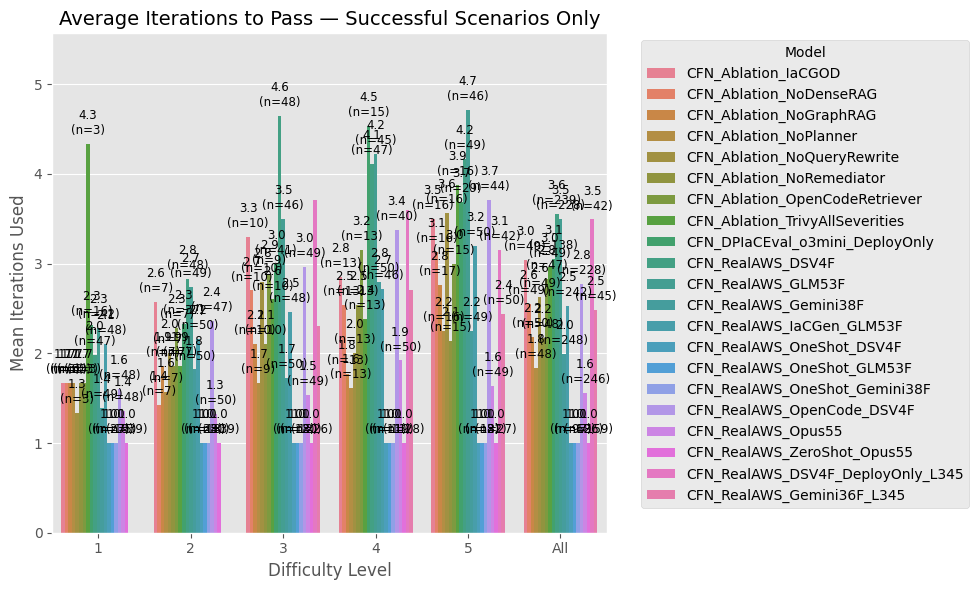

📊 Average iterations to pass, by difficulty (successful scenarios only):


,Model,Difficulty Level,N Passed,Mean Iterations,Median Iterations
0,CFN_Ablation_IaCGOD,1,3,1.67,2.0
1,CFN_Ablation_NoDenseRAG,1,3,1.67,1.0
2,CFN_Ablation_NoGraphRAG,1,3,1.67,2.0
3,CFN_Ablation_NoPlanner,1,3,1.67,1.0
4,CFN_Ablation_NoQueryRewrite,1,3,1.33,1.0
...,...,...,...,...,...
117,CFN_RealAWS_OneShot_GLM53F,All,68,1.00,1.0
118,CFN_RealAWS_OneShot_Gemini38F,All,126,1.00,1.0
119,CFN_RealAWS_OpenCode_DSV4F,All,228,2.77,2.0
120,CFN_RealAWS_Opus55,All,246,1.55,1.0


None

In [25]:
def _plot_avg_iterations_to_pass(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    avg_iter_rows = []
    for model_name, df in dfs.items():
        if "final_validation_passed" not in df.columns or "iterations_used" not in df.columns:
            continue
        diff_col = "difficulty_level" if "difficulty_level" in df.columns else "difficulty"
        if diff_col not in df.columns:
            continue
        passed = df[df["final_validation_passed"] == True]
        grouped = passed.groupby(diff_col)["iterations_used"].agg(["mean", "median", "count"])
        for diff, row in grouped.iterrows():
            avg_iter_rows.append({
                "Model": model_name, "Difficulty Level": diff,
                "Mean Iterations": row["mean"], "Median Iterations": row["median"], "N Passed": int(row["count"]),
            })
        if len(passed):
            avg_iter_rows.append({
                "Model": model_name, "Difficulty Level": "All",
                "Mean Iterations": passed["iterations_used"].mean(),
                "Median Iterations": passed["iterations_used"].median(), "N Passed": len(passed),
            })

    if avg_iter_rows:
        avg_iter_df = pd.DataFrame(avg_iter_rows)
        order = sorted([d for d in avg_iter_df["Difficulty Level"].unique() if d != "All"]) + ["All"]
        avg_iter_df["Difficulty Level"] = pd.Categorical(avg_iter_df["Difficulty Level"], categories=order, ordered=True)
        avg_iter_df = avg_iter_df.sort_values(["Difficulty Level", "Model"])

        plt.figure(figsize=(10, 6))
        ax = sns.barplot(data=avg_iter_df, x="Difficulty Level", y="Mean Iterations", hue="Model", order=order)
        plt.title("Average Iterations to Pass — Successful Scenarios Only", fontsize=14)
        plt.ylim(0, avg_iter_df["Mean Iterations"].max() * 1.18)
        plt.ylabel("Mean Iterations Used")
        plt.xlabel("Difficulty Level")
        plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")

        for i, container in enumerate(ax.containers):
            model_name = ax.get_legend().get_texts()[i].get_text()
            for j, p in enumerate(container):
                height = p.get_height()
                if pd.isna(height) or (height == 0 and p.get_y() == 0):
                    continue
                diff_level = ax.get_xticklabels()[j].get_text()
                row = avg_iter_df[(avg_iter_df["Model"] == model_name) & (avg_iter_df["Difficulty Level"].astype(str) == diff_level)]
                if not row.empty:
                    n = row["N Passed"].values[0]
                    ax.annotate(f"{height:.1f}\n(n={n})", (p.get_x() + p.get_width() / 2., height),
                                ha="center", va="bottom", xytext=(0, 5), textcoords="offset points", fontsize=8.5)

        plt.tight_layout()
        plt.show()

        print("📊 Average iterations to pass, by difficulty (successful scenarios only):")
        display(avg_iter_df[["Model", "Difficulty Level", "N Passed", "Mean Iterations", "Median Iterations"]]
                .round(2).reset_index(drop=True))
    else:
        print("⚠️ No models with iterations_used/final_validation_passed/difficulty columns found.")

_out_avg_iterations_to_pass = widgets.interactive_output(_plot_avg_iterations_to_pass, {'selected_models': model_selector})
display(_out_avg_iterations_to_pass)

📊 Token & duration totals per model:


,total_tokens,mean_tokens,total_input_tokens,total_output_tokens,mean_duration_s,total_est_cost_usd
Model,,,,,,
CFN_Ablation_IaCGOD,8982452.0,179649.04,0.0,0.0,559.50,0.0
CFN_Ablation_NoDenseRAG,8689442.0,173788.84,0.0,0.0,239.91,0.0
CFN_Ablation_NoGraphRAG,5114027.0,102280.54,0.0,0.0,150.23,0.0
CFN_Ablation_NoPlanner,6387380.0,127747.60,0.0,0.0,158.31,0.0
CFN_Ablation_NoQueryRewrite,8620267.0,172405.34,0.0,0.0,223.11,0.0
CFN_Ablation_NoRemediator,5651288.0,113025.76,0.0,0.0,193.87,0.0
CFN_Ablation_OpenCodeRetriever,3218109.0,64362.18,2879300.0,338809.0,298.27,0.0
CFN_Ablation_TrivyAllSeverities,10388690.0,207773.80,0.0,0.0,231.56,0.0
CFN_DPIaCEval_o3mini_DeployOnly,18977550.0,124036.27,0.0,0.0,1866.66,0.0


  ℹ️ INPUT_COST_PER_MTOK / OUTPUT_COST_PER_MTOK are both 0 -- set them above to see $ estimates instead of just token counts.


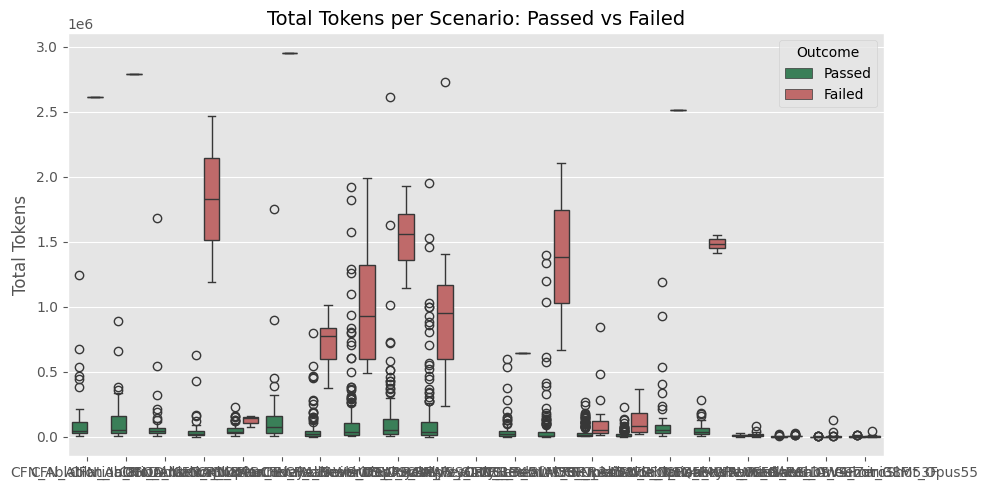

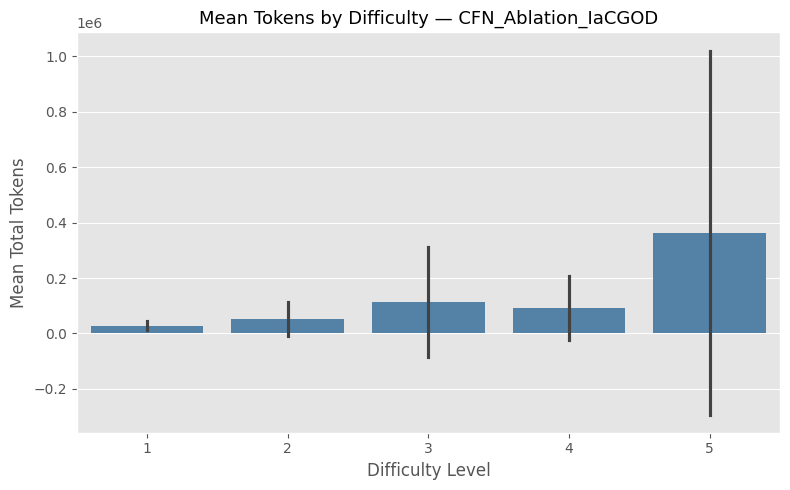

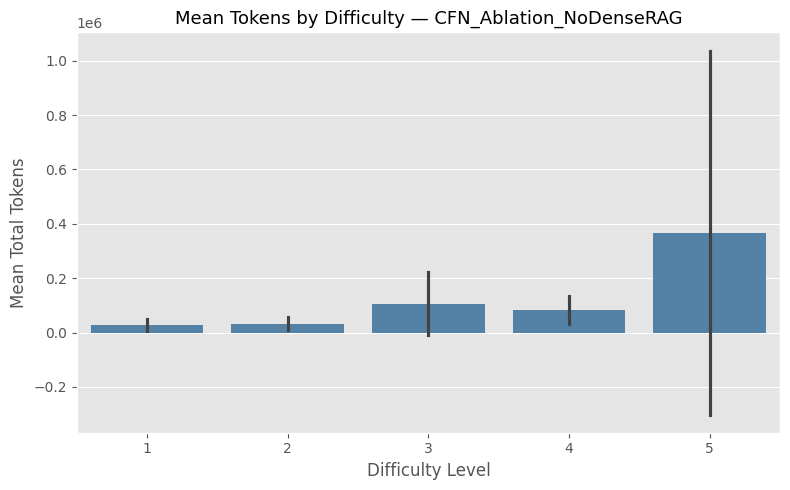

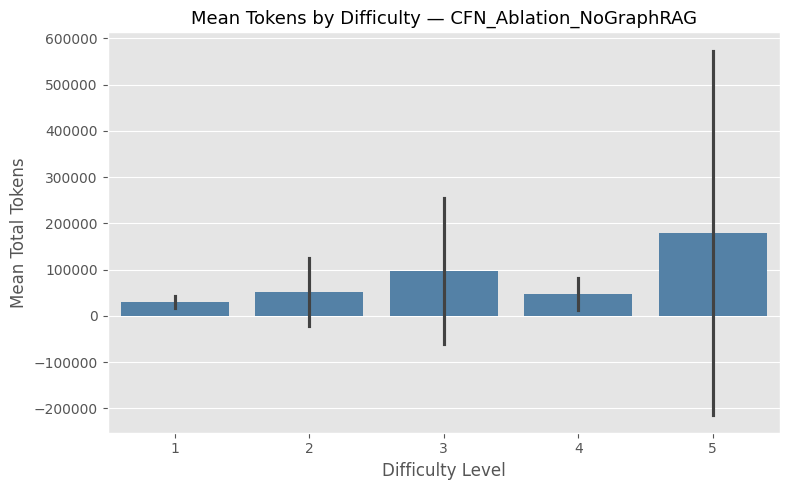

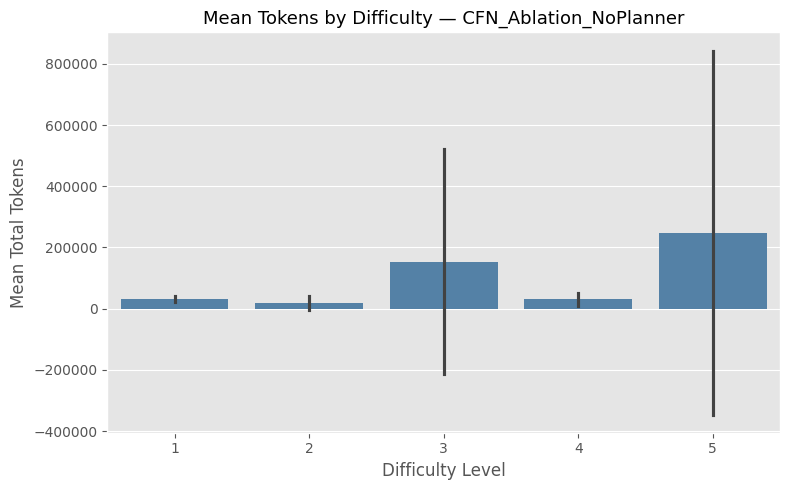

...

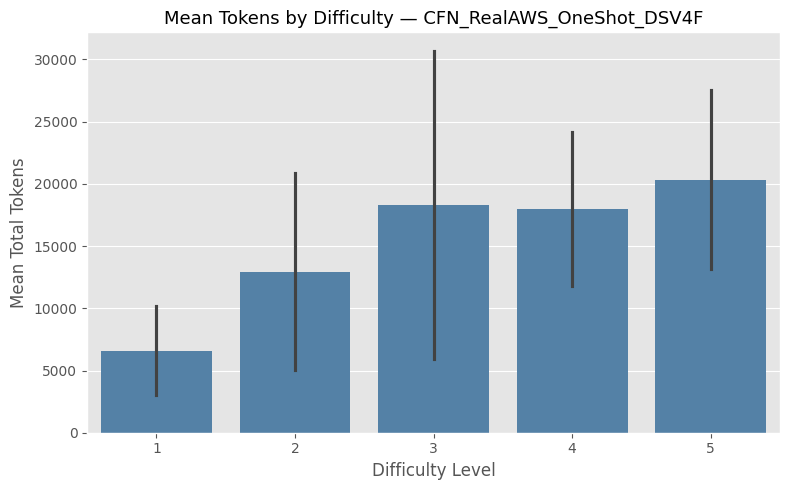

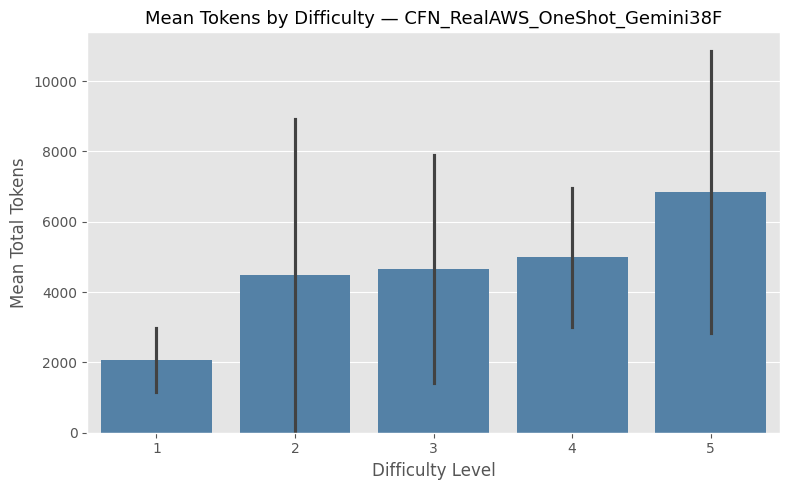

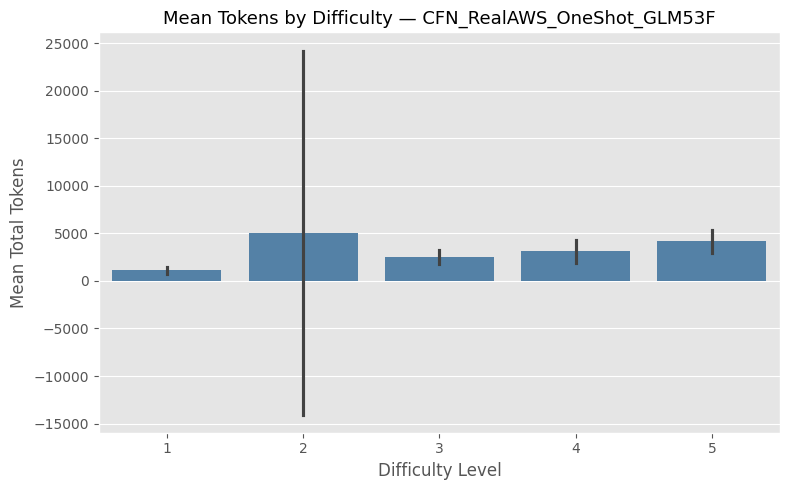

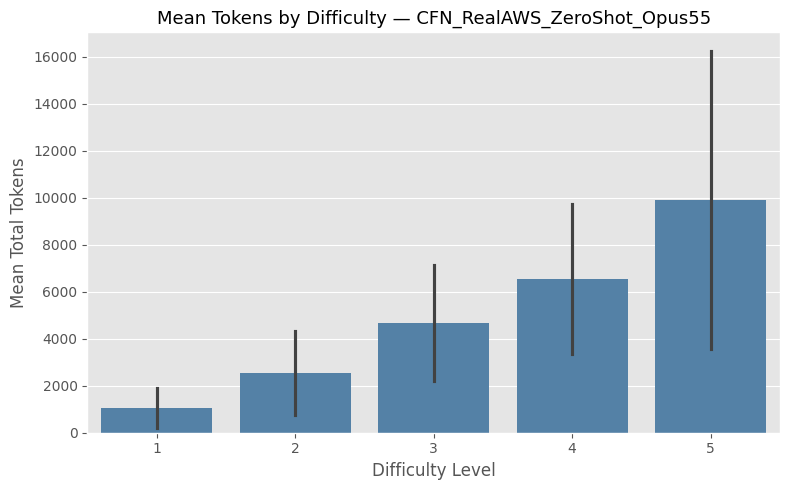

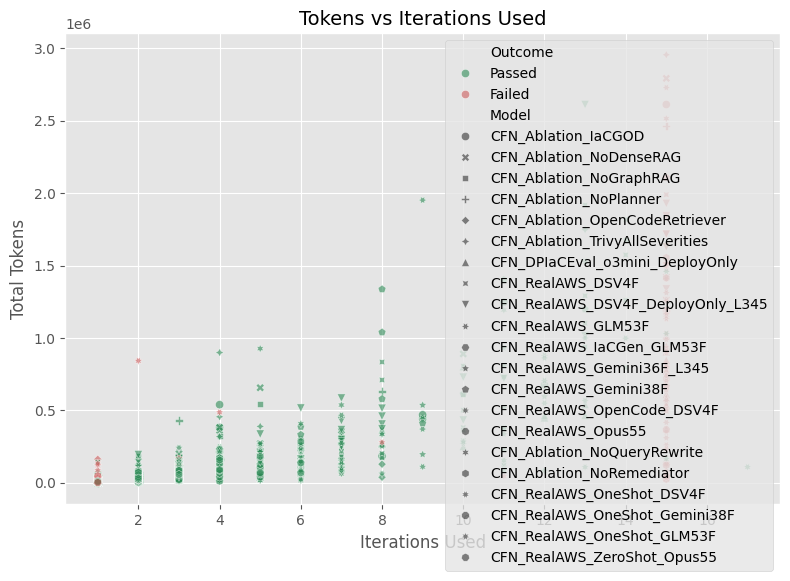

None

In [26]:
def _plot_token_cost_duration(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}
    INPUT_COST_PER_MTOK = 0.0
    OUTPUT_COST_PER_MTOK = 0.0

    token_cols_present = {c for c in ["token_input_tokens", "token_output_tokens", "token_all_tokens"]
                           if any(c in df.columns for df in dfs.values())}

    if token_cols_present:
        cost_rows = []
        for model_name, df in dfs.items():
            if "token_all_tokens" not in df.columns:
                continue
            d = df.copy()
            d["est_cost_usd"] = (
                d.get("token_input_tokens", 0).fillna(0) / 1_000_000 * INPUT_COST_PER_MTOK
                + d.get("token_output_tokens", 0).fillna(0) / 1_000_000 * OUTPUT_COST_PER_MTOK
            )
            d["Model"] = model_name
            d["Outcome"] = d["final_validation_passed"].map({True: "Passed", False: "Failed"}) \
                if "final_validation_passed" in d.columns else "Unknown"
            cost_rows.append(d[["Model", "Outcome", "token_input_tokens", "token_output_tokens",
                                 "token_all_tokens", "iterations_used", "duration_seconds", "est_cost_usd"]])

        cost_df = pd.concat(cost_rows, ignore_index=True)

        print("📊 Token & duration totals per model:")
        totals = cost_df.groupby("Model").agg(
            total_tokens=("token_all_tokens", "sum"),
            mean_tokens=("token_all_tokens", "mean"),
            total_input_tokens=("token_input_tokens", "sum"),
            total_output_tokens=("token_output_tokens", "sum"),
            mean_duration_s=("duration_seconds", "mean"),
            total_est_cost_usd=("est_cost_usd", "sum"),
        ).round(2)
        display(totals)

        if (INPUT_COST_PER_MTOK == 0) and (OUTPUT_COST_PER_MTOK == 0):
            print("  ℹ️ INPUT_COST_PER_MTOK / OUTPUT_COST_PER_MTOK are both 0 -- "
                  "set them above to see $ estimates instead of just token counts.")

        plt.figure(figsize=(10, 5))
        sns.boxplot(data=cost_df, x="Model", y="token_all_tokens", hue="Outcome",
                    palette={"Passed": "seagreen", "Failed": "indianred", "Unknown": "gray"})
        plt.title("Total Tokens per Scenario: Passed vs Failed", fontsize=14)
        plt.ylabel("Total Tokens")
        plt.xlabel("")
        plt.tight_layout()
        plt.show()

        for model_name, df in dfs.items():
            if "difficulty_level" not in df.columns or "token_all_tokens" not in df.columns:
                continue
            plt.figure(figsize=(8, 5))
            sns.barplot(data=df, x="difficulty_level", y="token_all_tokens", errorbar="sd", color="steelblue")
            plt.title(f"Mean Tokens by Difficulty — {model_name}", fontsize=13)
            plt.xlabel("Difficulty Level")
            plt.ylabel("Mean Total Tokens")
            plt.tight_layout()
            plt.show()

        if cost_df["est_cost_usd"].sum() > 0:
            eff = cost_df.groupby(["Model", "Outcome"])["est_cost_usd"].agg(["sum", "mean", "count"]).round(4)
            print("\n📊 Cost efficiency (est. $ spent, passed vs failed):")
            display(eff)

        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=cost_df, x="iterations_used", y="token_all_tokens", hue="Outcome",
                         style="Model", alpha=0.6,
                         palette={"Passed": "seagreen", "Failed": "indianred", "Unknown": "gray"})
        plt.title("Tokens vs Iterations Used", fontsize=14)
        plt.xlabel("Iterations Used")
        plt.ylabel("Total Tokens")
        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ No token columns found in any model's dataframe.")

_out_token_cost_duration = widgets.interactive_output(_plot_token_cost_duration, {'selected_models': model_selector})
display(_out_token_cost_duration)

## Common Failures / Failure Patterns

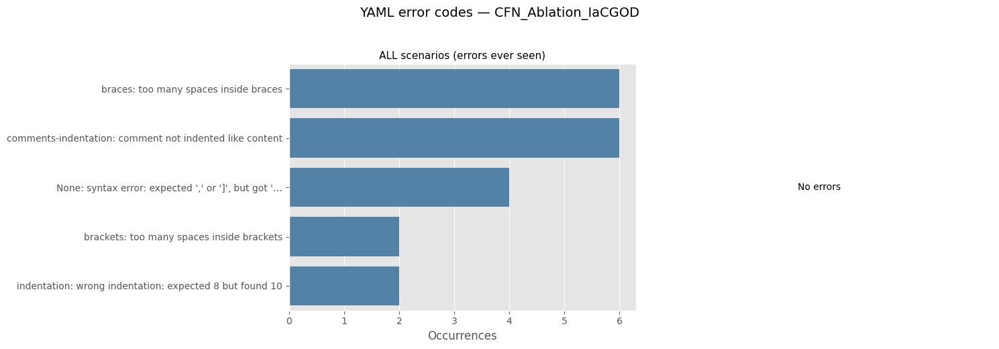

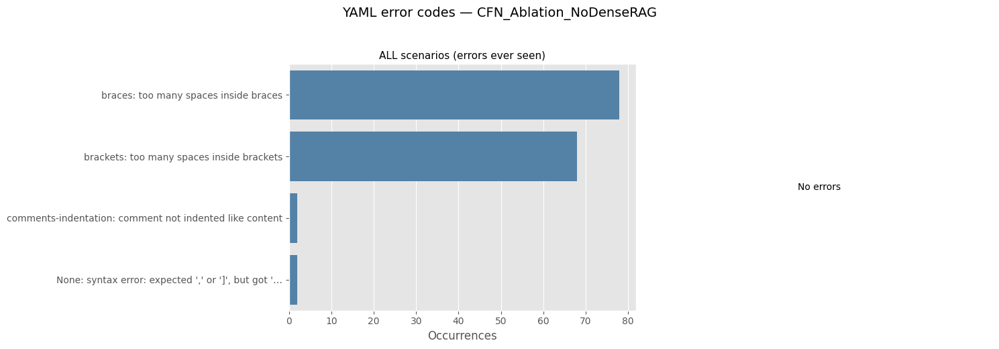

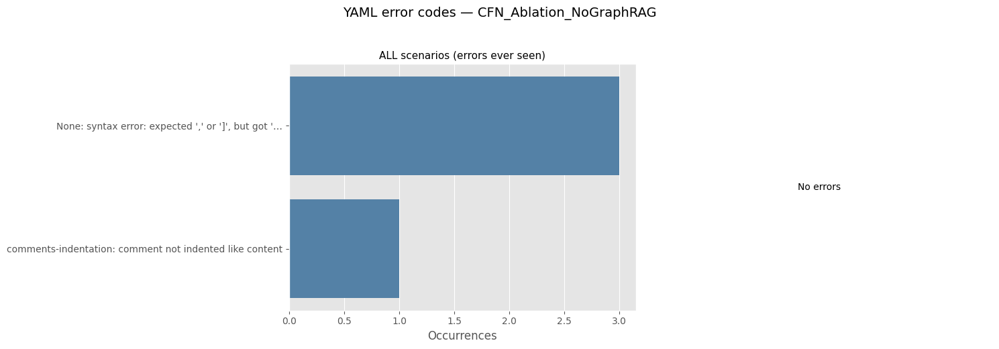

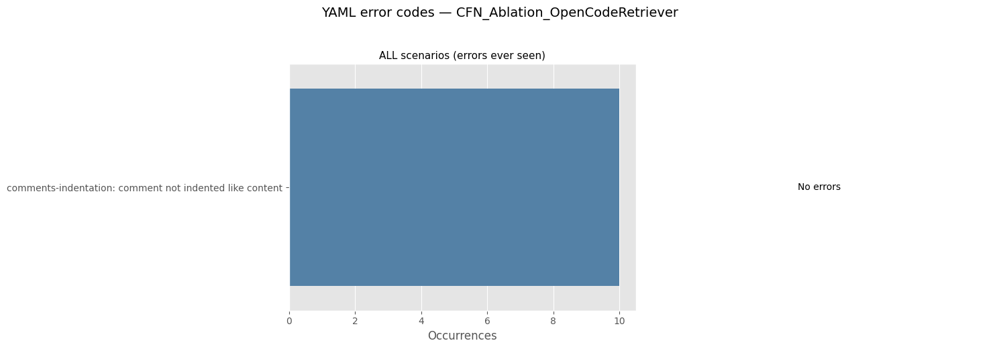

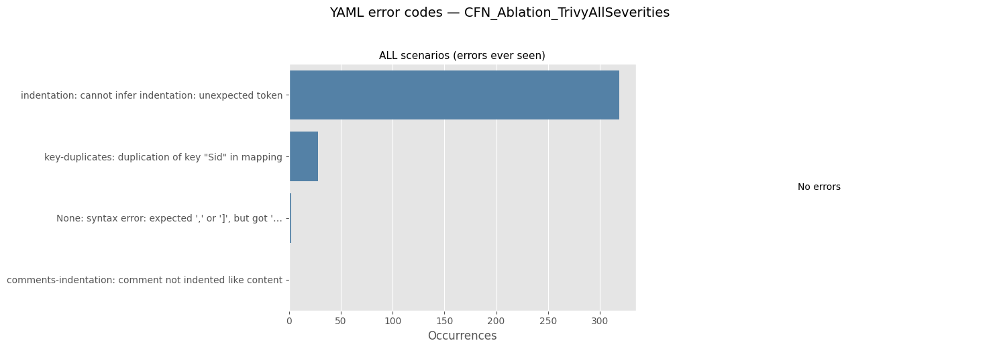

...

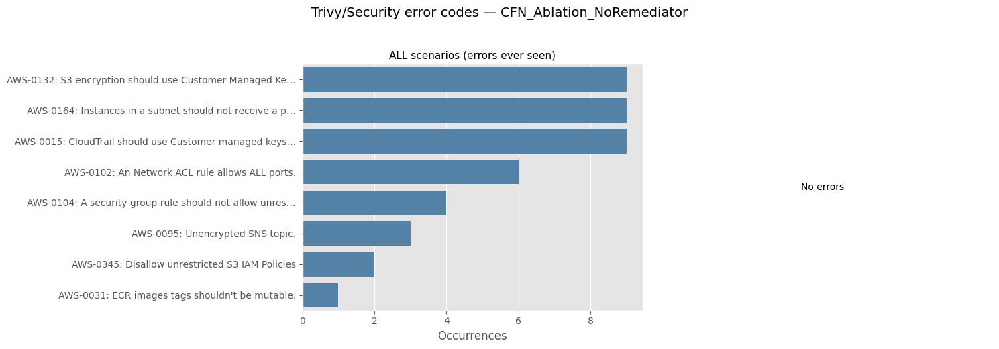

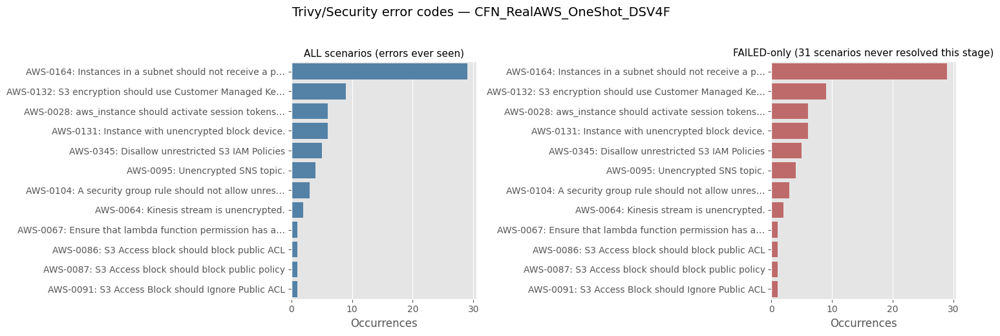

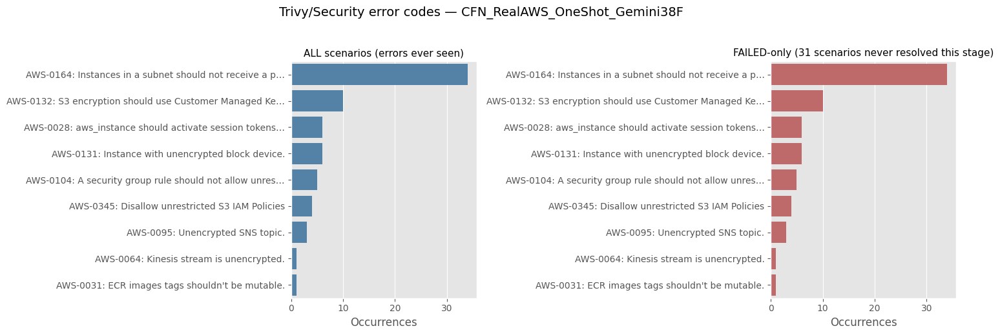

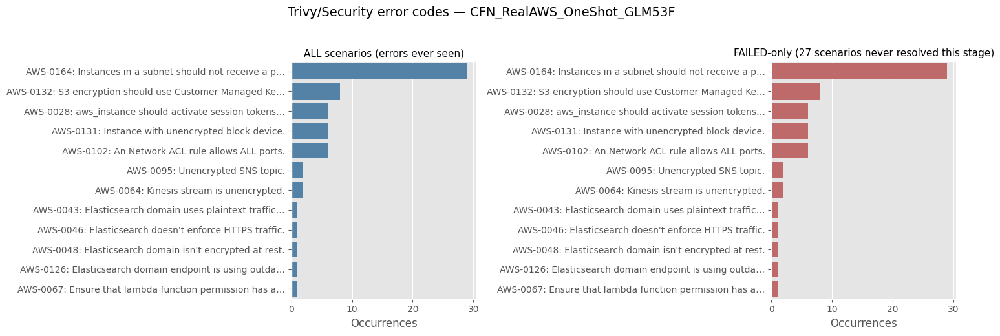

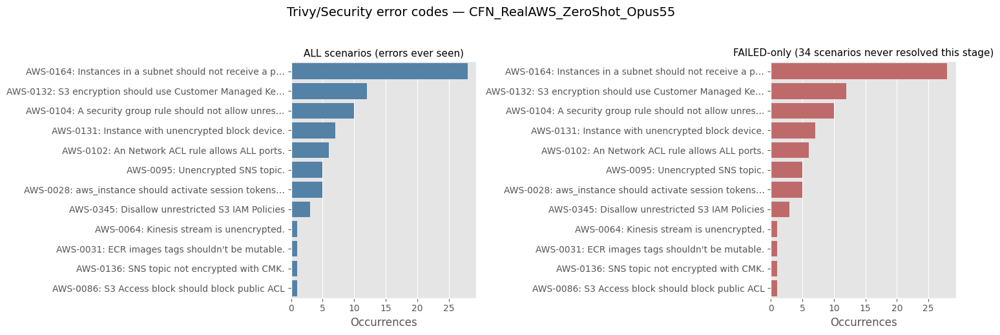

In [27]:
import re
from collections import defaultdict

CODE_RE = re.compile(r"\[([A-Za-z0-9_.\-]{1,20})\]")
GOOD_CODE_RE = re.compile(r"^(?:[EWI]\d{3,4}|AWS-\d{3,4}|[a-z][a-z_-]{2,19}|None)$")
_LINE_PREFIX_RE = re.compile(r"^\s*line\s+\d+(?:\s*,\s*column\s+\d+)?\s*:?\s*", re.I)
_RESOURCE_ONLY_RE = re.compile(r"^\s*Resource:\s*\S+\s*$", re.I)
_LINE_ONLY_RE = re.compile(r"^\s*line\s+\d+\s*$", re.I)
_SEVERITY_RE = re.compile(r"^\s*(CRITICAL|HIGH|MEDIUM|LOW)\s*:\s*", re.I)

CODE_MESSAGES = defaultdict(Counter)

def extract_error_entries(text) -> list:
    if not isinstance(text, str) or not text.strip():
        return []
    matches = list(CODE_RE.finditer(text))
    entries = []
    for i, m in enumerate(matches):
        code = m.group(1)
        if not GOOD_CODE_RE.match(code):
            continue
        start = m.end()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        segs = [s.strip() for s in text[start:end].split("|") if s.strip()]
        msg = ""
        for seg in segs:
            if _LINE_ONLY_RE.match(seg) or _RESOURCE_ONLY_RE.match(seg):
                continue
            seg = _SEVERITY_RE.sub("", _LINE_PREFIX_RE.sub("", seg)).strip()
            if " — " in seg:
                seg = seg.split(" — ", 1)[0].strip()
            if seg:
                msg = seg
                break
        entries.append((code, msg))
    return entries

def extract_error_codes(text) -> list:
    return [c for c, _ in extract_error_entries(text)]

def record_messages(entries) -> None:
    for code, msg in entries:
        if msg:
            CODE_MESSAGES[code][msg] += 1

def truncate_msg(msg: str, width: int = 45) -> str:
    msg = re.sub(r"\s+", " ", msg).strip()
    return msg if len(msg) <= width else msg[: width - 1].rstrip() + "…"

def describe_code(code: str, width: int = 45) -> str:
    msgs = CODE_MESSAGES.get(code)
    if not msgs:
        return code
    best_msg, _ = msgs.most_common(1)[0]
    return f"{code}: {truncate_msg(best_msg, width)}"

def top_codes_from_column(df: pd.DataFrame, col: str, mask: pd.Series = None) -> Counter:
    counter = Counter()
    series = df[col] if mask is None else df.loc[mask, col]
    for txt in series.dropna():
        entries = extract_error_entries(txt)
        counter.update(c for c, _ in entries)
        record_messages(entries)
    return counter

for stage in STAGE_CONFIG:
    for model_name, df in merged_dataframes.items():
        if stage["all_col"] not in df.columns or stage["passed_col"] not in df.columns:
            continue

        all_counter = top_codes_from_column(df, stage["all_col"])
        failed_mask = df[stage["passed_col"]] == False
        failed_counter = top_codes_from_column(df, stage["latest_col"], mask=failed_mask)

        if not all_counter and not failed_counter:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        for ax, counter, title, color in [
            (axes[0], all_counter, f"ALL scenarios (errors ever seen)", "steelblue"),
            (axes[1], failed_counter, f"FAILED-only ({int(failed_mask.sum())} scenarios never resolved this stage)", "indianred"),
        ]:
            top = pd.DataFrame(counter.most_common(12), columns=["Code", "Count"])
            if top.empty:
                ax.text(0.5, 0.5, "No errors", ha="center", va="center")
                ax.set_axis_off()
                continue
            top["Label"] = top["Code"].apply(describe_code)
            sns.barplot(data=top, y="Label", x="Count", color=color, ax=ax)
            ax.set_title(title, fontsize=11)
            ax.set_xlabel("Occurrences")
            ax.set_ylabel("")
        fig.suptitle(f"{stage['label']} error codes — {model_name}", fontsize=14, y=1.03)
        plt.tight_layout()
        plt.show()

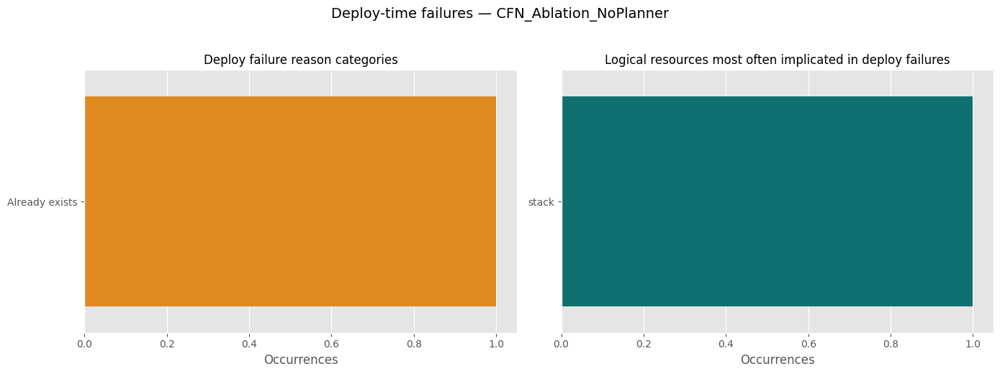

  CFN_Ablation_NoPlanner: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


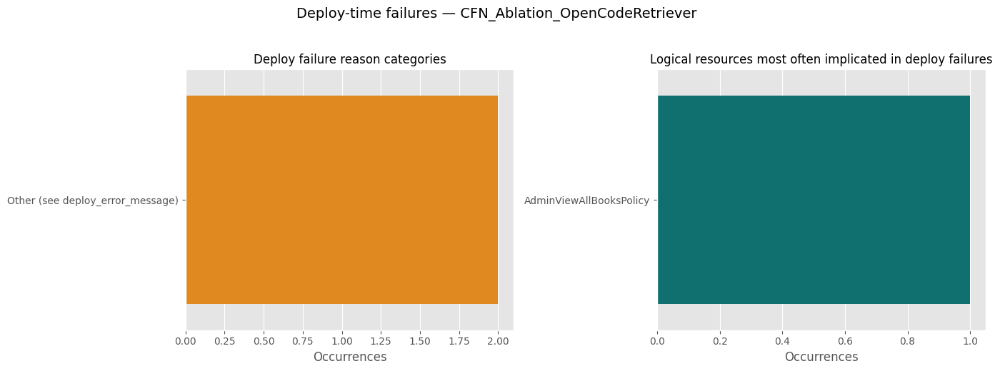

  CFN_Ablation_OpenCodeRetriever: 3 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


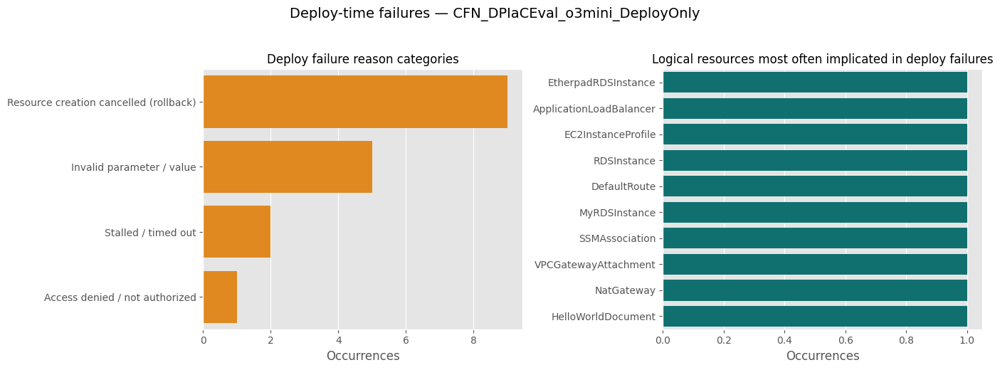

  CFN_DPIaCEval_o3mini_DeployOnly: 11 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


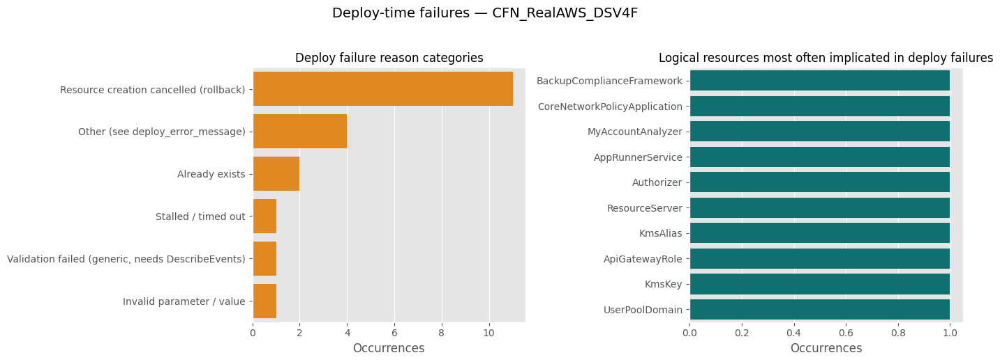

  CFN_RealAWS_DSV4F: 8 scenario(s) failed to deploy; 1 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


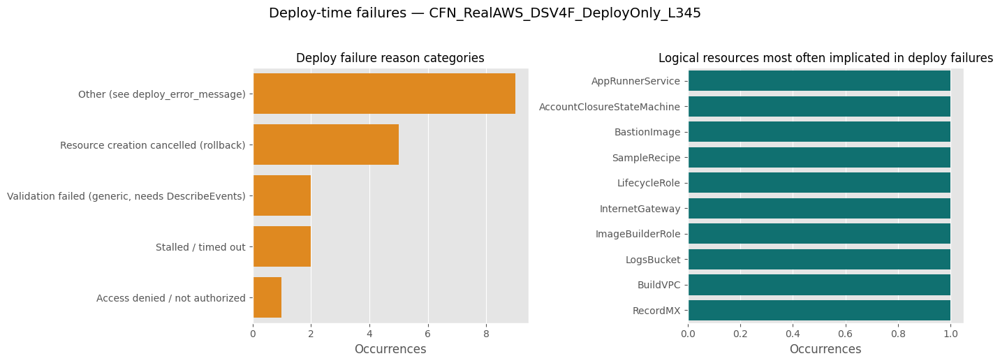

  CFN_RealAWS_DSV4F_DeployOnly_L345: 9 scenario(s) failed to deploy; 2 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


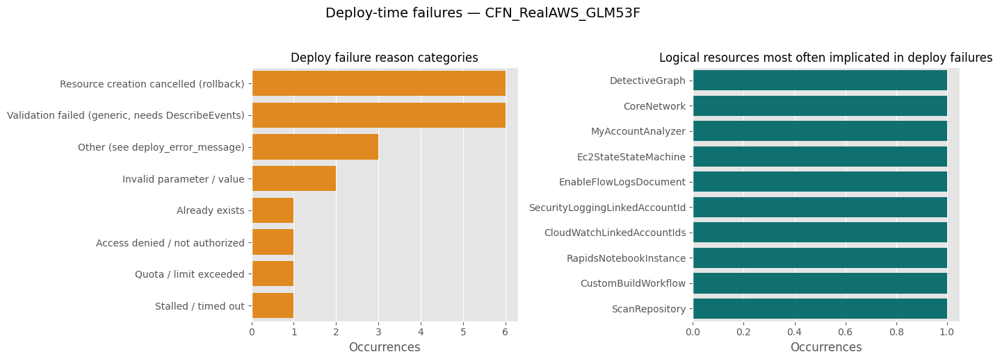

  CFN_RealAWS_GLM53F: 15 scenario(s) failed to deploy; 6 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


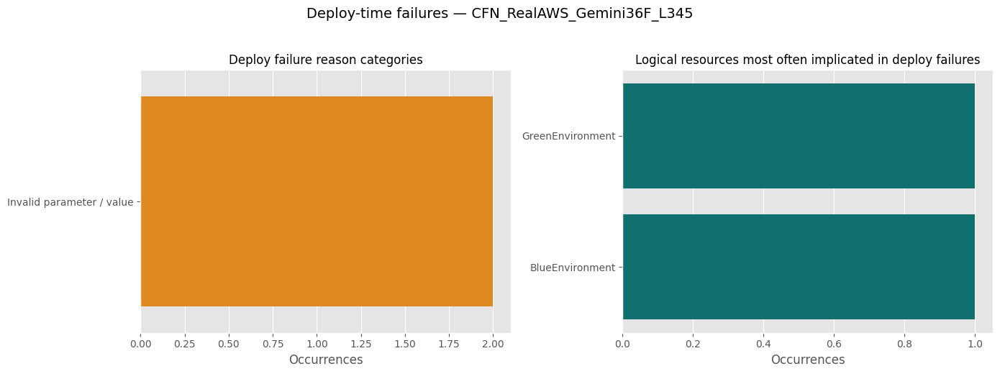

  CFN_RealAWS_Gemini36F_L345: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


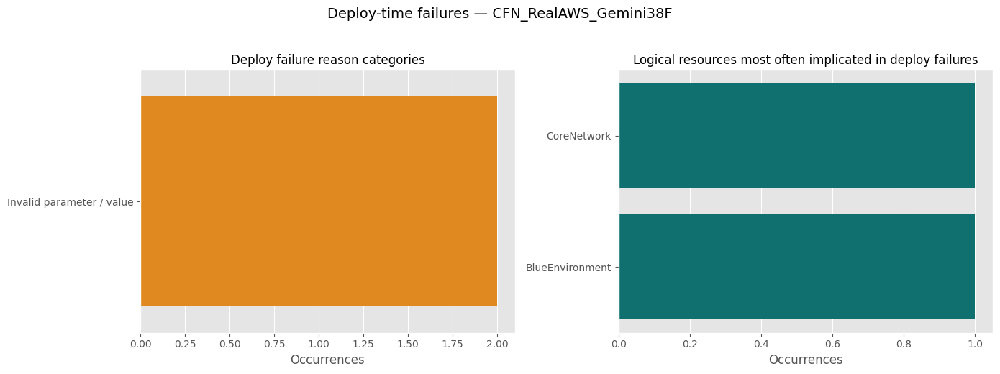

  CFN_RealAWS_Gemini38F: 2 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


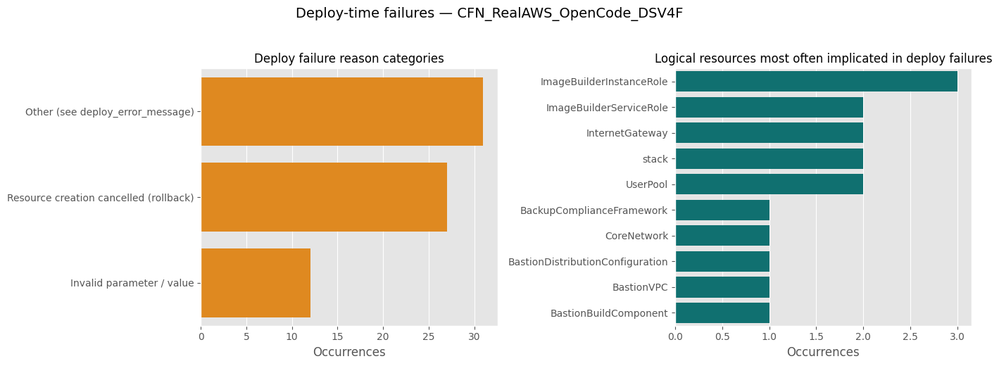

  CFN_RealAWS_OpenCode_DSV4F: 22 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


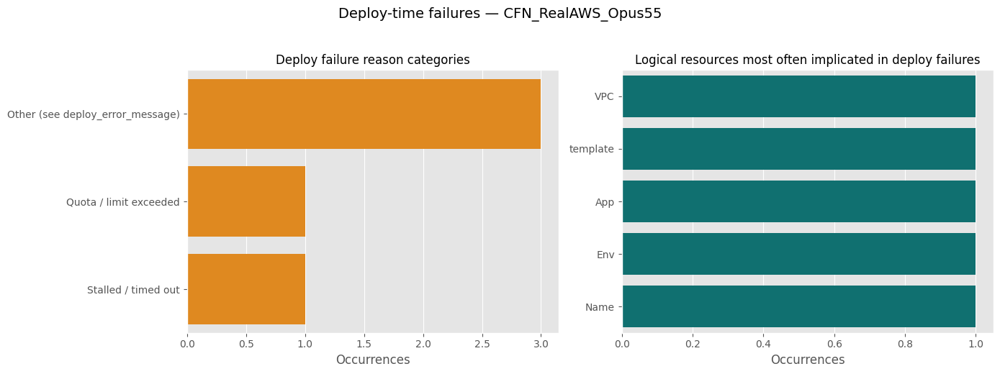

  CFN_RealAWS_Opus55: 3 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


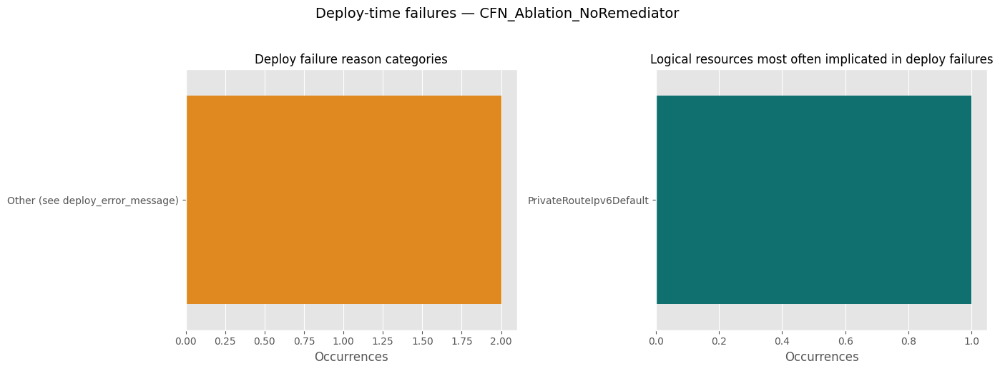

  CFN_Ablation_NoRemediator: 1 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


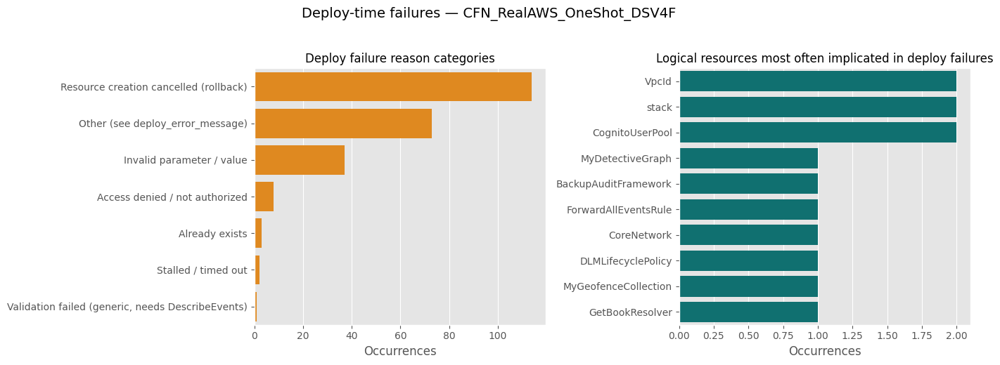

  CFN_RealAWS_OneShot_DSV4F: 54 scenario(s) failed to deploy; 1 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


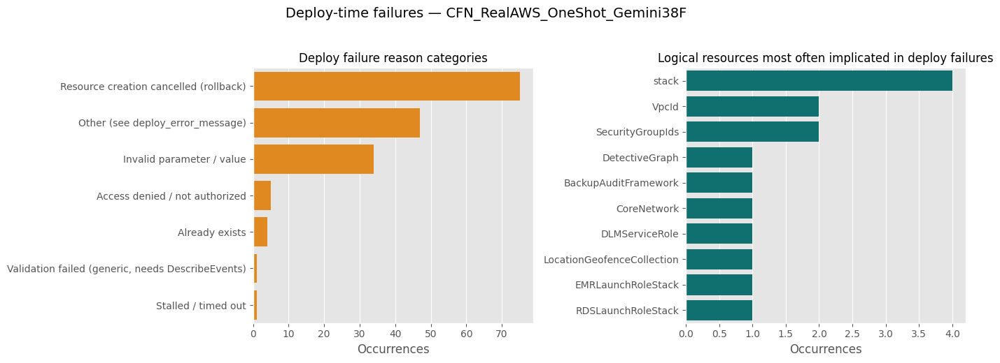

  CFN_RealAWS_OneShot_Gemini38F: 39 scenario(s) failed to deploy; 1 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


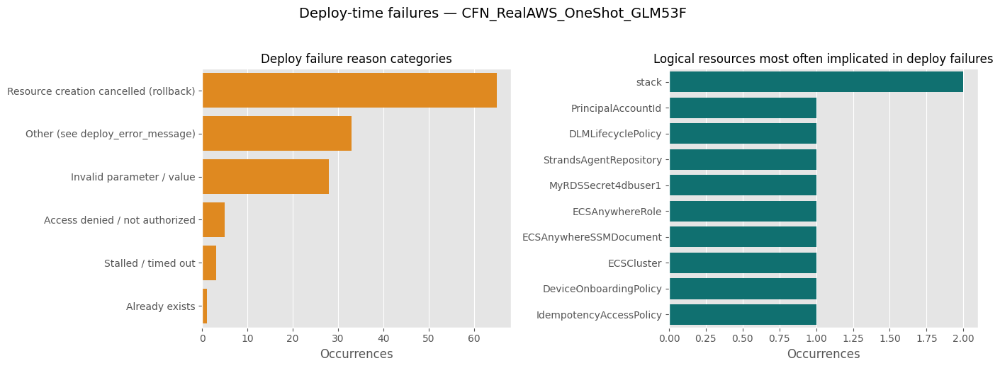

  CFN_RealAWS_OneShot_GLM53F: 37 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


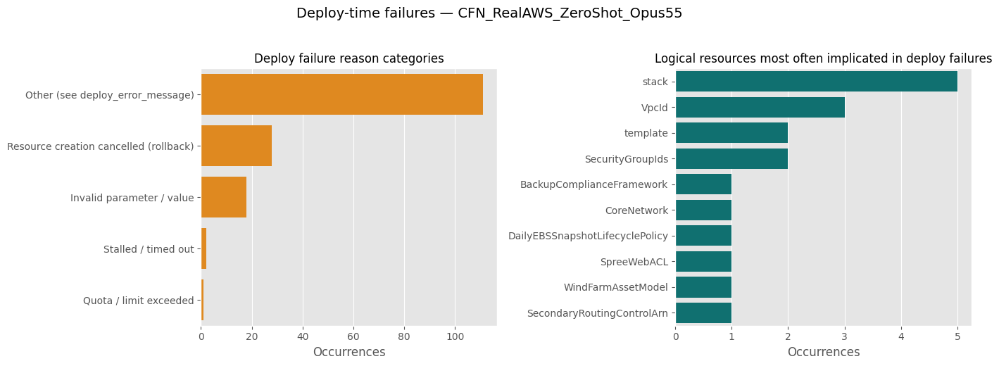

  CFN_RealAWS_ZeroShot_Opus55: 47 scenario(s) failed to deploy; 0 of the reported reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS console/CLI to see the real underlying error.


In [28]:
import json as _json

DEPLOY_SIGNATURES = [
    ("Resource creation cancelled (rollback)", re.compile(r"creation cancelled", re.I)),
    ("Stalled / timed out", re.compile(r"stalled|timed?\s*out|>\s*\d+s\b", re.I)),
    ("Already exists", re.compile(r"already\s*exists", re.I)),
    ("Access denied / not authorized", re.compile(r"access\s*denied|not\s*authorized|forbidden", re.I)),
    ("Invalid parameter / value", re.compile(r"invalid\s*(parameter|value|request|instanceid|json)", re.I)),
    ("Quota / limit exceeded", re.compile(r"limit\s*exceeded|quota", re.I)),
    ("Validation failed (generic, needs DescribeEvents)", re.compile(r"validation\s*failed", re.I)),
]
STACK_NAME_RE = re.compile(r"^iac-god-eval-[0-9a-f]{6,}$")

def parse_deploy_failed_resources(cell):
    if not isinstance(cell, str) or not cell.strip():
        return []
    try:
        items = _json.loads(cell)
    except (ValueError, TypeError):
        return []
    out = []
    for it in items:
        if isinstance(it, dict):
            out.append((it.get("logical_name"), it.get("status_reason")))
    return out

def classify_deploy_reason(text) -> str:
    if not isinstance(text, str):
        return "Unknown"
    for label, pat in DEPLOY_SIGNATURES:
        if pat.search(text):
            return label
    return "Other (see deploy_error_message)"

for model_name, df in merged_dataframes.items():
    if "deploy_failed_resources" not in df.columns:
        continue

    reason_counter = Counter()
    resource_counter = Counter()
    for cell in df["deploy_failed_resources"].dropna():
        for name, reason in parse_deploy_failed_resources(cell):
            reason_counter[classify_deploy_reason(reason)] += 1
            if name and not STACK_NAME_RE.match(name):
                resource_counter[name] += 1

    if not reason_counter:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    top_reasons = pd.DataFrame(reason_counter.most_common(10), columns=["Reason", "Count"])
    sns.barplot(data=top_reasons, y="Reason", x="Count", color="darkorange", ax=axes[0])
    axes[0].set_title("Deploy failure reason categories", fontsize=12)
    axes[0].set_xlabel("Occurrences")
    axes[0].set_ylabel("")

    top_res = pd.DataFrame(resource_counter.most_common(10), columns=["Logical Resource", "Count"])
    if not top_res.empty:
        sns.barplot(data=top_res, y="Logical Resource", x="Count", color="teal", ax=axes[1])
        axes[1].set_title("Logical resources most often implicated in deploy failures", fontsize=12)
        axes[1].set_xlabel("Occurrences")
        axes[1].set_ylabel("")
    else:
        axes[1].text(0.5, 0.5, "No per-resource detail\n(stack-level failure only)", ha="center", va="center")
        axes[1].set_axis_off()

    fig.suptitle(f"Deploy-time failures — {model_name}", fontsize=14, y=1.03)
    plt.tight_layout()
    plt.show()

    n_deploy_fail = (df["deploy_passed"] == False).sum() if "deploy_passed" in df.columns else None
    if n_deploy_fail:
        print(f"  {model_name}: {n_deploy_fail} scenario(s) failed to deploy; "
              f"{reason_counter.get('Validation failed (generic, needs DescribeEvents)', 0)} of the reported "
              f"reasons are the generic CloudFormation 'call DescribeEvents' message, which needs the AWS "
              f"console/CLI to see the real underlying error.")

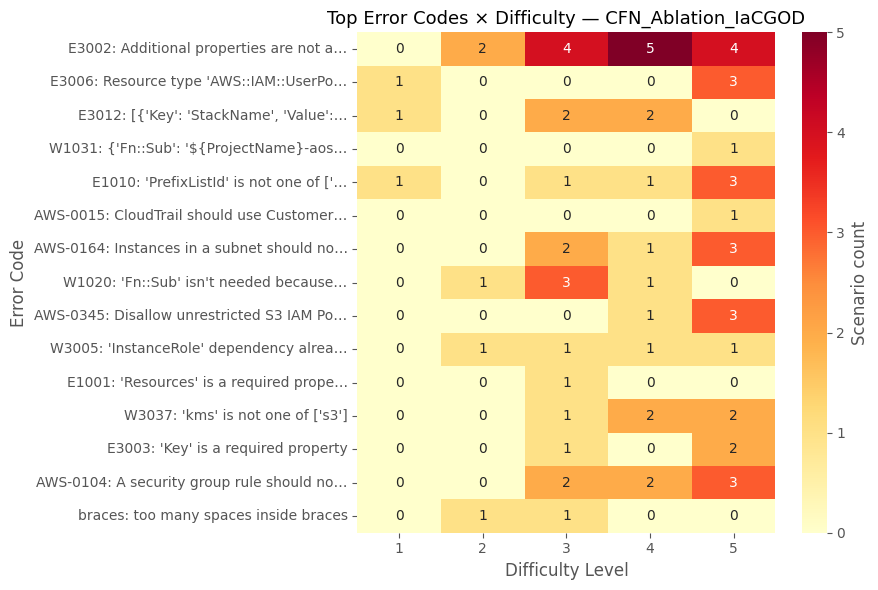

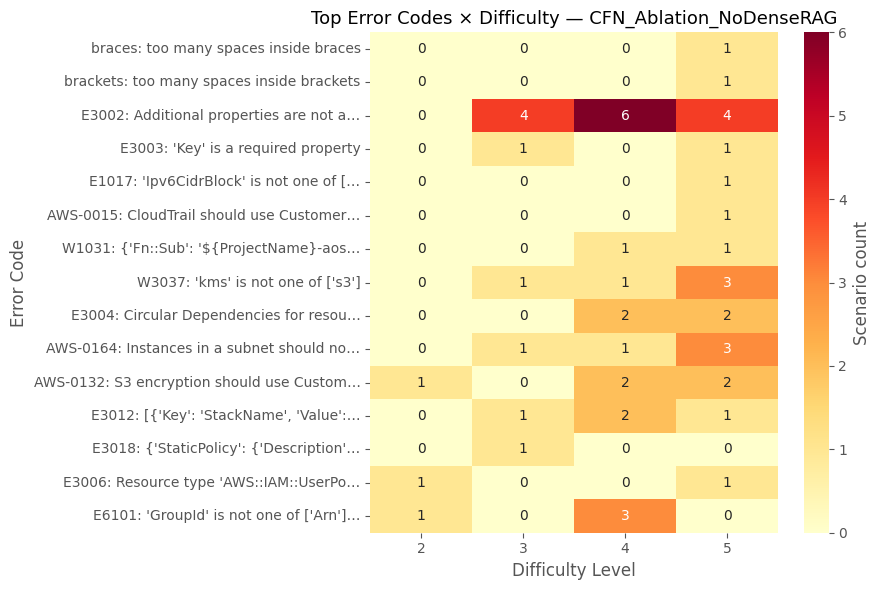

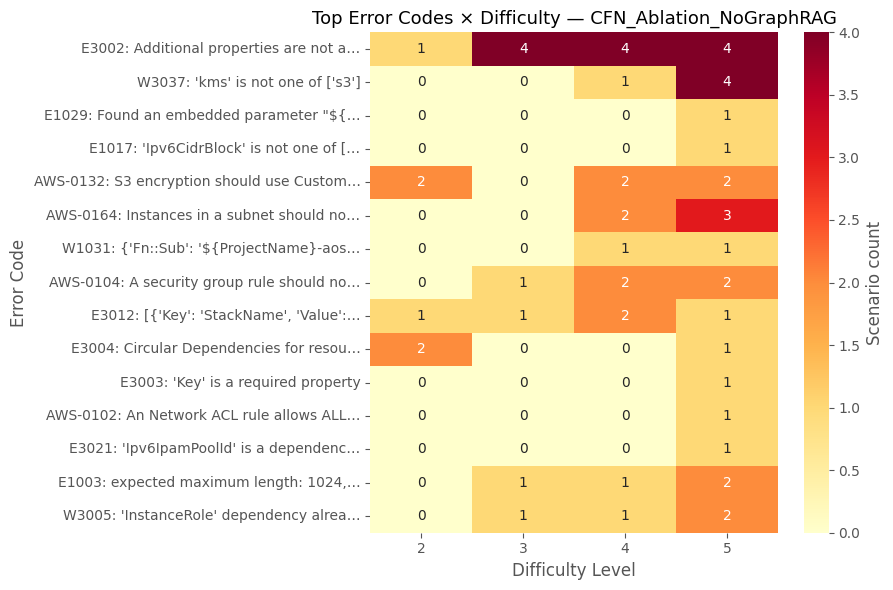

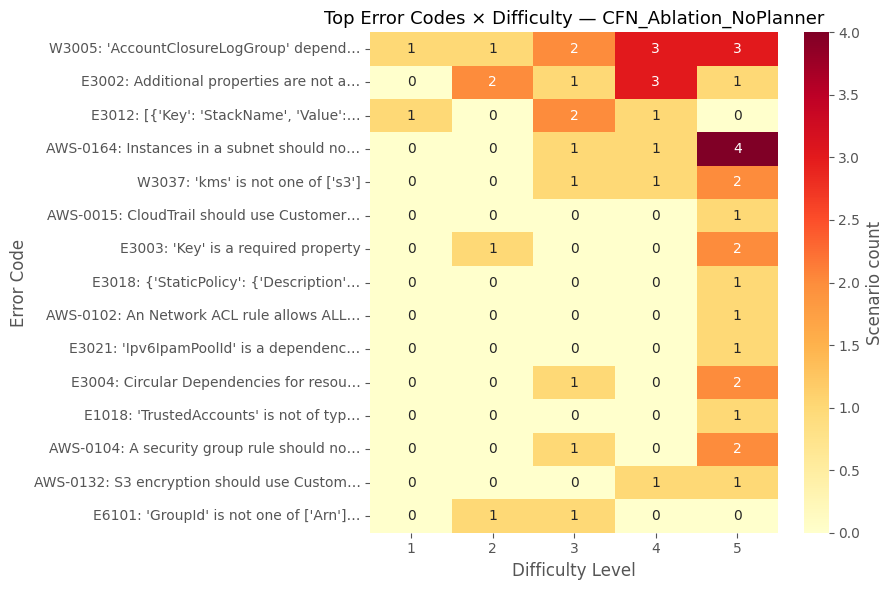

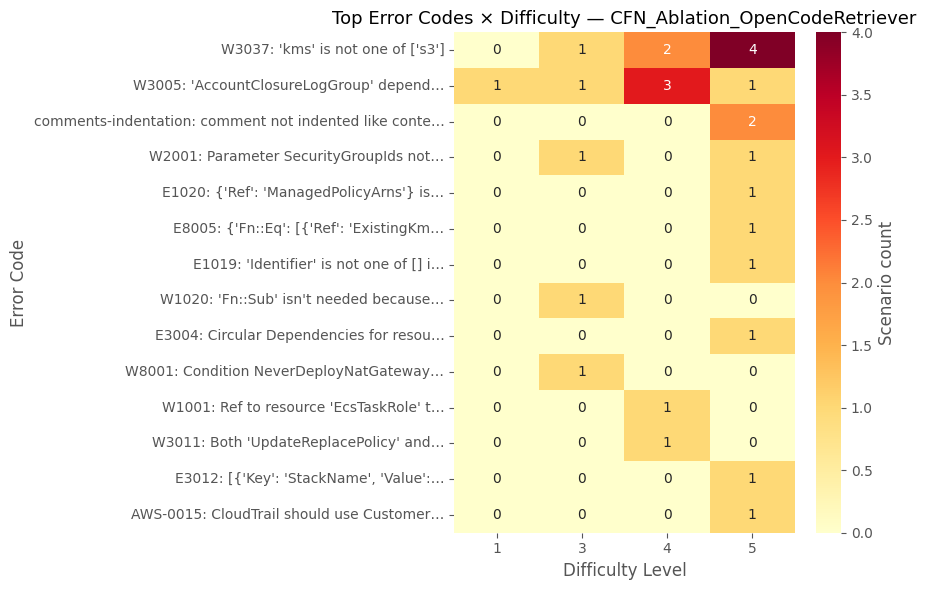

...

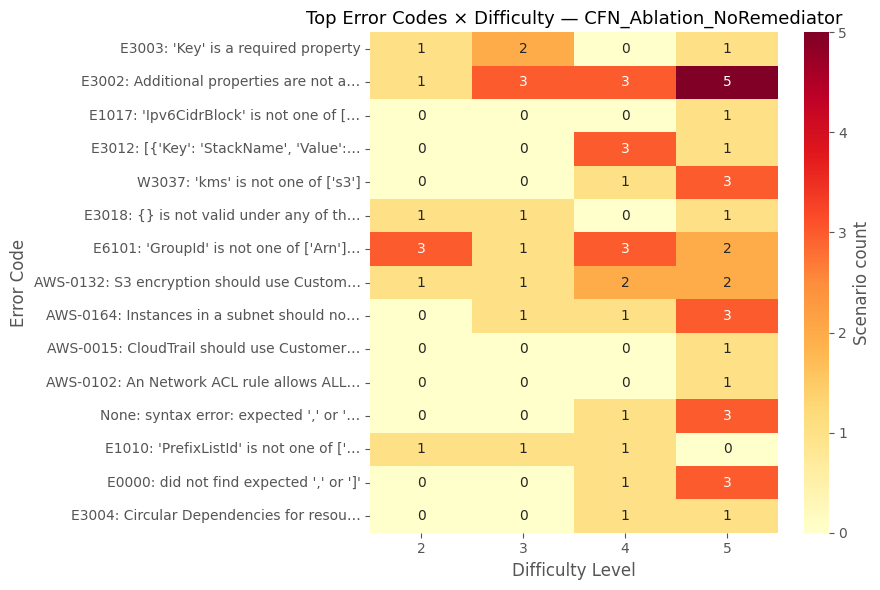

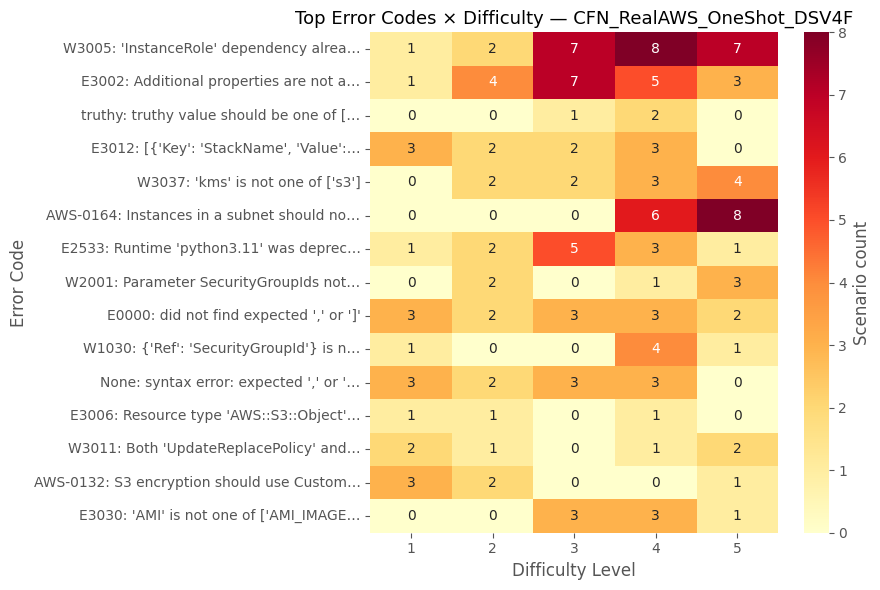

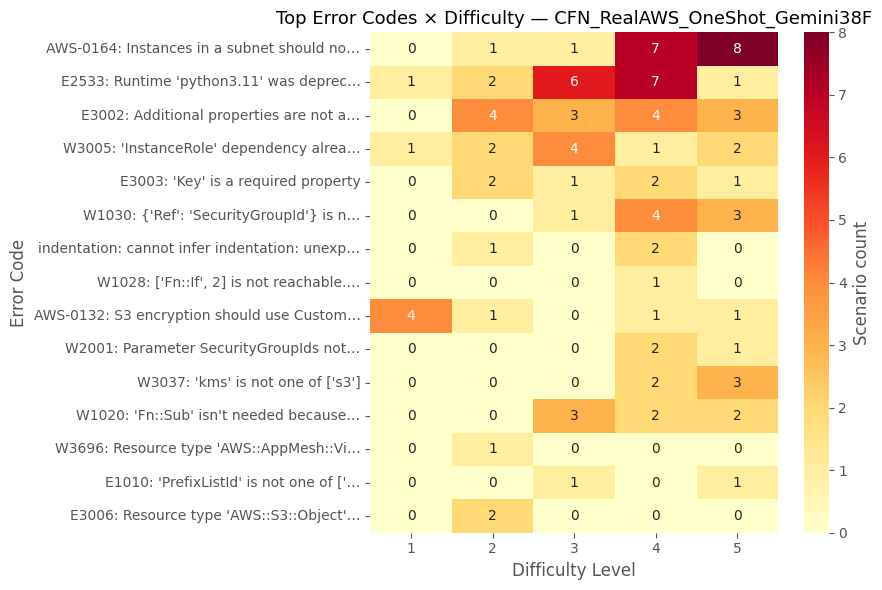

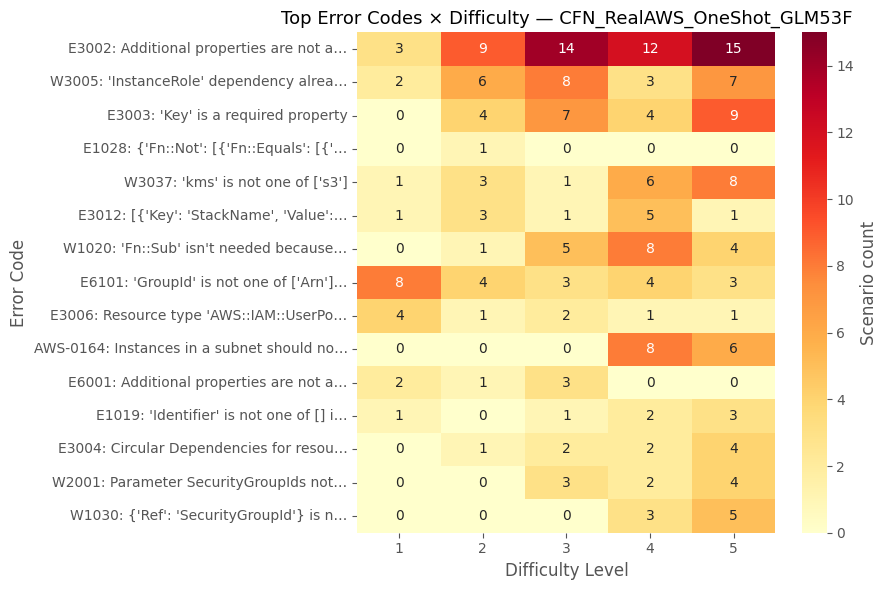

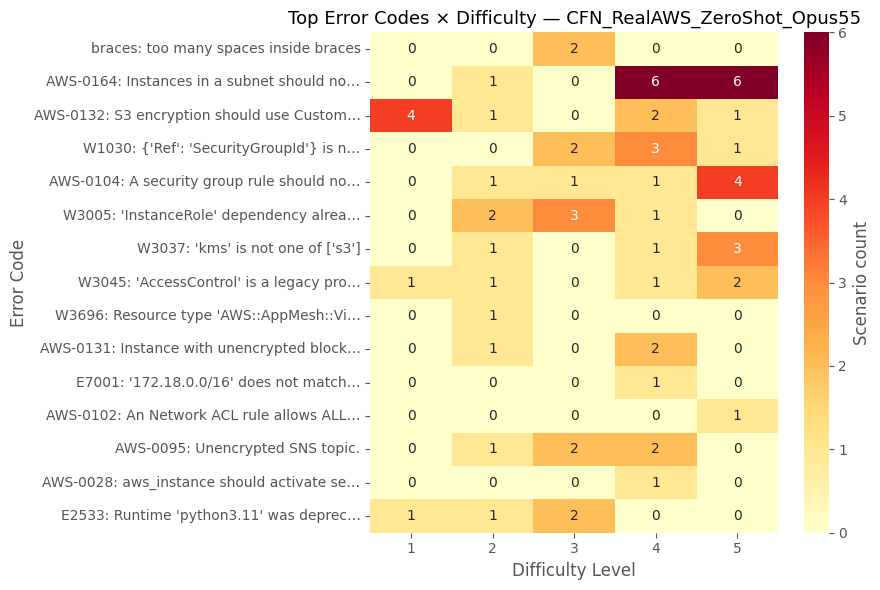

In [29]:
for model_name, df in merged_dataframes.items():
    if "difficulty_level" not in df.columns:
        continue

    combined_counter = Counter()
    for stage in STAGE_CONFIG:
        if stage["all_col"] in df.columns:
            combined_counter.update(top_codes_from_column(df, stage["all_col"]))
    if not combined_counter:
        continue

    top_codes = [c for c, _ in combined_counter.most_common(15)]

    heat_rows = []
    for _, row in df.iterrows():
        diff = row.get("difficulty_level")
        if pd.isna(diff):
            continue
        codes_here = set()
        for stage in STAGE_CONFIG:
            codes_here.update(extract_error_codes(row.get(stage["all_col"])))
        for c in codes_here & set(top_codes):
            heat_rows.append({"Difficulty": diff, "Code": c})

    if not heat_rows:
        continue

    heat_df = pd.DataFrame(heat_rows)
    pivot = pd.crosstab(heat_df["Code"], heat_df["Difficulty"]).reindex(top_codes)
    pivot.index = [describe_code(c, width=32) for c in pivot.index]

    plt.figure(figsize=(9, 6))
    sns.heatmap(pivot, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={"label": "Scenario count"})
    plt.title(f"Top Error Codes × Difficulty — {model_name}", fontsize=13)
    plt.xlabel("Difficulty Level")
    plt.ylabel("Error Code")
    plt.tight_layout()
    plt.show()

## Memory & Remediation Analysis (optional — requires local IaCGOD run logs)

In [30]:
import re
import json as _json
from pathlib import Path

RUNS_ROOT = Path("../runs")
_RUN_ID_RE = re.compile(r"^\d{8}_\d{6}_[0-9a-f]{6,}$")

def build_run_index(runs_root: Path) -> dict:
    idx = {}
    if not runs_root.exists():
        return idx
    for entry in runs_root.iterdir():
        if not entry.is_dir():
            continue
        if _RUN_ID_RE.match(entry.name):
            idx[entry.name] = entry
            continue
        try:
            for sub in entry.iterdir():
                if sub.is_dir() and _RUN_ID_RE.match(sub.name):
                    idx[sub.name] = sub
        except (PermissionError, OSError):
            continue
    return idx

RUN_INDEX = build_run_index(RUNS_ROOT)
print(f"📁 Indexed {len(RUN_INDEX)} run directories under {RUNS_ROOT.resolve()}")

RUN_COVERAGE = {}
for model_name, df in merged_dataframes.items():
    if "run_id" not in df.columns:
        continue
    located = df["run_id"].isin(RUN_INDEX.keys())
    RUN_COVERAGE[model_name] = located
    print(f"  {model_name}: {located.sum()}/{len(df)} scenarios have a locatable run log "
          f"({located.sum()/len(df):.0%}).")

if not RUN_INDEX:
    print("⚠️ RUNS_ROOT not found or empty -- skip the rest of this section "
          "(memory/remediation analysis needs the sibling IaCGOD run logs on disk).")

📁 Indexed 10993 run directories under /Users/iksena/Documents/research/IaCGOD/runs
  CFN_Ablation_IaCGOD: 50/50 scenarios have a locatable run log (100%).
  CFN_Ablation_NoDenseRAG: 50/50 scenarios have a locatable run log (100%).
  CFN_Ablation_NoGraphRAG: 50/50 scenarios have a locatable run log (100%).
  CFN_Ablation_NoPlanner: 50/50 scenarios have a locatable run log (100%).
  CFN_Ablation_OpenCodeRetriever: 50/50 scenarios have a locatable run log (100%).
  CFN_Ablation_TrivyAllSeverities: 50/50 scenarios have a locatable run log (100%).
  CFN_DPIaCEval_o3mini_DeployOnly: 153/153 scenarios have a locatable run log (100%).
  CFN_RealAWS_DSV4F: 250/250 scenarios have a locatable run log (100%).
  CFN_RealAWS_DSV4F_DeployOnly_L345: 134/134 scenarios have a locatable run log (100%).
  CFN_RealAWS_GLM53F: 250/250 scenarios have a locatable run log (100%).
  CFN_RealAWS_IaCGen_GLM53F: 0/250 scenarios have a locatable run log (0%).
  CFN_RealAWS_Gemini36F_L345: 137/137 scenarios have a l


CFN_Ablation_IaCGOD  (analyzed 50 run logs)
  3 run(s) had an error code disappear then reappear in a later iteration.
  1 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('E3003', 1), ('AWS-0015', 1), ('E3002', 1), ('E3530', 1)]
  Most-persistent codes: [('comments-indentation', 1)]
  Avg fix-objectives issued per remediation turn: 4.9 (114 remediation turns total across these runs).



CFN_Ablation_NoDenseRAG  (analyzed 50 run logs)
  2 run(s) had an error code disappear then reappear in a later iteration.
  2 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0015', 1), ('E3002', 1), ('E1017', 1)]
  Most-persistent codes: [('W3037', 1), ('W1020', 1), ('W3005', 1)]
  Avg fix-objectives issued per remediation turn: 6.8 (90 remediation turns total across these runs).



CFN_Ablation_NoGraphRAG  (analyzed 50 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  2 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('E1017', 1)]
  Most-persistent codes: [('W1030', 1), ('W3037', 1)]
  Avg fix-objectives issued per remediation turn: 7.4 (59 remediation turns total across these runs).



CFN_Ablation_NoPlanner  (analyzed 50 run logs)
  3 run(s) had an error code disappear then reappear in a later iteration.
  3 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('E3002', 2), ('W3005', 1), ('AWS-0015', 1)]
  Most-persistent codes: [('W3005', 2), ('W3037', 1)]
  Avg fix-objectives issued per remediation turn: 6.0 (68 remediation turns total across these runs).

CFN_Ablation_OpenCodeRetriever  (analyzed 50 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  7 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0015', 1), ('AWS-0016', 1)]
  Most-persistent codes: [('W3037', 4), ('W2001', 2), ('W3005', 2), ('W1001', 1), ('comments-indentation', 1)]
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



CFN_Ablation_TrivyAllSeverities  (analyzed 50 run logs)
  2 run(s) had an error code disappear then reappear in a later iteration.
  1 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0015', 1), ('E3002', 1), ('W3005', 1)]
  Most-persistent codes: [('a-z', 1), ('W1031', 1)]
  Avg fix-objectives issued per remediation turn: 7.3 (110 remediation turns total across these runs).



CFN_DPIaCEval_o3mini_DeployOnly  (analyzed 153 run logs)
  13 run(s) had an error code disappear then reappear in a later iteration.
  12 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('W3005', 4), ('brackets', 3), ('None', 3), ('E0000', 3), ('W3037', 2), ('indentation', 2), ('braces', 2), ('E3691', 1)]
  Most-persistent codes: [('W1020', 4), ('W3687', 3), ('W3005', 3), ('comments-indentation', 1), ('W3697', 1), ('W3011', 1), ('W3037', 1)]
  Avg fix-objectives issued per remediation turn: 0.0 (493 remediation turns total across these runs).



CFN_RealAWS_DSV4F  (analyzed 250 run logs)
  14 run(s) had an error code disappear then reappear in a later iteration.
  7 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('W3005', 4), ('E3002', 2), ('E3004', 2), ('E3006', 1), ('AWS-0031', 1), ('W1020', 1), ('None', 1), ('E0000', 1)]
  Most-persistent codes: [('W3011', 3), ('W1020', 2), ('W3696', 1), ('W3010', 1), ('W3037', 1)]
  Avg fix-objectives issued per remediation turn: 2.7 (764 remediation turns total across these runs).



CFN_RealAWS_DSV4F_DeployOnly_L345  (analyzed 134 run logs)
  16 run(s) had an error code disappear then reappear in a later iteration.
  6 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('W3005', 5), ('None', 4), ('E0000', 4), ('E3002', 4), ('E3012', 3), ('E3003', 2), ('W1030', 2), ('W3011', 1)]
  Most-persistent codes: [('W3037', 2), ('W3011', 2), ('W1020', 1), ('W3010', 1)]
  Avg fix-objectives issued per remediation turn: 3.5 (449 remediation turns total across these runs).



CFN_RealAWS_GLM53F  (analyzed 250 run logs)
  20 run(s) had an error code disappear then reappear in a later iteration.
  13 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('W3005', 6), ('E3002', 5), ('E3004', 4), ('E3003', 3), ('None', 2), ('E0000', 2), ('E3018', 2), ('E3510', 2)]
  Most-persistent codes: [('W3005', 3), ('W3037', 3), ('E3006', 2), ('W1020', 2), ('W1030', 1), ('W3010', 1), ('comments-indentation', 1)]
  Avg fix-objectives issued per remediation turn: 3.0 (878 remediation turns total across these runs).



CFN_RealAWS_Gemini36F_L345  (analyzed 137 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  8 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('W2001', 1)]
  Most-persistent codes: [('W3037', 2), ('W1020', 2), ('W1030', 2), ('comments-indentation', 1), ('W3687', 1)]
  Avg fix-objectives issued per remediation turn: 2.0 (215 remediation turns total across these runs).



CFN_RealAWS_Gemini38F  (analyzed 250 run logs)
  4 run(s) had an error code disappear then reappear in a later iteration.
  14 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0104', 2), ('E3002', 1), ('E3003', 1), ('W2001', 1)]
  Most-persistent codes: [('W1020', 4), ('W3037', 2), ('W1030', 2), ('W3687', 2), ('W3696', 1), ('W3010', 1), ('W3005', 1), ('W8001', 1)]
  Avg fix-objectives issued per remediation turn: 2.6 (275 remediation turns total across these runs).



CFN_RealAWS_OpenCode_DSV4F  (analyzed 250 run logs)
  7 run(s) had an error code disappear then reappear in a later iteration.
  23 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('W3037', 2), ('E3002', 1), ('E3012', 1), ('E1010', 1), ('indentation', 1), ('E1019', 1)]
  Most-persistent codes: [('W3037', 6), ('W1020', 5), ('W3005', 4), ('comments-indentation', 3), ('E3006', 2), ('W3045', 2), ('W3696', 1), ('W3011', 1)]
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



CFN_RealAWS_Opus55  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  4 run(s) had an error code present in EVERY iteration (never cleared).
  Most-persistent codes: [('W1030', 2), ('W3005', 1), ('W1028', 1), ('W8001', 1)]
  Avg fix-objectives issued per remediation turn: 5.7 (192 remediation turns total across these runs).

CFN_Ablation_NoQueryRewrite  (analyzed 50 run logs)
  1 run(s) had an error code disappear then reappear in a later iteration.
  4 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0015', 1), ('E3002', 1)]
  Most-persistent codes: [('W3005', 2), ('comments', 1), ('comments-indentation', 1)]
  Avg fix-objectives issued per remediation turn: 7.1 (94 remediation turns total across these runs).



CFN_Ablation_NoRemediator  (analyzed 50 run logs)
  2 run(s) had an error code disappear then reappear in a later iteration.
  3 run(s) had an error code present in EVERY iteration (never cleared).
  Most-recurring codes: [('AWS-0015', 1), ('E3002', 1), ('E1017', 1), ('None', 1), ('E0000', 1)]
  Most-persistent codes: [('W8001', 1), ('W3037', 1), ('comments-indentation', 1)]
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).

CFN_RealAWS_OneShot_DSV4F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



CFN_RealAWS_OneShot_Gemini38F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).

CFN_RealAWS_OneShot_GLM53F  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).



CFN_RealAWS_ZeroShot_Opus55  (analyzed 250 run logs)
  0 run(s) had an error code disappear then reappear in a later iteration.
  0 run(s) had an error code present in EVERY iteration (never cleared).
  Avg fix-objectives issued per remediation turn: nan (0 remediation turns total across these runs).





None

In [31]:
FIX_OBJ_RE = re.compile(r"^\s*\d+\.\s+\*\*", re.MULTILINE)
ASSISTANT_TURN_RE = re.compile(r"^\[assistant\]\s*$", re.MULTILINE)

def load_iteration_codes(run_dir: Path) -> dict:
    out = {}
    for f in sorted(run_dir.glob("iteration_*.json")):
        try:
            d = _json.loads(f.read_text())
        except (ValueError, OSError):
            continue
        codes = set()
        for vr in d.get("validation_results", []) or []:
            for err in vr.get("errors", []) or []:
                entries = extract_error_entries(err)
                codes.update(c for c, _ in entries)
                record_messages(entries)
        out[d.get("iteration", len(out) + 1)] = codes
    return out

def count_remediator_turns_and_fix_objectives(run_dir: Path) -> tuple:
    hist = run_dir / "remediator_history.txt"
    if not hist.exists():
        return 0, 0
    text = hist.read_text(errors="ignore")
    return len(ASSISTANT_TURN_RE.findall(text)), len(FIX_OBJ_RE.findall(text))

MEMORY_SAMPLE_LIMIT = 300
def _plot_remediation_memory(selected_models):
    dfs = {m: merged_dataframes[m] for m in selected_models}

    memory_summaries = {}
    for model_name, df in dfs.items():
        if model_name not in RUN_COVERAGE:
            continue
        located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
        if located_df.empty:
            continue

        recur_counter, persist_counter = Counter(), Counter()
        fix_obj_counts, turn_counts = [], []
        n_recurring_runs, n_persistent_runs = 0, 0

        for _, row in located_df.iterrows():
            run_dir = RUN_INDEX[row["run_id"]]
            itcodes = load_iteration_codes(run_dir)
            iters_sorted = sorted(itcodes.keys())
            if len(iters_sorted) < 2:
                occurrences = {}
            else:
                occurrences = {}
                for i in iters_sorted:
                    for c in itcodes[i]:
                        occurrences.setdefault(c, []).append(i)

            run_has_recur, run_has_persist = False, False
            for c, occ in occurrences.items():
                if len(occ) > 1 and (occ[-1] - occ[0]) > (len(occ) - 1):
                    recur_counter[c] += 1
                    run_has_recur = True
                elif len(occ) == len(iters_sorted) and len(iters_sorted) > 1:
                    persist_counter[c] += 1
                    run_has_persist = True
            n_recurring_runs += run_has_recur
            n_persistent_runs += run_has_persist

            n_turns, n_fix = count_remediator_turns_and_fix_objectives(run_dir)
            turn_counts.append(n_turns)
            fix_obj_counts.append(n_fix)

        memory_summaries[model_name] = {
            "n_runs": len(located_df),
            "recur_counter": recur_counter,
            "persist_counter": persist_counter,
            "n_recurring_runs": n_recurring_runs,
            "n_persistent_runs": n_persistent_runs,
            "turn_counts": turn_counts,
            "fix_obj_counts": fix_obj_counts,
        }

        print(f"\n{'='*90}\n{model_name}  (analyzed {len(located_df)} run logs)")
        print(f"  {n_recurring_runs} run(s) had an error code disappear then reappear in a later iteration.")
        print(f"  {n_persistent_runs} run(s) had an error code present in EVERY iteration (never cleared).")
        if recur_counter:
            print(f"  Most-recurring codes: {recur_counter.most_common(8)}")
        if persist_counter:
            print(f"  Most-persistent codes: {persist_counter.most_common(8)}")

        mean_items_per_turn = (sum(fix_obj_counts) / sum(turn_counts)) if sum(turn_counts) else float("nan")
        print(f"  Avg fix-objectives issued per remediation turn: {mean_items_per_turn:.1f} "
              f"({sum(turn_counts)} remediation turns total across these runs).")

    if memory_summaries:
        fig, axes = plt.subplots(1, len(memory_summaries), figsize=(7 * len(memory_summaries), 5), squeeze=False)
        for ax, (model_name, summ) in zip(axes[0], memory_summaries.items()):
            combo = Counter(summ["recur_counter"]) + Counter(summ["persist_counter"])
            top = pd.DataFrame(combo.most_common(10), columns=["Code", "Count"])
            if top.empty:
                ax.text(0.5, 0.5, "No recurring/persistent codes", ha="center", va="center")
                ax.set_axis_off()
                continue
            top["Label"] = top["Code"].apply(describe_code)
            sns.barplot(data=top, y="Label", x="Count", color="crimson", ax=ax)
            ax.set_title(f"{model_name}\n(recurring + persistent error codes)", fontsize=11)
            ax.set_xlabel("Run count")
            ax.set_ylabel("")
        plt.tight_layout()
        plt.show()

_out_remediation_memory = widgets.interactive_output(_plot_remediation_memory, {'selected_models': model_selector})
display(_out_remediation_memory)

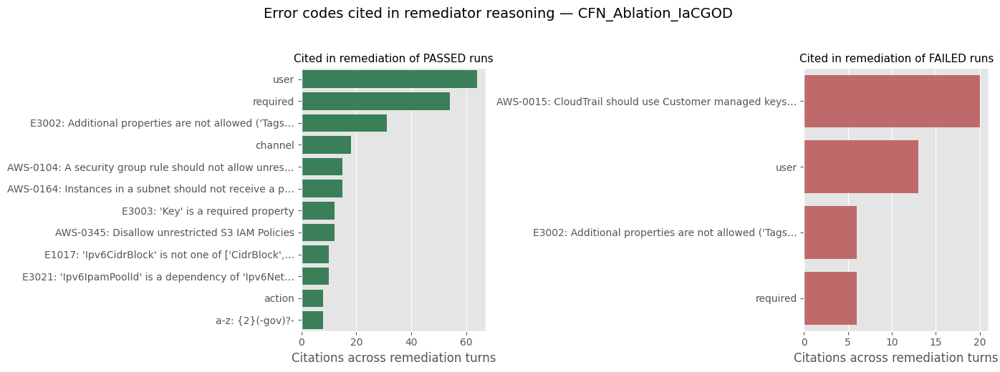


CFN_Ablation_IaCGOD — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 17), ('self-contained', 14), ('dependson', 11), ('security group', 11), ('intrinsic function', 9), ('hardcoded', 8), ('customer managed key', 6), ('circular dependency', 4)]
  Failed runs: [('circular dependency', 1), ('missing resource', 1), ('encryption', 1), ('customer managed key', 1), ('security group', 1), ('dependson', 1), ('intrinsic function', 1)]


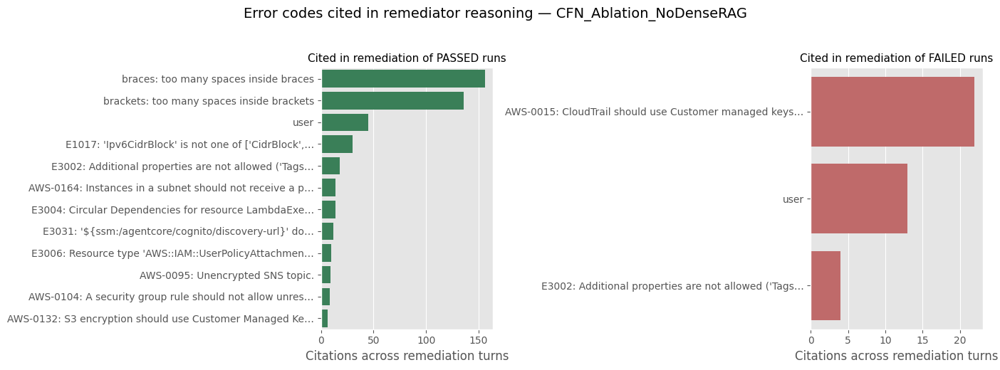


CFN_Ablation_NoDenseRAG — root-cause keyword themes in remediator reasoning:
  Passed runs: [('dependson', 16), ('encryption', 15), ('hardcoded', 14), ('self-contained', 14), ('security group', 10), ('customer managed key', 8), ('circular dependency', 6), ('trust policy', 4)]
  Failed runs: [('hardcoded', 1), ('self-contained', 1), ('encryption', 1), ('customer managed key', 1), ('public access', 1), ('security group', 1), ('intrinsic function', 1)]


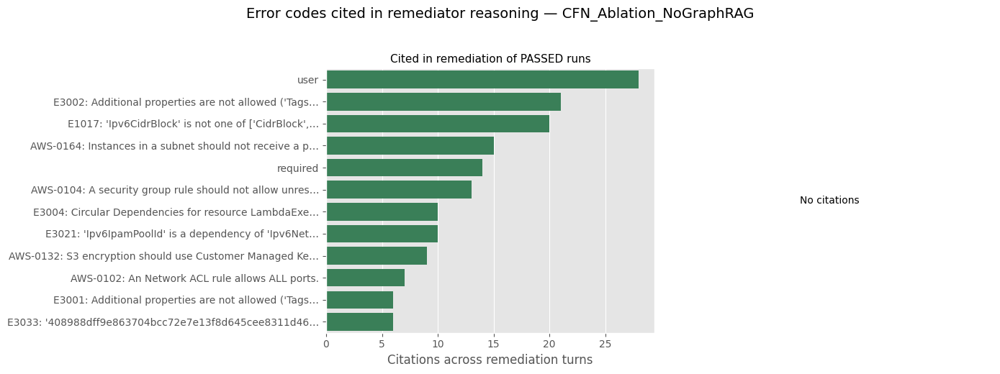


CFN_Ablation_NoGraphRAG — root-cause keyword themes in remediator reasoning:
  Passed runs: [('hardcoded', 17), ('self-contained', 15), ('dependson', 13), ('encryption', 13), ('security group', 7), ('customer managed key', 6), ('intrinsic function', 6), ('circular dependency', 5)]
  Failed runs: []


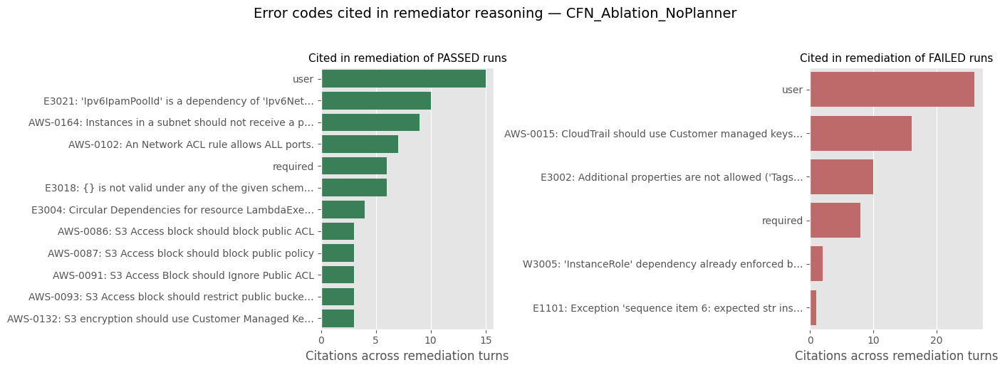


CFN_Ablation_NoPlanner — root-cause keyword themes in remediator reasoning:
  Passed runs: [('self-contained', 11), ('encryption', 7), ('dependson', 7), ('hardcoded', 5), ('customer managed key', 4), ('security group', 4), ('circular dependency', 3), ('type mismatch', 1)]
  Failed runs: [('encryption', 2), ('dependson', 2), ('intrinsic function', 2), ('hardcoded', 1), ('customer managed key', 1), ('security group', 1)]


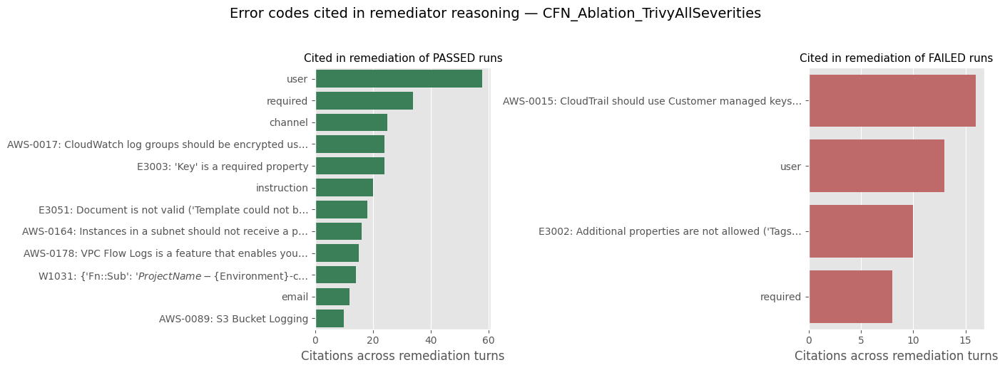


CFN_Ablation_TrivyAllSeverities — root-cause keyword themes in remediator reasoning:
  Passed runs: [('hardcoded', 32), ('encryption', 29), ('dependson', 25), ('self-contained', 20), ('customer managed key', 14), ('security group', 9), ('circular dependency', 8), ('deprecated', 6)]
  Failed runs: [('deprecated', 1), ('hardcoded', 1), ('self-contained', 1), ('encryption', 1), ('customer managed key', 1), ('security group', 1), ('dependson', 1), ('intrinsic function', 1)]


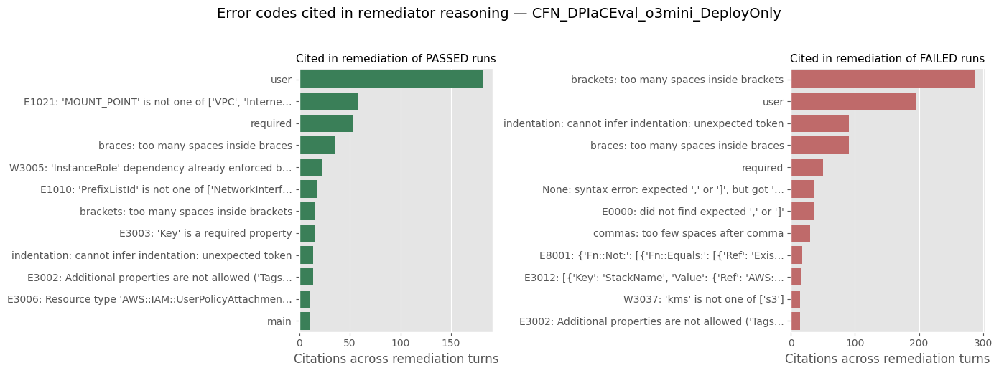


CFN_DPIaCEval_o3mini_DeployOnly — root-cause keyword themes in remediator reasoning:
  Passed runs: [('intrinsic function', 45), ('dependson', 36), ('encryption', 34), ('security group', 24), ('circular dependency', 9), ('deprecated', 8), ('public access', 7), ('self-contained', 5)]
  Failed runs: [('dependson', 12), ('encryption', 11), ('intrinsic function', 11), ('security group', 9), ('iam permission', 5), ('hardcoded', 3), ('deprecated', 3), ('public access', 3)]


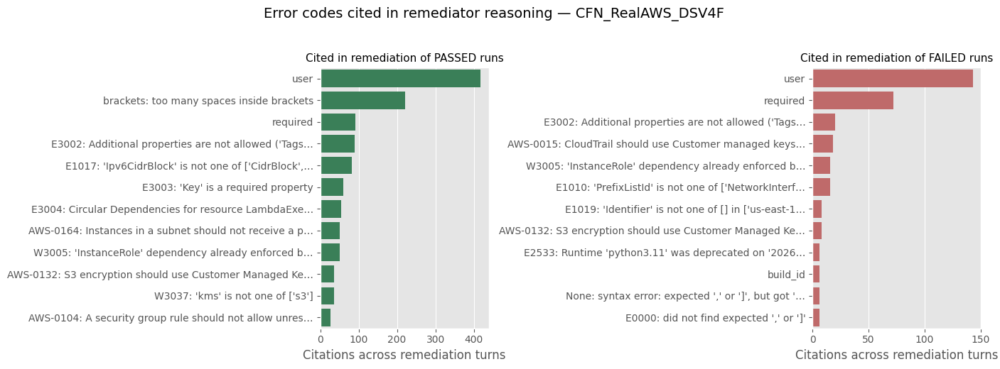


CFN_RealAWS_DSV4F — root-cause keyword themes in remediator reasoning:
  Passed runs: [('dependson', 70), ('encryption', 64), ('intrinsic function', 47), ('security group', 26), ('circular dependency', 24), ('customer managed key', 23), ('trust policy', 20), ('self-contained', 16)]
  Failed runs: [('dependson', 10), ('encryption', 8), ('intrinsic function', 7), ('self-contained', 4), ('deprecated', 4), ('trust policy', 4), ('security group', 3), ('public access', 3)]


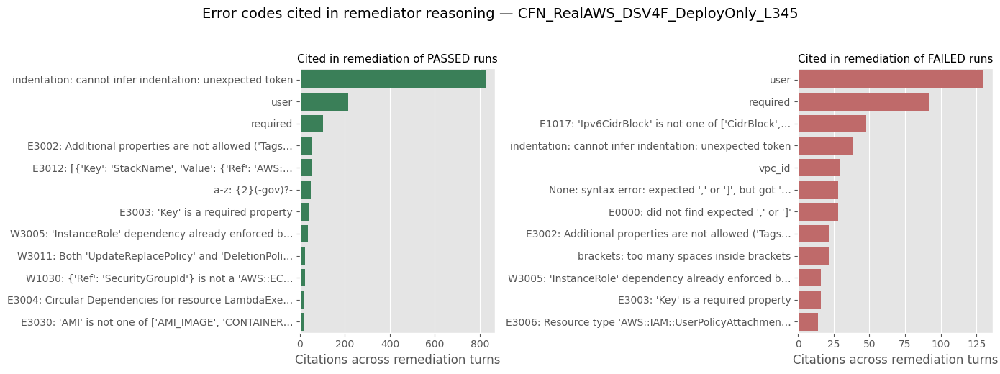


CFN_RealAWS_DSV4F_DeployOnly_L345 — root-cause keyword themes in remediator reasoning:
  Passed runs: [('dependson', 38), ('encryption', 32), ('intrinsic function', 23), ('hardcoded', 20), ('circular dependency', 17), ('security group', 17), ('trust policy', 13), ('self-contained', 12)]
  Failed runs: [('encryption', 9), ('dependson', 9), ('intrinsic function', 5), ('hardcoded', 4), ('security group', 4), ('self-contained', 3), ('trust policy', 3), ('iam permission', 2)]


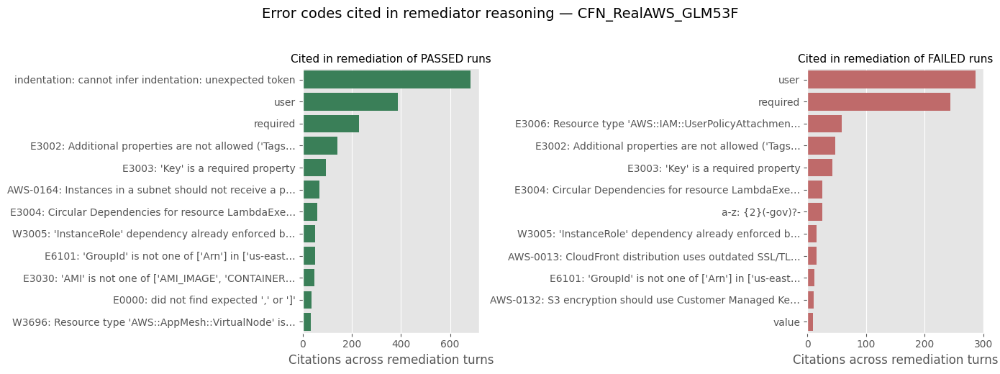


CFN_RealAWS_GLM53F — root-cause keyword themes in remediator reasoning:
  Passed runs: [('dependson', 85), ('encryption', 60), ('hardcoded', 53), ('self-contained', 43), ('security group', 30), ('trust policy', 26), ('intrinsic function', 24), ('circular dependency', 24)]
  Failed runs: [('dependson', 15), ('encryption', 14), ('hardcoded', 12), ('self-contained', 11), ('circular dependency', 8), ('intrinsic function', 6), ('iam permission', 5), ('customer managed key', 5)]


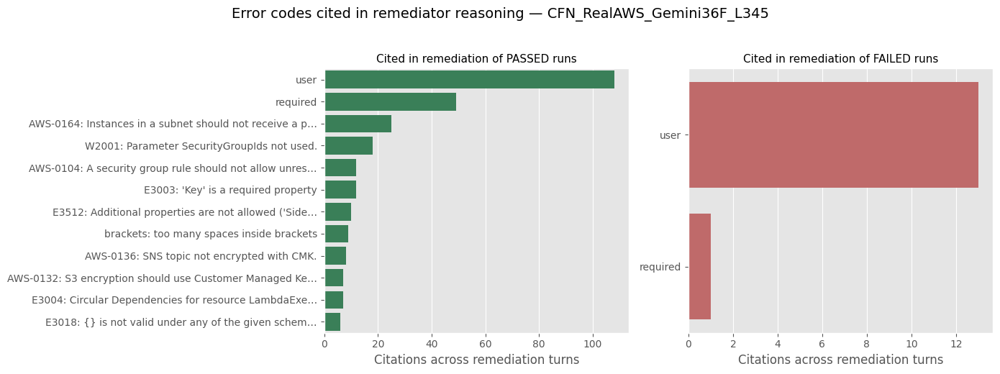


CFN_RealAWS_Gemini36F_L345 — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 31), ('dependson', 17), ('security group', 16), ('customer managed key', 12), ('self-contained', 8), ('intrinsic function', 7), ('trust policy', 5), ('hardcoded', 4)]
  Failed runs: [('deprecated', 1), ('hardcoded', 1), ('iam permission', 1), ('intrinsic function', 1)]


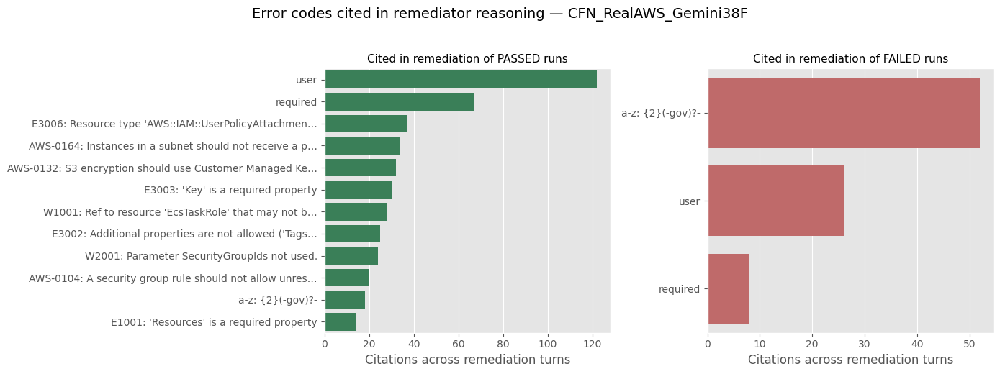


CFN_RealAWS_Gemini38F — root-cause keyword themes in remediator reasoning:
  Passed runs: [('encryption', 45), ('dependson', 32), ('customer managed key', 30), ('security group', 22), ('intrinsic function', 13), ('iam permission', 10), ('self-contained', 7), ('deprecated', 5)]
  Failed runs: [('intrinsic function', 2), ('deprecated', 1), ('hardcoded', 1), ('security group', 1), ('dependson', 1)]


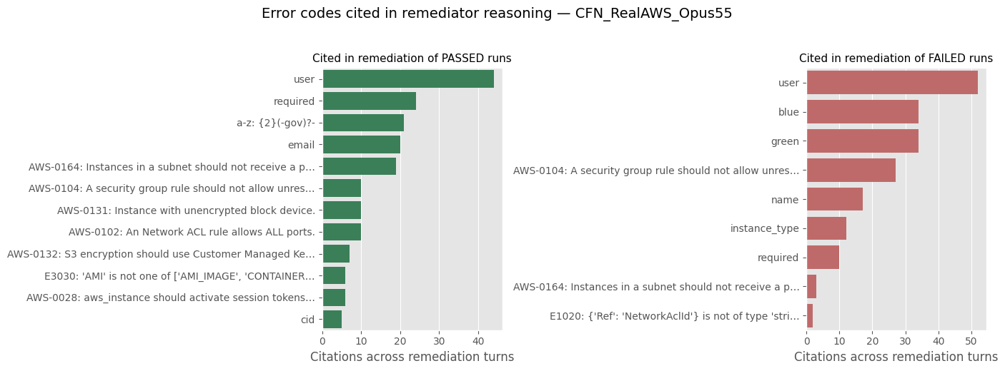


CFN_RealAWS_Opus55 — root-cause keyword themes in remediator reasoning:
  Passed runs: [('dependson', 69), ('encryption', 44), ('hardcoded', 32), ('customer managed key', 30), ('circular dependency', 21), ('security group', 19), ('public access', 17), ('trust policy', 8)]
  Failed runs: [('hardcoded', 4), ('encryption', 4), ('dependson', 4), ('security group', 3), ('public access', 2), ('self-contained', 1), ('deprecated', 1), ('intrinsic function', 1)]


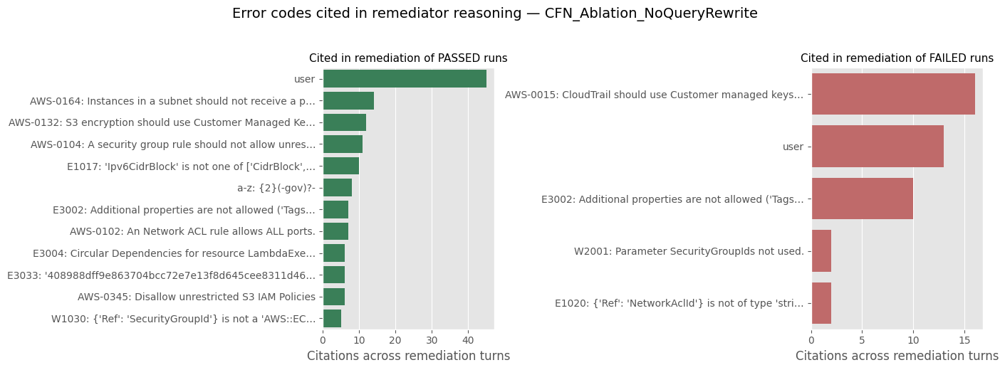


CFN_Ablation_NoQueryRewrite — root-cause keyword themes in remediator reasoning:
  Passed runs: [('dependson', 19), ('encryption', 17), ('self-contained', 16), ('hardcoded', 15), ('customer managed key', 10), ('security group', 8), ('circular dependency', 4), ('intrinsic function', 3)]
  Failed runs: [('circular dependency', 1), ('encryption', 1), ('customer managed key', 1), ('security group', 1), ('dependson', 1), ('intrinsic function', 1)]


In [32]:
ROOT_CAUSE_KEYWORDS = [
    "circular dependency", "deprecated", "hardcoded", "self-contained", "self-containment",
    "unused parameter", "missing resource", "iam permission", "trust policy",
    "encryption", "customer managed key", "public access", "security group",
    "dependson", "intrinsic function", "type mismatch", "not authorized",
]

def cited_codes_and_keywords(run_dir: Path) -> tuple:
    hist = run_dir / "remediator_history.txt"
    if not hist.exists():
        return Counter(), Counter()
    text = hist.read_text(errors="ignore")
    assistant_blocks = re.split(r"^\[assistant\]\s*$", text, flags=re.MULTILINE)[1:]
    assistant_text = "\n".join(assistant_blocks)
    codes = Counter(c for c in CODE_RE.findall(assistant_text) if GOOD_CODE_RE.match(c))
    low = assistant_text.lower()
    kws = Counter(kw for kw in ROOT_CAUSE_KEYWORDS if kw in low)
    return codes, kws

for model_name, df in merged_dataframes.items():
    if model_name not in RUN_COVERAGE or "final_validation_passed" not in df.columns:
        continue
    located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
    if located_df.empty:
        continue

    cited_passed, cited_failed = Counter(), Counter()
    kw_passed, kw_failed = Counter(), Counter()
    for _, row in located_df.iterrows():
        run_dir = RUN_INDEX[row["run_id"]]
        codes, kws = cited_codes_and_keywords(run_dir)
        bucket_c = cited_passed if row["final_validation_passed"] else cited_failed
        bucket_k = kw_passed if row["final_validation_passed"] else kw_failed
        bucket_c.update(codes)
        bucket_k.update(kws)

    if not (cited_passed or cited_failed):
        continue

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, counter, title, color in [
        (axes[0], cited_passed, "Cited in remediation of PASSED runs", "seagreen"),
        (axes[1], cited_failed, "Cited in remediation of FAILED runs", "indianred"),
    ]:
        top = pd.DataFrame(counter.most_common(12), columns=["Code", "Count"])
        if top.empty:
            ax.text(0.5, 0.5, "No citations", ha="center", va="center")
            ax.set_axis_off()
            continue
        top["Label"] = top["Code"].apply(describe_code)
        sns.barplot(data=top, y="Label", x="Count", color=color, ax=ax)
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("Citations across remediation turns")
        ax.set_ylabel("")
    fig.suptitle(f"Error codes cited in remediator reasoning — {model_name}", fontsize=14, y=1.03)
    plt.tight_layout()
    plt.show()

    print(f"\n{model_name} — root-cause keyword themes in remediator reasoning:")
    print(f"  Passed runs: {kw_passed.most_common(8)}")
    print(f"  Failed runs: {kw_failed.most_common(8)}")

📊 Security-code lifecycle: 680 (scenario, code) instances across 421 scenarios with security findings.


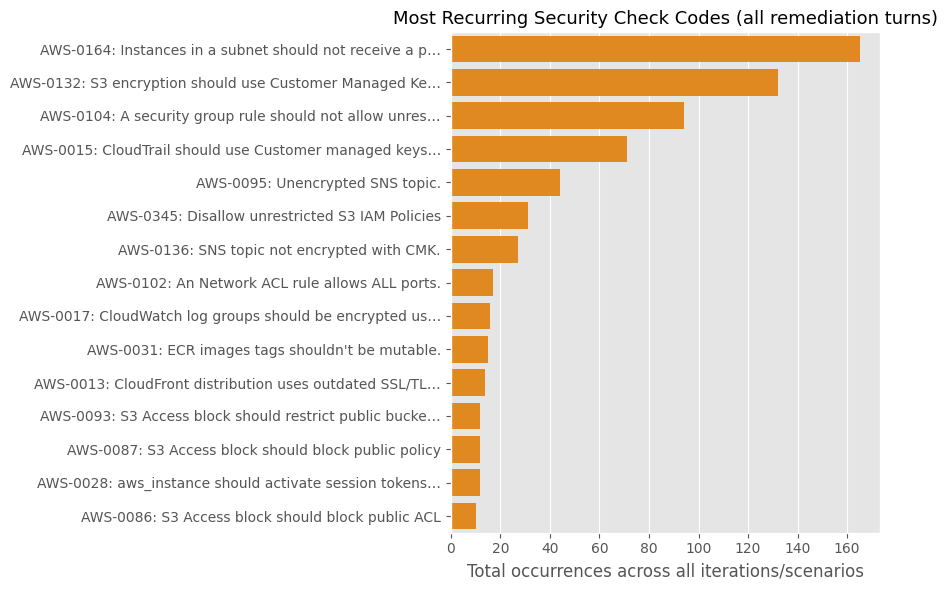

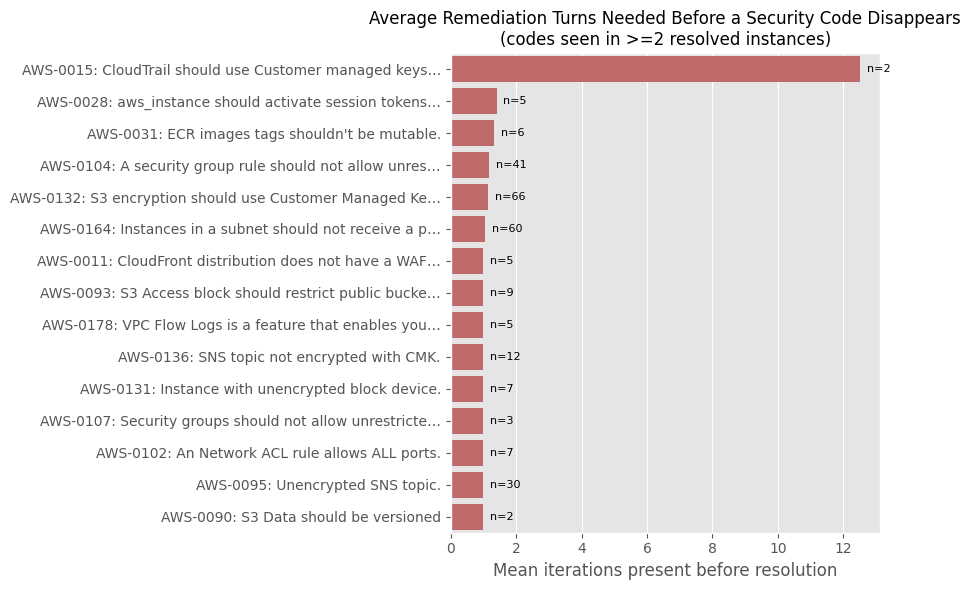


  Overall: 332/680 security-code instances were resolved by the run's own final iteration (348 were still open at the end).
  Median iterations-to-resolve (resolved instances only): 1.0


In [33]:
SECURITY_STAGES = ("trivy", "checkov")

def load_final_report(run_dir: Path) -> dict | None:
    path = run_dir / "final_report.json"
    if not path.exists():
        return None
    try:
        return _json.loads(path.read_text())
    except (ValueError, OSError):
        return None

def security_codes_by_iteration(remediation_history: list) -> dict:
    out = {}
    for entry in remediation_history:
        codes = set()
        for stage_result in entry.get("errors", []) or []:
            if stage_result.get("stage") not in SECURITY_STAGES:
                continue
            for err in stage_result.get("errors", []) or []:
                entries = extract_error_entries(err)
                codes.update(c for c, _ in entries)
                record_messages(entries)
        out[entry["iteration"]] = codes
    return out

def security_code_lifecycle(codes_by_iter: dict) -> list:
    if not codes_by_iter:
        return []
    iters_sorted = sorted(codes_by_iter)
    last_iter = iters_sorted[-1]
    all_codes = set().union(*codes_by_iter.values()) if codes_by_iter else set()
    rows = []
    for code in all_codes:
        present = [i for i in iters_sorted if code in codes_by_iter[i]]
        first_seen, last_seen = min(present), max(present)
        resolved = code not in codes_by_iter[last_iter]
        rows.append({
            "code": code,
            "first_seen_iteration": first_seen,
            "last_seen_iteration": last_seen,
            "resolved_by_end": resolved,
            "iterations_present": (last_seen - first_seen + 1) if resolved else None,
        })
    return rows

security_lifecycle_rows = []
security_occurrence_counter = Counter()

for model_name, df in merged_dataframes.items():
    if model_name not in RUN_COVERAGE:
        continue
    located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
    for _, row in located_df.iterrows():
        run_dir = RUN_INDEX[row["run_id"]]
        report = load_final_report(run_dir)
        if not report:
            continue
        codes_by_iter = security_codes_by_iteration(report.get("remediation_history", []))
        if not codes_by_iter:
            continue
        for it, codes in codes_by_iter.items():
            security_occurrence_counter.update(codes)
        for r in security_code_lifecycle(codes_by_iter):
            r["model"] = model_name
            r["row_number"] = row["row_number"]
            r["run_id"] = row["run_id"]
            security_lifecycle_rows.append(r)

if security_lifecycle_rows:
    sec_life_df = pd.DataFrame(security_lifecycle_rows)
    print(f"📊 Security-code lifecycle: {len(sec_life_df)} (scenario, code) instances "
          f"across {sec_life_df.groupby(['model','row_number']).ngroups} scenarios with security findings.")

    top_occurrence = pd.DataFrame(security_occurrence_counter.most_common(15), columns=["Code", "Occurrences"])
    top_occurrence["Label"] = top_occurrence["Code"].apply(describe_code)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=top_occurrence, y="Label", x="Occurrences", color="darkorange")
    plt.title("Most Recurring Security Check Codes (all remediation turns)", fontsize=13)
    plt.xlabel("Total occurrences across all iterations/scenarios")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    resolved_df = sec_life_df[sec_life_df["resolved_by_end"]]
    if not resolved_df.empty:
        avg_iters = resolved_df.groupby("code")["iterations_present"].agg(["mean", "count"]).reset_index()
        avg_iters = avg_iters[avg_iters["count"] >= 2].sort_values("mean", ascending=False).head(15)
        avg_iters["Label"] = avg_iters["code"].apply(describe_code)

        if not avg_iters.empty:
            plt.figure(figsize=(9, 6))
            ax = sns.barplot(data=avg_iters, y="Label", x="mean", color="indianred")
            for i, (mean, count) in enumerate(zip(avg_iters["mean"], avg_iters["count"])):
                ax.annotate(f"n={count}", (mean, i), va="center", xytext=(5, 0), textcoords="offset points", fontsize=8)
            plt.title("Average Remediation Turns Needed Before a Security Code Disappears\n(codes seen in >=2 resolved instances)", fontsize=12)
            plt.xlabel("Mean iterations present before resolution")
            plt.ylabel("")
            plt.tight_layout()
            plt.show()

        print(f"\n  Overall: {len(resolved_df)}/{len(sec_life_df)} security-code instances were resolved by "
              f"the run's own final iteration ({len(sec_life_df) - len(resolved_df)} were still open at the end).")
        print(f"  Median iterations-to-resolve (resolved instances only): {resolved_df['iterations_present'].median():.1f}")
    else:
        print("No resolved security-code instances found.")
else:
    print("⚠️ No security-code lifecycle data found -- check RUN_INDEX/RUN_COVERAGE above "
          "(needs the sibling IaCGOD run logs for these row_numbers on disk).")

In [34]:
DEBUG_MODEL = None
DEBUG_ROW_NUMBER = None

if security_lifecycle_rows:
    debug_model = DEBUG_MODEL or security_lifecycle_rows[0]["model"]
    candidates = [r for r in security_lifecycle_rows if r["model"] == debug_model]
    debug_row_number = DEBUG_ROW_NUMBER if DEBUG_ROW_NUMBER is not None else candidates[0]["row_number"]

    match = merged_dataframes[debug_model]
    match = match[match["row_number"] == debug_row_number]
    if match.empty or match.iloc[0]["run_id"] not in RUN_INDEX:
        print(f"⚠️ No locatable run for model={debug_model!r} row_number={debug_row_number!r}.")
    else:
        run_id = match.iloc[0]["run_id"]
        run_dir = RUN_INDEX[run_id]
        print(f"Model: {debug_model} | row_number: {debug_row_number} | run_id: {run_id}")
        print(f"Run dir: {run_dir.resolve()}\n")

        report = load_final_report(run_dir)
        codes_by_iter = security_codes_by_iteration(report.get("remediation_history", []))
        print("Security codes present, per iteration:")
        for it in sorted(codes_by_iter):
            codes = codes_by_iter[it]
            print(f"  iter {it}: {sorted(codes) if codes else '(none)'}")

        print("\nPer-code lifecycle:")
        display(pd.DataFrame(security_code_lifecycle(codes_by_iter)))
else:
    print("No security lifecycle data to debug -- run the previous cell first.")

Model: CFN_Ablation_IaCGOD | row_number: 77 | run_id: 20260928_224043_6fac4ce6
Run dir: /Users/iksena/Documents/research/IaCGOD/runs/Ablation_IaCGOD_CFN_runs/20260928_224043_6fac4ce6

Security codes present, per iteration:
  iter 1: (none)
  iter 2: ['AWS-0031']

Per-code lifecycle:


,code,first_seen_iteration,last_seen_iteration,resolved_by_end,iterations_present
0,AWS-0031,2,2,False,None


📊 Knowledge-base context measured across 3885 remediation turns (1181 scenarios).


word_count        token_count         \
                                        mean median        mean median   
model                                                                    
CFN_Ablation_IaCGOD                    371.2  218.0       803.4  465.5   
CFN_Ablation_NoDenseRAG                322.3  144.0       757.2  341.5   
CFN_Ablation_NoGraphRAG                111.0   77.0       238.4  144.0   
CFN_Ablation_NoPlanner                 386.1  236.0       802.1  558.5   
CFN_Ablation_NoQueryRewrite            367.4  174.5       837.0  423.0   
CFN_Ablation_NoRemediator              522.9  234.5      1131.9  577.0   
CFN_Ablation_TrivyAllSeverities        400.3  244.0       871.0  532.5   
CFN_DPIaCEval_o3mini_DeployOnly        356.4  242.0       790.8  504.0   
CFN_RealAWS_DSV4F                      366.7  223.0       805.5  469.5   
CFN_RealAWS_DSV4F_DeployOnly_L345      354.7  244.0       756.2  514.0   
CFN_RealAWS_GLM53F                     367.6  223.0       786.4  482.0   
CFN_RealAWS_Gemini36F_L345             275.1  200.0       600.6  408.0   
CFN_RealAWS_Gemini38F                  280.5  197.0       604.0  401.0   
CFN_RealAWS_Opus55                     412.2  223.0       875.2  460.0   

                                  char_count         n_retrieval_queries  \
                                        mean  median                mean   
model                                                                      
CFN_Ablation_IaCGOD                   3498.7  2093.5                 3.5   
CFN_Ablation_NoDenseRAG               3235.2  1518.0                 4.2   
CFN_Ablation_NoGraphRAG                982.1   628.0                 4.3   
CFN_Ablation_NoPlanner                3548.1  2359.0                 4.5   
CFN_Ablation_NoQueryRewrite           3640.4  1847.0                 1.8   
CFN_Ablation_NoRemediator             4878.7  2414.0                 4.4   
CFN_Ablation_TrivyAllSeverities       3779.9  2335.0                 4.0   
CFN_DPIaCEval_o3mini_DeployOnly       3475.9  2338.0                 1.9   
CFN_RealAWS_DSV4F                     3520.0  2151.0                 3.2   
CFN_RealAWS_DSV4F_DeployOnly_L345     3411.8  2377.0                 3.9   
CFN_RealAWS_GLM53F                    3515.6  2174.0                 3.5   
CFN_RealAWS_Gemini36F_L345            2650.1  1769.0                 1.7   
CFN_RealAWS_Gemini38F                 2684.0  1802.0                 2.5   
CFN_RealAWS_Opus55                    3884.5  2163.0                 3.6   

                                          
                                  median  
model                                     
CFN_Ablation_IaCGOD                  3.0  
CFN_Ablation_NoDenseRAG              5.0  
CFN_Ablation_NoGraphRAG              5.0  
CFN_Ablation_NoPlanner               5.0  
CFN_Ablation_NoQueryRewrite          1.0  
CFN_Ablation_NoRemediator            5.0  
CFN_Ablation_TrivyAllSeverities      4.0  
CFN_DPIaCEval_o3mini_DeployOnly      2.0  
CFN_RealAWS_DSV4F                    2.0  
CFN_RealAWS_DSV4F_DeployOnly_L345    3.0  
CFN_RealAWS_GLM53F                   3.0  
CFN_RealAWS_Gemini36F_L345           2.0  
CFN_RealAWS_Gemini38F                2.0  
CFN_RealAWS_Opus55                   3.0

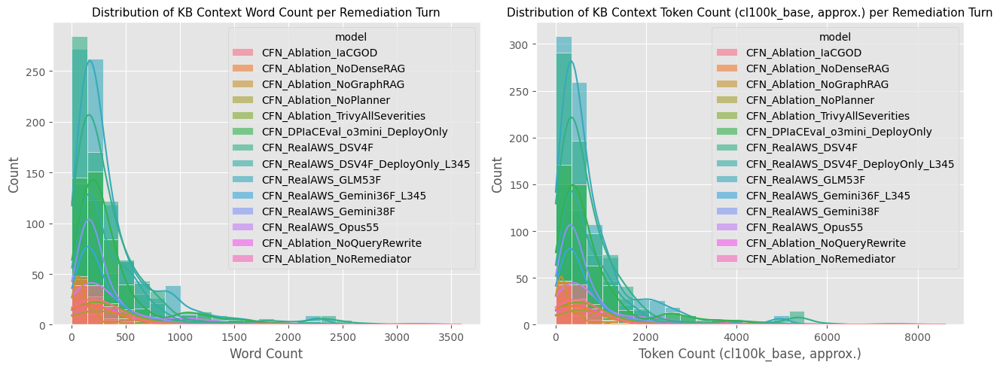

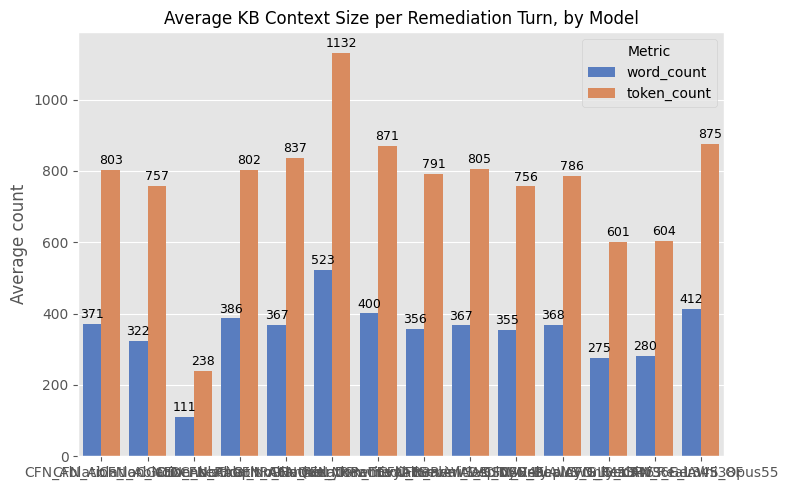

None

In [35]:
try:
    import tiktoken
    _KB_ENC = tiktoken.get_encoding("cl100k_base")
    def _count_tokens(text: str) -> int:
        return len(_KB_ENC.encode(text)) if text else 0
except ImportError:
    print("⚠️ tiktoken not installed -- token counts will be NaN (word counts still work). pip install tiktoken.")
    def _count_tokens(text: str) -> float:
        return float("nan")

kb_context_rows = []
for model_name, df in merged_dataframes.items():
    if model_name not in RUN_COVERAGE:
        continue
    located_df = df[RUN_COVERAGE[model_name]].head(MEMORY_SAMPLE_LIMIT)
    for _, row in located_df.iterrows():
        run_dir = RUN_INDEX[row["run_id"]]
        report = load_final_report(run_dir)
        if not report:
            continue
        for entry in report.get("remediation_history", []):
            text = entry.get("retriever_context", "") or ""
            kb_context_rows.append({
                "model": model_name,
                "row_number": row["row_number"],
                "run_id": row["run_id"],
                "iteration": entry["iteration"],
                "char_count": len(text),
                "word_count": len(text.split()),
                "token_count": _count_tokens(text),
                "n_retrieval_queries": len(entry.get("retrieval_queries", []) or []),
            })

def _plot_kb_context_size(selected_models):
    if kb_context_rows:
        kb_df = pd.DataFrame(kb_context_rows)
        kb_df = kb_df[kb_df["model"].isin(selected_models)]
        if kb_df.empty:
            print("⚠️ No knowledge-base context data for the selected model(s).")
            return
        print(f"📊 Knowledge-base context measured across {len(kb_df)} remediation turns "
              f"({kb_df.groupby(['model','row_number']).ngroups} scenarios).")

        summary = kb_df.groupby("model")[["word_count", "token_count", "char_count", "n_retrieval_queries"]].agg(["mean", "median"])
        display(summary.round(1))

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        for ax, col, label in zip(axes, ["word_count", "token_count"], ["Word Count", "Token Count (cl100k_base, approx.)"]):
            sns.histplot(data=kb_df, x=col, hue="model", bins=25, ax=ax, kde=True, alpha=0.6)
            ax.set_title(f"Distribution of KB Context {label} per Remediation Turn", fontsize=11)
            ax.set_xlabel(label)
        plt.tight_layout()
        plt.show()

        avg_by_model = kb_df.groupby("model")[["word_count", "token_count"]].mean().reset_index()
        avg_plot = avg_by_model.melt(id_vars="model", var_name="Metric", value_name="Average")
        plt.figure(figsize=(8, 5))
        ax = sns.barplot(data=avg_plot, x="model", y="Average", hue="Metric")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=9, padding=2)
        plt.title("Average KB Context Size per Remediation Turn, by Model", fontsize=12)
        plt.ylabel("Average count")
        plt.xlabel("")
        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ No knowledge-base context data found -- check RUN_INDEX/RUN_COVERAGE above "
              "(needs the sibling IaCGOD run logs for these row_numbers on disk).")

_out_kb_context_size = widgets.interactive_output(_plot_kb_context_size, {'selected_models': model_selector})
display(_out_kb_context_size)

In [36]:
DEBUG_KB_MODEL = None
DEBUG_KB_ROW_NUMBER = None
DEBUG_KB_ITERATION = None

if kb_context_rows:
    debug_model = DEBUG_KB_MODEL or kb_context_rows[0]["model"]
    candidates = [r for r in kb_context_rows if r["model"] == debug_model]
    if DEBUG_KB_ROW_NUMBER is not None:
        candidates = [r for r in candidates if r["row_number"] == DEBUG_KB_ROW_NUMBER]
    if DEBUG_KB_ITERATION is not None:
        candidates = [r for r in candidates if r["iteration"] == DEBUG_KB_ITERATION]
    nonempty = [r for r in candidates if r["char_count"] > 0]
    candidates = nonempty or candidates

    if not candidates:
        print("⚠️ No matching (model, row_number, iteration) found.")
    else:
        picked = candidates[0]
        run_dir = RUN_INDEX[picked["run_id"]]
        report = load_final_report(run_dir)
        entry = next(e for e in report["remediation_history"] if e["iteration"] == picked["iteration"])
        text = entry.get("retriever_context", "") or ""

        print(f"Model: {picked['model']} | row_number: {picked['row_number']} | "
              f"run_id: {picked['run_id']} | iteration: {picked['iteration']}")
        print(f"Run dir: {run_dir.resolve()}")
        print(f"Retrieval queries: {entry.get('retrieval_queries')}")
        print(f"\nchar_count={len(text)}  word_count={len(text.split())}  token_count={_count_tokens(text)}\n")
        print("─" * 80)
        print(text[:4000] + ("\n... [truncated]" if len(text) > 4000 else ""))
        print("─" * 80)
else:
    print("No KB context data to debug -- run the previous cell first.")

Model: CFN_Ablation_IaCGOD | row_number: 5 | run_id: 20260928_223453_7a1424f6 | iteration: 1
Run dir: /Users/iksena/Documents/research/IaCGOD/runs/Ablation_IaCGOD_CFN_runs/20260928_223453_7a1424f6
Retrieval queries: ['AWS::Logs::ResourcePolicy PolicyDocument property required type String JSON policy document', 'AWS::Logs::ResourcePolicy example CloudFormation template PolicyName PolicyDocument stringified JSON', 'AWS::Logs::ResourcePolicy PolicyDocument Fn::Sub JSON string serialization escaping quotes', 'CloudFormation E3012 primitive type validation PolicyDocument expects string not object', 'AWS::Logs::ResourcePolicy PolicyDocument with Fn::GetAtt log group Arn inside JSON string via Fn::Sub']

char_count=648  word_count=80  token_count=133

────────────────────────────────────────────────────────────────────────────────
## Official AWS CloudFormation Schema Context


### Semantically Matched Properties
#### AWS::Logs::ResourcePolicy

### AWS::Logs::ResourcePolicy
> Creates or updat